# Stage 3: Multivariate analysis (several variables at once)

**Status (2026-11-03): under way**, begun on the owner's word (A32), starting with the methods the final review of
Stages 1 and 2 listed (A29) and including the check of firms' IP counts by name (A30, ADR 0045). The method is ADR
0046. The evidence atlas (the website) is frozen while Stage 3 runs (A32): nothing here changes it, and notebooks 1
and 2 stay as reviewed. Where Stage 3 changes the reading of an earlier observation, its M observation says so, and
the change waits in the handover's list for the atlas.

**Reviewed (2026-11-03, A33, ADR 0048).** At the owner's request, all three stages were checked for gaps: every
Stage 2 signal carried here, every source and every column. Section 0's table had listed every carried signal as
taken up when eighteen were not; each now has its section, marked "added" (M26 to M38, with B49's renewal test at
each anniversary and the attachments read beyond their gradients). M1 and M16 are corrected where they are. A fault
in the helper for yes or no outcomes (a meaningless interval when two held factors repeat each other) is fixed, and
the notebook re-run in full: no earlier figure changed.

**Purpose.** Stage 2 found pairs of variables that move together and named, for each, the other factors that might
explain it (its *third factors*). Stage 3 looks at several variables at once to ask two things: **does each signal
survive when its third factors are held together**, and **what structure is there**: which characteristics of places,
countries, industries and institutions carry much the same information, and whether there are distinct kinds of them.
It ends with the two tables the plan asks for: early signals worth investigating, and gaps in the data.

**What it cannot do.** Holding measured factors fixed is not an experiment: factors the data does not hold can still
explain an association, and some associations may run backwards. Every finding here is observational or descriptive.
Effects need the designs that follow the EDA (natural experiments, for example), which Stage 3 can point to but not
supply.

## How to read this notebook

- **Every observation is evidenced.** Observations are numbered (**M1**, **M2**, ...) and quote the numbers from the
  output cells directly above them. If a number is not on the page, it is not a finding.
- **Each observation is labelled with its strength of evidence**, as the research goal requires: *descriptive* (what
  the data shows), *observational* (an association that may have other explanations), *causal* (an effect, which needs
  a design this EDA does not have) or *projected* (an estimate of the future). Everything in Stage 3 is descriptive or
  observational.
- **Plain English first.** Technical terms are explained where they first appear and in
  [`GLOSSARY.md`](../../GLOSSARY.md). Every chart names its source underneath it.
- **Raw, then held together.** Each signal is shown twice: as Stage 2 measured it (the **raw** figure), and with its
  third factors **held together** in one model (the **adjusted** figure). The difference between them is how much of
  the signal those factors account for. Four words describe what is left (ADR 0046):
  - **holds**: same direction, its 95% interval clear of zero, and at least half of the raw size left;
  - **weakened**: same direction and clear of zero, but less than half left;
  - **not detected once held**: the interval includes zero (which is not the same as no association);
  - **reversed**: the other direction, clear of zero;
  - and where the raw association was not detected (its interval includes zero): **appears once held** if the
    adjusted one is clear of zero, **not detected either way** if not.
- **Figures come in pairs**, as in Stage 2: a result is found in one sample and checked in a second. For rights the
  samples are two decades (FY2010 to FY2019, then FY2000 to FY2009), except where a measure is reliable only from
  FY2010 (family reach and citations, B55), when they are the two halves of FY2010 to FY2019; for firms and places,
  the lens's two halves (a fixed random split by a hash of the key); for countries, divisions and institutions, two
  periods of the same units, which is a **stability check**, not a replication. Unless an observation labels them, a
  pair is the first sample, then the second. A range in brackets with "interval" is a 95% interval.
- **Intervals** come from the model, with **clustered** standard errors where one filer has many rows (a filer's
  rights are not independent of each other), or from 1,000 resamples of the independent unit (the final review's
  request, A29). Quarterly series are resampled in blocks of consecutive quarters.
- **Unit of analysis.** Each section works on one *lens*, a table with one row per thing being described, defined in
  [`analysis/eda/build.py`](../eda/build.py) and described column by column in
  [`analysis/eda/variables.yaml`](../eda/variables.yaml). Stage 1's rules for using each column
  (`docs/stage-1-summary.md`, section 6) and Stage 2's wording rules (ADR 0043) apply here.

## 0. How Stage 3 works

**The signals carried from Stage 2** (notebook 2, section 8), where each is taken up, and the third factors named for
it:

| Stage 2 signal | Section | Third factors held together |
|---|---|---|
| B6, B10: filing alone and outcomes | 1.1, 1.2 | the filer's type, the route of filing, the technology field or class, the year, the state, joint filing, the number of classes |
| B8, B11, B12, B55: reach, citations and the share in force, by origin | 1.3 | family reach, the technology field, the route, the cohort, joint filing |
| B13: expedited examination and the share in force | 1.4 | the filer, the field, the route, the cohort |
| B15: divisionals | 1.7 (added) | the field, joint filing, the number of classes; within the same filers |
| B16: inventions made here, filed from overseas | 1.8 (added) | inventors abroad, the field, reach, inventors here, joint filing |
| B19: Australian-founded patents now held only overseas | 1.5 | reach, grant, the filer's type, the field, the period |
| B17, B18: women among inventors | 1.6 | the field, the filer, the year |
| B49 (its own request): renewal at each anniversary | 1.9 (added) | the trend either side, the anniversary, the filer, the field |
| B22, B23: who files among R&D claimants | 2.1 | spend, company form, age, place |
| B24: suppliers' contracts | 2.2 | form, age, place |
| B25: which comes first | 2.3 | cohorts instead of a window |
| B50, B51: size and industry | 2.4 | size, the division |
| B22, B24: who files among suppliers; large taxpayers' income | 2.6 (added) | form, age, place, state |
| B26: the filing firm's age and patents now held overseas | 2.7 (added) | grant, reach, field, route, year |
| B27 to B30: where filing happens | 3.1 to 3.4 | advantage, education, income, remoteness and business density, reduced to components first |
| B31, B58, B59: business mix, incomes, change | 3.5 (added) | the components and remoteness; for change, the 2011 levels |
| B28: every attached indicator | 3.6 (added) | the components and remoteness |
| B32 to B34: countries | 4.1, 4.2 | R&D, income and size, as components |
| B35: the cross-country attachments | 4.3 (added) | income and size |
| B36, B39: quarterly changes | 5.1 | block resampling |
| B37: policy breaks | 5.3 | trend and season |
| B47, B49: fee breaks | 5.4 (added) | trend and season, controls |
| B38: the FY2025 provisionals | 5.5 (added) | the filer's state, volume and history, the month |
| B52, B56, B63: the cycle, labour, courts | 5.6 (added) | block resampling; the other cycle measure |
| B40, B42, B53, B54, B60: industries | 6.1, 6.2 | businesses, business R&D, value added and the crosswalk |
| B43: the division-level indicators | 6.3 (added) | size and value added (B57's measure) |
| B45, B62: universities; commercialisation | 7.1, 7.2 | size, research output and research spend |
| B44, B46: every kind of institution | 7.3 (added) | kind, size, citations, NHMRC grants |

**Corrected in the review of 3 November 2026** (A33, ADR 0048): this table listed every carried signal as taken up,
but the first pass took up B6 to B13, B17 to B19, B22 and B23 among R&D claimants, B24's contracts, B25, B27 to B30,
B32 to B34, B36, B37, B39, B40, B42, B45, B50 to B54, B60 and B62 only. B15, B16, B22 among suppliers, B24's large
taxpayers, B26, B28's attachments, B31, B35, B38, B43, B44, B46, B47, B49, B52, B56, B58 and B59 had no Stage 3
treatment (B57's value added was held in 6.2), nor did B49's own request (renewal at each right's anniversary). Each now has its section, marked "added",
and the review added B63 in notebook 2 (the Labour Force Survey and the IP judgments, newly in the timeline).

**The methods the final review listed (A29)**, and where each is used: block resampling and effective sample sizes
for quarterly changes (5.1, and 5.6 for B52, B56 and B63, added in the review); 1,000 or more resamples for every quoted bootstrap interval (throughout); B42 and B60
through the crosswalk with services (6); fixed-age windows for citations (1.3 and 7, from citations within five years
of priority); research spend as an exposure for B62 (7); the window-free within-firm order for B25 (2); the
party-aligned filer for B30 (3) and, in this notebook, for clustering (1); legends on every correlation map
(throughout); and models that hold the named third factors together (throughout).

**The models.** A yes or no outcome for each right or firm (granted, still in force, a filing linked) is modelled by
logistic regression and reported as an **average marginal effect**: the difference, in percentage points, between the
predicted chance of the outcome with the signal and without it, averaged over the rows with their other factors as
they are. A count with an exposure (filing per resident) is modelled as a **negative binomial**, as in B29, and
reported as a rate ratio. The small lenses use **partial rank correlations**: the correlation of two variables'
ranks once what the third factors explain is removed from both. Where many characteristics repeat each other (places,
countries), **principal components** summarise them first, and the components are held fixed instead of the
twenty measures behind them.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import bivariate as bi
from eda import multivariate as multi
from eda import sql, style

style.setup()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
# the columns shown for every adjusted effect (multi.adjusted_effect)
EFFECT = ["rows", "share with signal", "share without", "raw", "raw low", "raw high", "adjusted", "adjusted low",
          "adjusted high", "share of raw remaining", "rows merged", "verdict"]  # fmt: skip

## 1. Lens: IP rights (one row per right)

Stage 2's shorthands carry over: **who filed** is the origin and type of one party, the first founding applicant in
Australia, else the first with a known country (`filer_group`, ADR 0037), and the **two decades** are FY2010 to FY2019
and FY2000 to FY2009. Stage 3 adds that party's **id** (from IP RAPID's parties, by the same rule), so that a filer's
rights can be treated as one cluster: a firm that files thousands of applications is one filer, not thousands of
independent cases. This is the "party-aligned filer" the final review asked for.

In [2]:
FILER = "replace(replace(filer_group, 'australian_', 'Australian '), 'overseas_', 'overseas ') || 's'"
PERIOD = (
    "CASE WHEN filing_fy BETWEEN 2010 AND 2019 THEN 'FY2010-FY2019'"
    " WHEN filing_fy BETWEEN 2000 AND 2009 THEN 'FY2000-FY2009' END"
)
# the filer's party id, by filer_group's rule (build.rights_sql): each founding applicant or owner as first recorded,
# then the first in Australia by (date, party id), else the first with a known country
FILER_PARTY = """filer_party AS (
    SELECT ip_right_type, application_number,
           coalesce(arg_min_null(party_id, (since, party_id)) FILTER (country_code = 'au'),
                    arg_min_null(party_id, (since, party_id)) FILTER (country_code IS NOT NULL)) AS filer_party,
           coalesce(arg_min_null(party_type, (since, party_id)) FILTER (country_code = 'au'),
                    arg_min_null(party_type, (since, party_id)) FILTER (country_code IS NOT NULL)) AS party_type
    FROM (
        SELECT ip_right_type, application_number, party_id, party_type, country_code, effective_from_date AS since,
               row_number() OVER (PARTITION BY ip_right_type, application_number, party_id
                                  ORDER BY effective_from_date, country_code NULLS LAST, post_code NULLS LAST,
                                           state_code NULLS LAST) AS k
        FROM {iprapid/party}
        WHERE party_role_category IN ('applicant', 'owner') AND is_founding
    ) WHERE k = 1
    GROUP BY ALL
)"""


def rsql(q, **kw):
    # sql() with the shorthands @FILER (who filed), @PERIOD (the two decades) and @FILER_PARTY (the filer's party)
    return sql(q.replace("@FILER_PARTY", FILER_PARTY).replace("@FILER", FILER).replace("@PERIOD", PERIOD), **kw)


REACH = (
    "CASE WHEN family_offices = 1 THEN 'Australia only' WHEN family_offices BETWEEN 2 AND 4 THEN 'two to four offices'"
    " WHEN family_offices >= 5 THEN 'five or more offices' ELSE 'reach unknown' END"
)
DOP_FY = "(year(date_of_patent) + (month(date_of_patent) >= 7)::INT)"
ORG_COLUMNS = f"""
    (filer_group = 'australian_organisation')::INT AS australian, {REACH} AS reach,
    coalesce(main_area, 'unknown') AS field, coalesce(filing_route, 'unknown') AS route,
    CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
    CASE WHEN class_count IS NULL THEN 'unknown' WHEN class_count = 1 THEN '1' WHEN class_count <= 3 THEN '2-3'
         ELSE '4+' END AS classes,
    coalesce(filer_party, application_number) AS filer_party"""
ORGS = "patent_type = 'standard' AND filer_group IN ('australian_organisation', 'overseas_organisation')"
HALF = bi.half_sql("application_number")


def org_rows(select, where):
    return rsql(f"""
        WITH @FILER_PARTY
        SELECT {ORG_COLUMNS}, {select}
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE {ORGS} AND {where}
        ORDER BY hash(application_number || 'stage3'), application_number
        LIMIT 200000
    """)


# Patents' lifetimes (1.3, 1.4), as Stage 2's curves read them (ADR 0041): granted standard patents, each joining the
# count at its grant (delayed entry), years from the date of patent, followed to 10 years
LIFE = "years_in_force >= 0 AND in_force IS NOT NULL AND (in_force OR retired_date >= registered_date)"
LIFETIME = (
    "years_in_force AS t, (NOT in_force)::INT AS ended,"
    " greatest(date_diff('day', date_of_patent, registered_date) / 365.25, 0) AS entry"
)


# check: the party found by the rule has the type filer_group gives, for every right with a filer
check = rsql("""
    WITH @FILER_PARTY
    SELECT count(*) AS rights_with_a_filer, count(filer_party) AS with_a_party,
           avg((split_part(filer_group, '_', 2) = party_type)::INT) AS type_agrees
    FROM {lens/rights} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
    WHERE filer_group IS NOT NULL
""")
check

,rights_with_a_filer,with_a_party,type_agrees
0,3769615,3769615,1


### 1.1 Filing alone and what comes of it, with the filer's other characteristics held together

**Revisits:** B6. **Informs:** Q2, Q4. Stage 2 found that Australian individuals' standard patents filed without an
attorney are granted about 36 points less often, in both decades and among examined applications too, and that
Australians' trade marks with an attorney are registered about 24 points more often. Its candidate third factors were
the route of filing and the filer's other characteristics. Here each gap is modelled with them held together.

**What is held fixed, and what is not.** Only what is settled when the application is filed: the **route** (PCT,
convention priority, an Australian priority, divisional, direct), the **filing year**, the founding applicant's
**state** and whether there are **several founding applicants**; for trade marks also the **Nice class** and the
**number of classes**, which the applicant chooses at filing. For patents, the technology field and the number of IPC
classes are not settled at filing: they are assigned as the application is classified, and an application abandoned
early may never be (37% of individuals' lone standard patents have no field, against none with an attorney). Holding
them fixed would hold part of the outcome fixed, so they are a **second reading** among applications that have a
field (the rows marked "with a field", which hold the field and the number of classes too). Whether **examination was requested** is a third reading, as in B6: it follows the choice to file alone.

Decided years only (filed FY2000 to FY2019), filed alone or with an attorney (agents who are not attorneys left out, as
in B6); standard errors clustered by the filer's party. Trade marks are capped at 200,000 rights in each group and
decade, chosen by a hash of the application number, as Stage 2's screens were.

In [3]:
REP_COLUMNS = """
    (registered_date IS NOT NULL)::INT AS granted, (representation = 'self')::INT AS alone,
    (exam_requested_date IS NOT NULL)::INT AS examined,
    coalesce(filing_route, 'unknown') AS route,
    coalesce(CASE WHEN ip_right_type = 'patent' THEN main_area ELSE main_class END, 'unknown') AS field,
    filing_fy, coalesce(founder_state, 'unknown') AS state,
    CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
    CASE WHEN class_count IS NULL THEN 'unknown' WHEN class_count = 1 THEN '1' WHEN class_count <= 3 THEN '2-3'
         ELSE '4+' END AS classes,
    coalesce(filer_party, application_number) AS filer_party"""
AT_FILING = ["route", "filing_fy", "state", "founders"]
TYPES = {
    "standard": "Standard patents (granted)",
    "trade_mark": "Trade marks (registered)",
}
WHO = {
    "australian_individual": "Australian individuals",
    "australian_organisation": "Australian organisations",
}
rows, sizes = [], []
for t, tname in TYPES.items():
    for fg, who in WHO.items():
        for lo, hi in ((2010, 2019), (2000, 2009)):
            d = rsql(f"""
                WITH @FILER_PARTY
                SELECT {REP_COLUMNS}
                FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
                WHERE coalesce(patent_type, ip_right_type) = '{t}' AND filer_group = '{fg}'
                  AND filing_fy BETWEEN {lo} AND {hi} AND representation IN ('self', 'attorney')
                ORDER BY hash(application_number || 'stage3'), application_number
                LIMIT 200000
            """)
            name = f"{tname}: {who}, FY{lo}-FY{hi}"
            lone = d.loc[d.alone == 1, "filer_party"].value_counts()
            sizes.append(
                {
                    "rights": name,
                    "rows": len(d),
                    "filers": d.filer_party.nunique(),
                    "filed alone": d.alone.sum(),
                    "filers filing alone": len(lone),
                    "top 10 lone filers' share": lone.head(10).sum() / lone.sum(),
                }
            )
            if t == "trade_mark":
                readings = {"": (d, AT_FILING + ["field", "classes"])}
            else:
                readings = {
                    "": (d, AT_FILING),
                    ", with a field": (
                        d[d.field != "unknown"],
                        AT_FILING + ["field", "classes"],
                    ),
                    ", examined": (d[d.examined == 1], AT_FILING),
                }
            for suffix, (sub, controls) in readings.items():
                r = multi.adjusted_effect(sub, "granted", "alone", controls, cluster="filer_party")
                rows.append(r.rename(name + suffix))
rep = pd.DataFrame(rows)
display(pd.DataFrame(sizes).set_index("rights").round(3))
rep[EFFECT].round(3)

,rows,filers,filed alone,filers filing alone,top 10 lone filers' share
rights,,,,,
"Standard patents (granted): Australian individuals, FY2010-FY2019",6041,4995,1642,1370,0.072
"Standard patents (granted): Australian individuals, FY2000-FY2009",7024,5975,1590,1374,0.034
"Standard patents (granted): Australian organisations, FY2010-FY2019",19290,7533,685,543,0.101
"Standard patents (granted): Australian organisations, FY2000-FY2009",16266,6619,1149,392,0.598
"Trade marks (registered): Australian individuals, FY2010-FY2019",101050,67608,76640,52821,0.008
"Trade marks (registered): Australian individuals, FY2000-FY2009",67102,46248,53201,38104,0.011
"Trade marks (registered): Australian organisations, FY2010-FY2019",200000,88426,86046,47674,0.028
"Trade marks (registered): Australian organisations, FY2000-FY2009",200000,74932,92879,47015,0.028


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"Standard patents (granted): Australian individuals, FY2010-FY2019",6041,0.048,0.406,-0.358,-0.378,-0.338,-0.312,-0.34,-0.284,0.872,21,holds
"Standard patents (granted): Australian individuals, FY2010-FY2019, with a field",5426,0.077,0.406,-0.329,-0.354,-0.305,-0.272,-0.305,-0.239,0.828,193,holds
"Standard patents (granted): Australian individuals, FY2010-FY2019, examined",3751,0.191,0.535,-0.344,-0.39,-0.299,-0.305,-0.359,-0.251,0.886,9,holds
"Standard patents (granted): Australian individuals, FY2000-FY2009",7024,0.083,0.451,-0.368,-0.389,-0.348,-0.317,-0.345,-0.29,0.862,0,holds
"Standard patents (granted): Australian individuals, FY2000-FY2009, with a field",6593,0.114,0.451,-0.338,-0.362,-0.313,-0.278,-0.31,-0.247,0.824,140,holds
"Standard patents (granted): Australian individuals, FY2000-FY2009, examined",4630,0.256,0.596,-0.339,-0.382,-0.296,-0.291,-0.34,-0.242,0.858,21,holds
"Standard patents (granted): Australian organisations, FY2010-FY2019",19290,0.098,0.498,-0.4,-0.456,-0.344,-0.353,-0.406,-0.3,0.883,0,holds
"Standard patents (granted): Australian organisations, FY2010-FY2019, with a field",19013,0.164,0.498,-0.333,-0.403,-0.264,-0.279,-0.338,-0.219,0.836,22,holds
"Standard patents (granted): Australian organisations, FY2010-FY2019, examined",16249,0.324,0.577,-0.253,-0.357,-0.149,-0.232,-0.311,-0.154,0.919,19,holds
"Standard patents (granted): Australian organisations, FY2000-FY2009",16266,0.621,0.56,0.06,-0.302,0.423,0.06,-0.185,0.306,1.005,18,not detected either way


### 1.2 No agent before the first renewal, and the share in force after it, with other factors held together

**Revisits:** B10. **Informs:** Q2, Q4. Stage 2 found that Australians' trade marks with no agent before the first
renewal are less often in force after it (31.7% against 50.8% with an attorney), and designs likewise at their one
renewal. The definitions are B10's (ADR 0041): a right is counted if it was registered, its cohort is the financial
year its term began (its earliest filing date), "no agent before the renewal" means filed alone or with an agent first
recorded after the renewal fell due (9.5 years after filing for trade marks, 4.5 for designs), and it is compared with
an attorney recorded before the renewal (other agents left out). "In force after 10 years" (trade marks) or "after 5
years" (designs) is a yes or no for each right, with its end rounded to a tenth of a year as Stage 2's curves were;
every cohort here has had the full time, so no right is cut short.

**Held together:** the filer's **type** (individual or organisation), the **class** (Nice for trade marks, Locarno for
designs), the **number of classes**, the **state**, **several founding applicants**, the **route** and the **cohort
year**, all settled at filing. Trade marks: cohorts FY2010 to FY2015, then FY2003 to FY2009, as in B10. Designs: B5
found that design agents were recorded differently before FY2010, so designs are read in FY2010 to FY2019 only, with
the two halves of those designs as the second sample. Capped at 200,000 rights a sample by the hash, clustered by the
filer's party.

In [4]:
TERM_FY = "(year(earliest_filed_date) + (month(earliest_filed_date) >= 7)::INT)"


def renewal_rows(t, years, cut, where):
    # B10's reading: registered rights of Australian filers, in force after `years` (the first renewal), against
    # whether an agent was recorded before the renewal fell due (`cut` years after filing)
    late = f"date_diff('day', earliest_filed_date, agent_first_date) / 365.25 > {cut}"
    return rsql(f"""
        WITH @FILER_PARTY
        SELECT (round(years_in_force, 1) > {years})::INT AS in_force_after,
               (representation = 'self' OR agent_first_date IS NULL OR {late})::INT AS no_agent_before,
               split_part(filer_group, '_', 2) AS filer_type, coalesce(main_class, 'unknown') AS class_code,
               CASE WHEN class_count = 1 THEN '1' WHEN class_count <= 3 THEN '2-3' ELSE '4+' END AS classes,
               coalesce(founder_state, 'unknown') AS state,
               CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
               coalesce(filing_route, 'unknown') AS route, {TERM_FY} AS cohort,
               coalesce(filer_party, application_number) AS filer_party
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE ip_right_type = '{t}' AND founding_australian AND filer_group IS NOT NULL
          AND representation IS NOT NULL AND years_in_force >= 0 AND in_force IS NOT NULL
          AND (in_force OR retired_date >= registered_date)
          AND (representation = 'self' OR agent_first_date IS NULL OR {late} OR representation = 'attorney')
          AND {where}
        ORDER BY hash(application_number || 'stage3'), application_number
        LIMIT 200000
    """)


RENEW_CONTROLS = ["filer_type", "class_code", "classes", "state", "founders", "route", "cohort"]
samples = {
    "Trade marks after 10 years, FY2010-FY2015": ("trade_mark", 10, 9.5, f"{TERM_FY} BETWEEN 2010 AND 2015"),
    "Trade marks after 10 years, FY2003-FY2009": ("trade_mark", 10, 9.5, f"{TERM_FY} BETWEEN 2003 AND 2009"),
    "Designs after 5 years, FY2010-FY2019, first half": (
        "design",
        5,
        4.5,
        f"{TERM_FY} BETWEEN 2010 AND 2019 AND {bi.half_sql('application_number')}",
    ),
    "Designs after 5 years, FY2010-FY2019, second half": (
        "design",
        5,
        4.5,
        f"{TERM_FY} BETWEEN 2010 AND 2019 AND NOT {bi.half_sql('application_number')}",
    ),
}
rows = []
for name, (t, years, cut, where) in samples.items():
    d = renewal_rows(t, years, cut, where)
    r = multi.adjusted_effect(d, "in_force_after", "no_agent_before", RENEW_CONTROLS, cluster="filer_party")
    rows.append(r.rename(name))
    for ft, sub in d.groupby("filer_type"):  # within each filer type too
        r = multi.adjusted_effect(sub, "in_force_after", "no_agent_before", RENEW_CONTROLS, cluster="filer_party")
        rows.append(r.rename(f"{name}, {ft}s"))
renew = pd.DataFrame(rows)
renew[EFFECT].round(3)

,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"Trade marks after 10 years, FY2010-FY2015",137443,0.317,0.508,-0.191,-0.201,-0.18,-0.144,-0.154,-0.134,0.755,1,holds
"Trade marks after 10 years, FY2010-FY2015, individuals",30586,0.223,0.356,-0.133,-0.148,-0.117,-0.118,-0.133,-0.103,0.887,59,holds
"Trade marks after 10 years, FY2010-FY2015, organisations",106857,0.368,0.527,-0.16,-0.172,-0.147,-0.151,-0.163,-0.139,0.946,0,holds
"Trade marks after 10 years, FY2003-FY2009",143090,0.345,0.497,-0.153,-0.164,-0.142,-0.11,-0.121,-0.099,0.722,0,holds
"Trade marks after 10 years, FY2003-FY2009, individuals",29487,0.253,0.394,-0.141,-0.16,-0.123,-0.12,-0.138,-0.103,0.853,55,holds
"Trade marks after 10 years, FY2003-FY2009, organisations",113603,0.387,0.509,-0.122,-0.135,-0.109,-0.108,-0.121,-0.096,0.886,0,holds
"Designs after 5 years, FY2010-FY2019, first half",11472,0.3,0.467,-0.167,-0.259,-0.075,-0.163,-0.206,-0.119,0.974,109,holds
"Designs after 5 years, FY2010-FY2019, first half, individuals",1971,0.219,0.385,-0.166,-0.22,-0.112,-0.134,-0.189,-0.079,0.805,200,holds
"Designs after 5 years, FY2010-FY2019, first half, organisations",9501,0.327,0.48,-0.154,-0.266,-0.041,-0.168,-0.218,-0.117,1.091,122,holds
"Designs after 5 years, FY2010-FY2019, second half",11341,0.324,0.468,-0.145,-0.236,-0.053,-0.141,-0.188,-0.094,0.976,75,holds


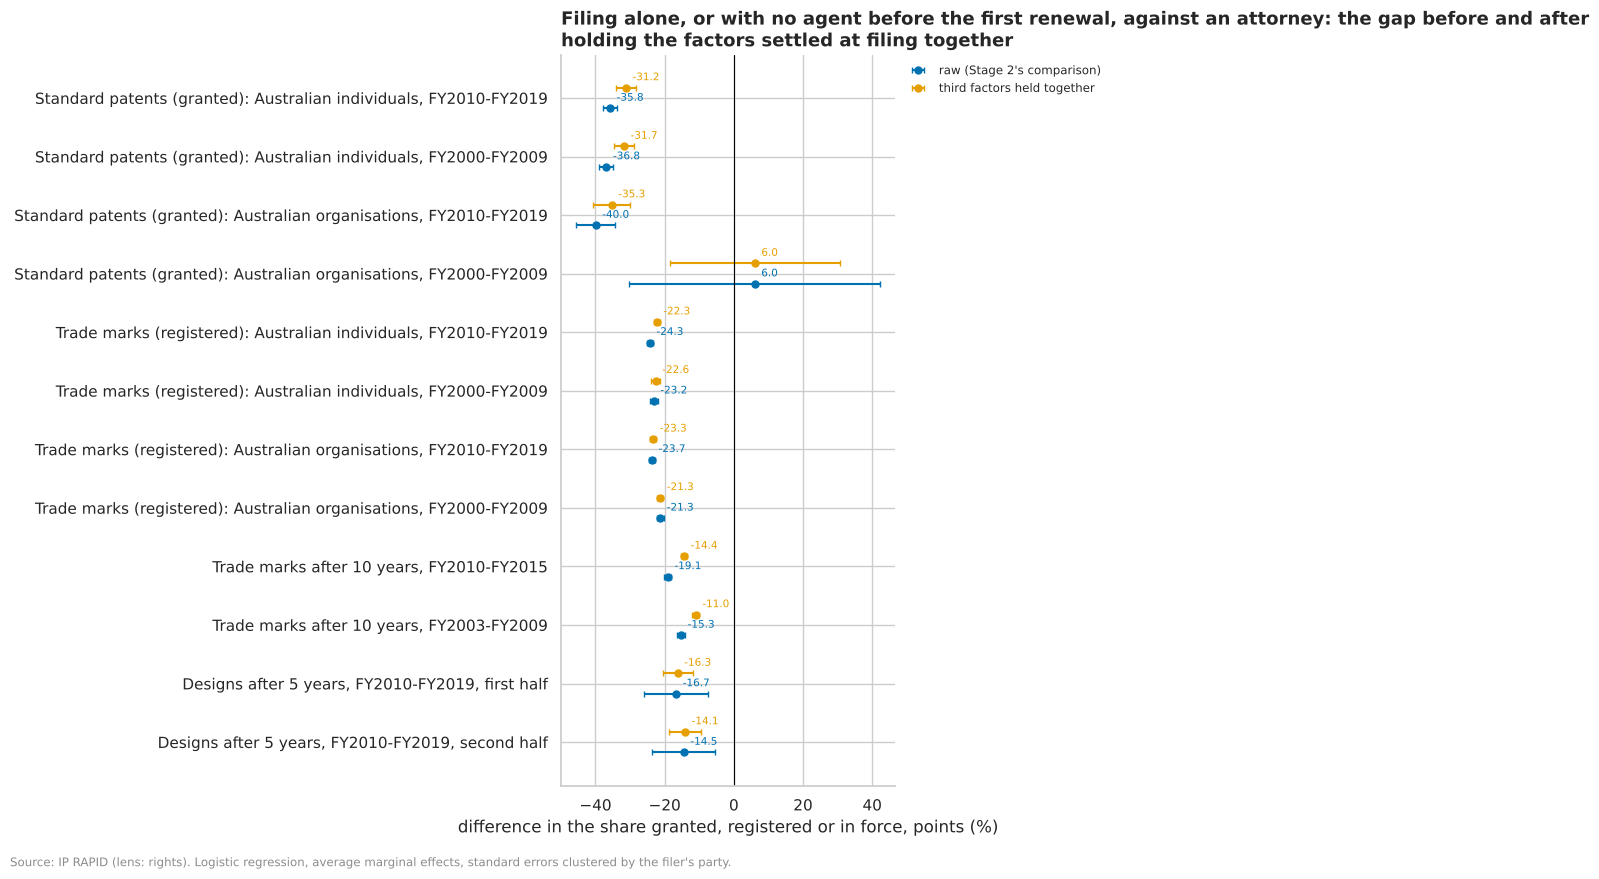

In [5]:
# the main reading of each sample (the rows with a field, examined or by filer type are in the tables above)
main = pd.concat([rep, renew])
main = main[~main.index.str.contains(", with a field|, examined|, individuals$|, organisations$", regex=True)]
fig = multi.effects_chart(
    main,
    title="Filing alone, or with no agent before the first renewal, against an attorney: the gap before and after\n"
    "holding the factors settled at filing together",
    xlabel="difference in the share granted, registered or in force, points",
    raw_name="raw (Stage 2's comparison)",
)
style.source(
    fig,
    "IP RAPID (lens: rights). Logistic regression, average marginal effects, standard errors clustered by the filer's"
    " party.",
)

#### Observations

**M1 (observational). Standard patents filed alone are granted far less often, and most of the gap stays when the
factors settled at filing are held together, for Australian individuals in both decades; trade marks likewise for
individuals and organisations.** Difference in the share granted or registered, filed alone minus with an attorney,
in points (raw; with the route, filing year, state and founders held together), with 95% intervals clustered by the
filer:
- **Australian individuals' standard patents:** FY2010 to FY2019, raw -35.8 (-37.8 to -33.8), held together -31.2
  (-34.0 to -28.4), 87.2% of the raw gap remaining; FY2000 to FY2009, -36.8 (-38.9 to -34.8) and -31.7 (-34.5 to
  -29.0), 86.2%. **Holds** in both decades. Among applications with a field, with the field and number of classes
  held too: -27.2 (-30.5 to -23.9) and -27.8 (-31.0 to -24.7). Among examined applications: -30.5 (-35.9 to -25.1)
  and -29.1 (-34.0 to -24.2).
- **Australian organisations' standard patents** hold in FY2010 to FY2019 (raw -40.0, -45.6 to -34.4; held together
  -35.3, -40.6 to -30.0), but not in FY2000 to FY2009: raw +6.0 (-30.2 to 42.3), held together +6.0 (-18.5 to 30.6),
  **not detected either way** (the raw interval includes zero too; corrected 3 November 2026 in the review: this
  read "not detected once held", which the table's verdict does not give); among examined applications that decade, alone is granted more often (+17.2, 0.6 to
  33.8). Clustering shows why the earlier decade differs: its 1,149 lone applications came from 392 filers, the ten
  largest filing 59.8% of them, against 10.1% of the later decade's 685 (543 filers). B6's guess that these were
  firms with their own patent staff fits a few heavy filers, but the data do not say who they were.
- **Trade marks** (with the Nice class and number of classes held too): Australian individuals -24.3 raw, -22.3
  (-23.2 to -21.5) held together, then -23.2 and -22.6 (-23.8 to -21.4); Australian organisations -23.7 and -23.3
  (-24.1 to -22.6), then -21.3 and -21.3 (-22.2 to -20.4). **Holds** in both decades, 91.9% to 99.9% remaining: the
  route, class, year, state and filers' number account for almost none of it.
- Lone filing is spread thinly: the ten heaviest lone filers hold 0.8% to 10.1% of the lone filings in every group but
  the older organisations', so the gap is not a few filers' (Australian individuals' patents: 1,642 lone applications
  from 1,370 filers).
- **Not a cause.** What is held fixed is what is known at filing; the filer's resources, experience and the merit of
  the invention are not in the data, and an application dropped early may never appoint an attorney (the arrow can run
  backwards, B6). The signal for Q4 is that the gap is not explained by the route, year, place, field or co-filers.

**M2 (observational). No agent before the first renewal goes with fewer trade marks and designs in force after it,
and most of the gap stays with the factors settled at filing held together, within individuals and organisations
alike.** Difference in the share in force after the renewal, no agent before it minus an attorney before it, in
points (raw; with the filer's type, class, number of classes, state, founders, route and cohort held together):
- **Trade marks after 10 years:** FY2010 to FY2015, 31.7% against 50.8%, raw -19.1 (-20.1 to -18.0), held together
  -14.4 (-15.4 to -13.4), 75.5% remaining; FY2003 to FY2009, 34.5% against 49.7%, -15.3 and -11.0 (-12.1 to -9.9),
  72.2%. **Holds** in both. Within each filer type it holds more fully (85.3% to 94.6% remaining): individuals -11.8
  (-13.3 to -10.3) and -12.0 (-13.8 to -10.3), organisations -15.1 (-16.3 to -13.9) and -10.8 (-12.1 to -9.6). Part
  of the pooled gap is who files alone (individuals, whose marks are less often in force either way: 22.3% and 35.6%
  in FY2010 to FY2015).
- **Designs after 5 years** (FY2010 to FY2019, first half then second): 30.0% against 46.7%, raw -16.7 (-25.9 to
  -7.5), held together -16.3 (-20.6 to -11.9); 32.4% against 46.8%, -14.5 and -14.1 (-18.8 to -9.4). **Holds** in both
  halves, 97.4% and 97.6% remaining, and within individuals (-13.4 and -13.3) and organisations (-16.8 and -13.9).
- B10's raw figures are reproduced (31.7% against 50.8%). **Not a cause:** an owner who means to let a mark go may
  not appoint an agent before the renewal, so the arrow can run backwards here too; and a share in force is not a
  renewal decision or value (U36, ADR 0041).

### 1.3 Reach, citations and the share in force, by origin, with field, route and cohort held together

**Revisits:** B8, B11, B12, B55. **Informs:** Q1. Stage 2 found three signals that disagree: Australian organisations'
standard patents reach fewer offices (B11) and are cited less, mostly because of that reach (B12), yet within the same
reach they are more often still in force at 10 years than overseas organisations' (B8, read only within reach bands at
the owner's word, A22). Here each is modelled with the **technology field**, the **route**, the **cohort**, **several
founding applicants** and the **number of classes** held together, and the share in force also with **reach** held.

- **In force to 10 years** (B8): granted standard patents, cohorts by the financial year of the date of patent, FY2010
  to FY2016 (the latest that have reached 10 years), in its two halves; FY2005 to FY2009 is shown as a provisional
  third reading, because older families' reach is incomplete (B55). Read as Stage 2's survival curves read it (ADR
  0041): each patent joins the count at its grant (delayed entry) and is followed from its date of patent to 10 years.
  The model is a **proportional hazards (Cox) model**, reported as a **hazard ratio**: the chance that a patent ends
  in any given year, Australian organisations' against overseas organisations', with the other factors held; 0.8
  means 20% less likely to end, so more often still in force. A hazard ratio is not a difference in shares, so the
  raw figure here is not B8's percentages, but the two read the same way.
- **Reach** (B11): the share of patents filed only in Australia, and in five or more offices, for standard patents
  filed FY2010 to FY2019 with a known family, in its two halves.
- **Citations within five years** (B12, with the final review's fixed-age window): the number of patent families that
  cite the family and were first filed within five years of its first priority, for families first filed by 22 April
  2020, as rate ratios from a negative binomial model (Australian against overseas organisations: 0.8 means 20% fewer
  citations).

Australian against overseas organisations throughout (individuals left out, as in B8); standard errors clustered by
the filer's party.

In [6]:
# (a) in force at 10 years, by origin, pooled with reach held and within each reach band
life_samples = {
    "FY2010-FY2016, first half": f"{DOP_FY} BETWEEN 2010 AND 2016 AND {HALF}",
    "FY2010-FY2016, second half": f"{DOP_FY} BETWEEN 2010 AND 2016 AND NOT {HALF}",
    "FY2005-FY2009 (provisional)": f"{DOP_FY} BETWEEN 2005 AND 2009",
}
LIFE_CONTROLS = ["field", "route", "cohort", "founders", "classes"]
rows, mix = [], []
for name, where in life_samples.items():
    d = org_rows(f"{LIFETIME}, {DOP_FY} AS cohort", f"{LIFE} AND {where}")
    mix.append(
        pd.crosstab(d.australian, d.reach, normalize="index").assign(
            patents=d.groupby("australian").size(), sample=name
        )
    )
    r = multi.adjusted_hazard(
        d, "t", "ended", "entry", "australian", ["reach", *LIFE_CONTROLS], cluster="filer_party", horizon=10
    )
    rows.append(r.rename(f"all reach, reach held: {name}"))
    for band, sub in d.groupby("reach"):
        r = multi.adjusted_hazard(
            sub, "t", "ended", "entry", "australian", LIFE_CONTROLS, cluster="filer_party", horizon=10
        )
        rows.append(r.rename(f"{band}: {name}"))
life = pd.DataFrame(rows)
mix = pd.concat(mix).set_index("sample", append=True)
mix = (100 * mix.drop(columns="patents")).round(1).join(mix.patents)
mix.index = mix.index.set_levels(["overseas organisations", "Australian organisations"], level="australian")
display(mix)
HAZARD = ["rows", "ended", "with signal", "raw", "raw low", "raw high", "adjusted", "adjusted low", "adjusted high",
          "share of raw remaining", "rows merged", "verdict"]  # fmt: skip
life[HAZARD].round(3)

,,Australia only,five or more offices,reach unknown,two to four offices,patents
australian,sample,,,,,
overseas organisations,"FY2010-FY2016, first half",4.6,75.2,0,20.2,59319
Australian organisations,"FY2010-FY2016, first half",22.3,35.7,0.1,42,3212
overseas organisations,"FY2010-FY2016, second half",4.5,75.4,0,20.1,58950
Australian organisations,"FY2010-FY2016, second half",23.5,36.4,0,40.1,3250
overseas organisations,FY2005-FY2009 (provisional),10.4,72.7,NaN,16.9,67676
Australian organisations,FY2005-FY2009 (provisional),52.3,22.2,NaN,25.5,4828


,rows,ended,with signal,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"all reach, reach held: FY2010-FY2016, first half",61566,18650,3157,0.765,0.677,0.864,0.773,0.673,0.887,0.962,19,holds
"Australia only: FY2010-FY2016, first half",3229,637,693,1.1,0.876,1.382,0.959,0.732,1.256,-0.437,148,not detected either way
"five or more offices: FY2010-FY2016, first half",45130,13749,1129,0.728,0.61,0.868,0.71,0.59,0.853,1.08,0,holds
"reach unknown: FY2010-FY2016, first half",19,7,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few rows
"two to four offices: FY2010-FY2016, first half",13188,4257,1333,0.75,0.627,0.899,0.811,0.674,0.977,0.728,39,holds
"all reach, reach held: FY2010-FY2016, second half",61238,18485,3181,0.718,0.636,0.811,0.701,0.61,0.804,1.075,8,holds
"Australia only: FY2010-FY2016, second half",3195,683,733,0.896,0.712,1.127,0.73,0.546,0.976,2.861,128,appears once held
"five or more offices: FY2010-FY2016, second half",44998,13757,1160,0.666,0.551,0.805,0.648,0.531,0.79,1.069,47,holds
"reach unknown: FY2010-FY2016, second half",8,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few rows
"two to four offices: FY2010-FY2016, second half",13037,4044,1288,0.757,0.639,0.896,0.772,0.649,0.917,0.929,40,holds


In [7]:
# (b) reach: filed only in Australia, and in five or more offices; (c) citations within five years of priority
REACH_CONTROLS = ["field", "route", "filing_fy", "founders", "classes"]
rows, cites = [], []
for name, where in {"first half": HALF, "second half": f"NOT {HALF}"}.items():
    d = org_rows(
        "(family_offices = 1)::INT AS australia_only, (family_offices >= 5)::INT AS five_plus, filing_fy,"
        " family_citations_5y AS cites_5y",
        f"filing_fy BETWEEN 2010 AND 2019 AND family_offices IS NOT NULL AND {where}",
    )
    for outcome, label in (("australia_only", "filed only in Australia"), ("five_plus", "five or more offices")):
        r = multi.adjusted_effect(d, outcome, "australian", REACH_CONTROLS, cluster="filer_party")
        rows.append(r.rename(f"{label}: FY2010-FY2019, {name}"))
    c = d.dropna(subset=["cites_5y"])
    for model, rhs in (
        ("raw", "australian"),
        ("reach held", "australian + C(reach)"),
        (
            "reach, field, route, year, founders, classes held",
            "australian + C(reach) + " + " + ".join(f"C({x})" for x in REACH_CONTROLS),
        ),
    ):
        nb = multi.nb_rate_ratios(c, f"cites_5y ~ {rhs}", cluster="filer_party").loc[["australian"]]
        cites.append(
            nb.assign(
                sample=name,
                model=model,
                mean_au=c.cites_5y[c.australian == 1].mean(),
                mean_overseas=c.cites_5y[c.australian == 0].mean(),
            )
        )
reach = pd.DataFrame(rows)
display(reach[EFFECT].round(3))
pd.concat(cites).set_index(["sample", "model"])[
    ["rate ratio", "low", "high", "alpha", "rows", "mean_au", "mean_overseas", "converged"]
].round(3)

,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"filed only in Australia: FY2010-FY2019, first half",127020,0.409,0.082,0.327,0.283,0.37,0.093,0.083,0.103,0.284,0,weakened
"five or more offices: FY2010-FY2019, first half",127020,0.222,0.697,-0.475,-0.515,-0.435,-0.319,-0.346,-0.293,0.673,0,holds
"filed only in Australia: FY2010-FY2019, second half",126525,0.405,0.082,0.322,0.274,0.37,0.102,0.091,0.112,0.316,0,weakened
"five or more offices: FY2010-FY2019, second half",126525,0.23,0.695,-0.464,-0.507,-0.422,-0.314,-0.341,-0.287,0.676,0,holds


rate ratio   low  high  alpha    rows  mean_au  mean_overseas  converged
sample      model                                                                                                                      
first half  raw                                                     0.312 0.272 0.359  1.852  127020    4.436          14.22       True
            reach held                                              0.645 0.577 0.721  1.483  127020    4.436          14.22       True
            reach, field, route, year, founders, classes held       0.729 0.677 0.784  1.258  127020    4.436          14.22       True
second half raw                                                     0.307 0.259 0.363  1.868  126525     4.43          14.44       True
            reach held                                              0.633 0.556  0.72  1.502  126525     4.43          14.44       True
            reach, field, route, year, founders, classes held         0.7 0.634 0.774  1.274  126525     4.43          14.44       True

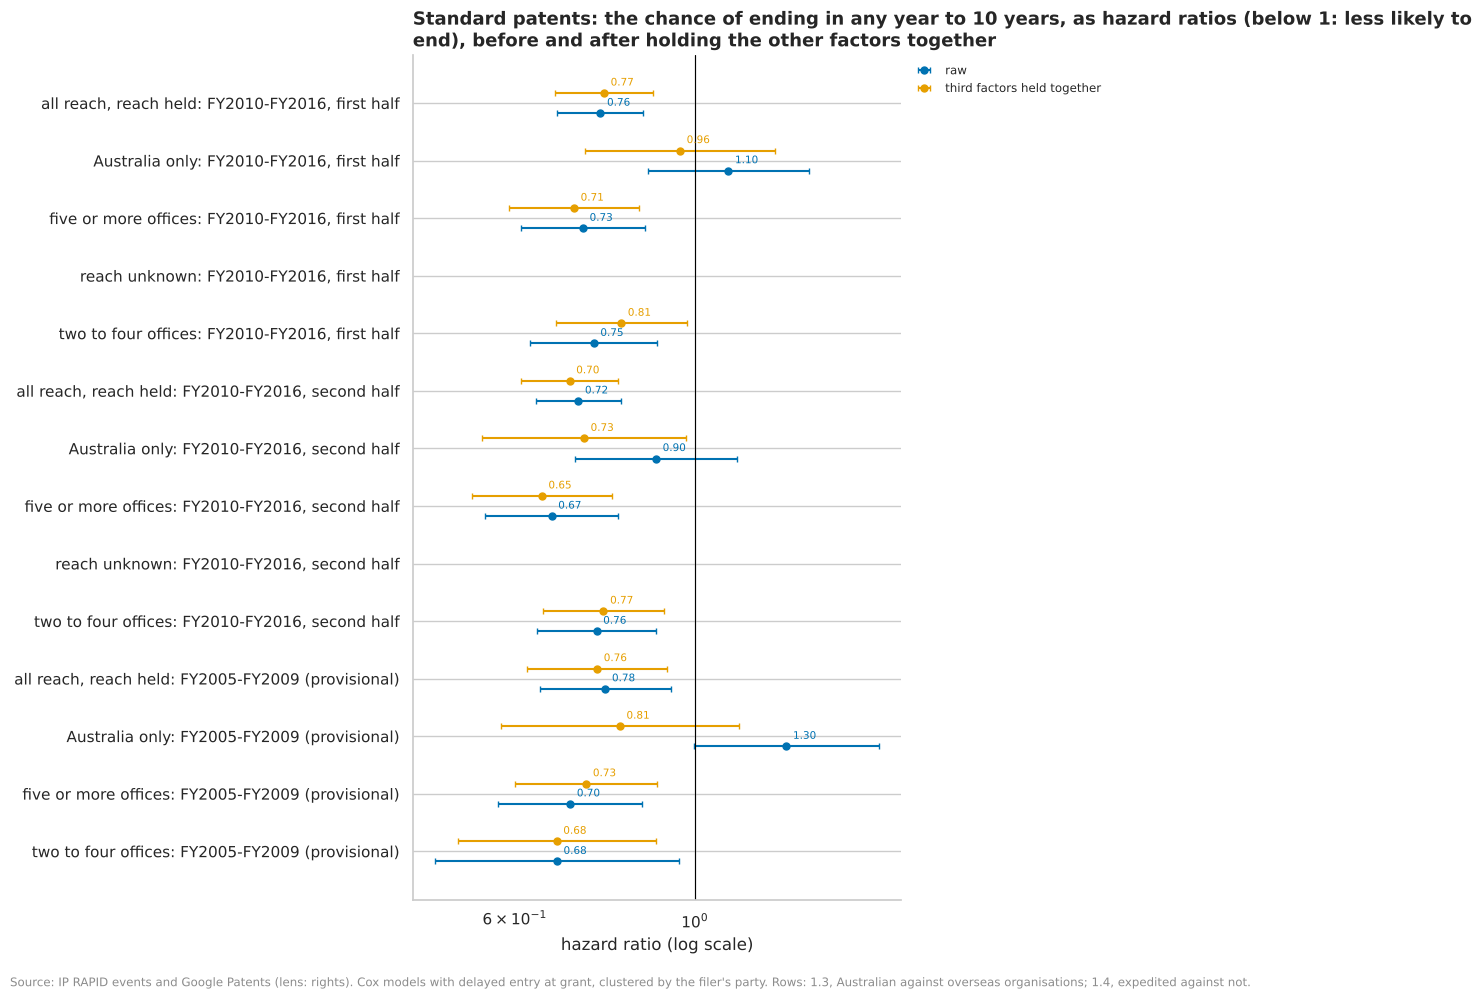

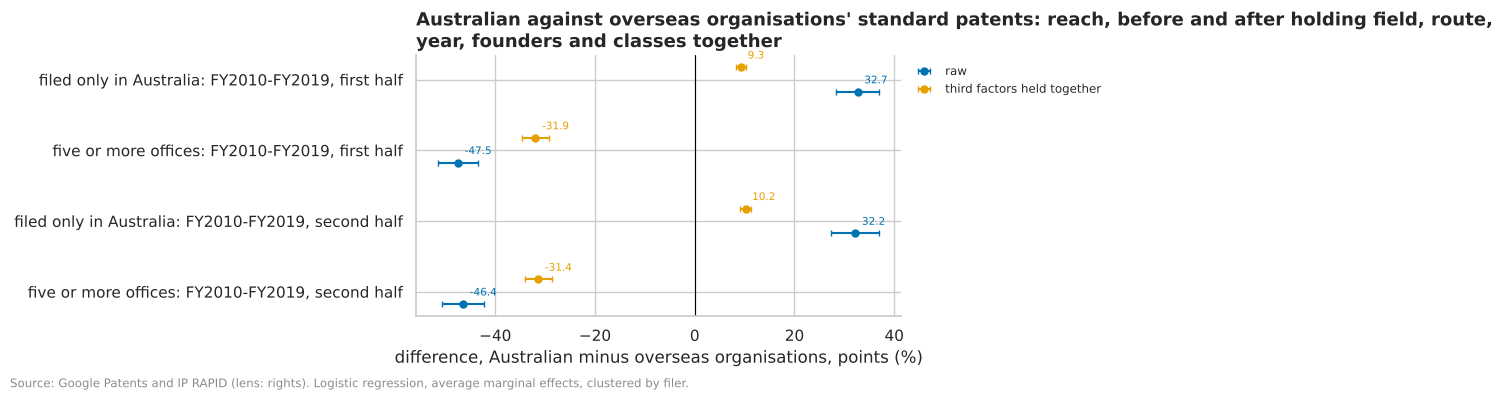

In [8]:
fig = multi.effects_chart(
    life,
    title="Standard patents: the chance of ending in any year to 10 years, as hazard ratios (below 1: less likely to\n"
    "end), before and after holding the other factors together",
    xlabel="hazard ratio (log scale)",
    percent=False,
    fmt="{:.2f}",
    null=1,
)
fig.axes[0].set_xscale("log")
style.source(
    fig,
    "IP RAPID events and Google Patents (lens: rights). Cox models with delayed entry at grant, clustered by the"
    " filer's party. Rows: 1.3, Australian against overseas organisations; 1.4, expedited against not.",
)
fig = multi.effects_chart(
    reach,
    title="Australian against overseas organisations' standard patents: reach, before and after holding field, route,\n"
    "year, founders and classes together",
    xlabel="difference, Australian minus overseas organisations, points",
)
style.source(
    fig,
    "Google Patents and IP RAPID (lens: rights). Logistic regression, average marginal effects, clustered by filer.",
)

#### Observations

**M3 (observational). Within the same reach, Australian organisations' standard patents are less likely to end in
any year to 10 years than overseas organisations', and the gap holds with the field, route, cohort, founders and
classes held together, in both halves; among Australia-only patents there is no consistent gap.** Hazard ratios,
Australian against overseas organisations (below 1: less likely to end), date of patent FY2010 to FY2016, first half
then second (raw; held together), with 95% intervals clustered by the filer:
- **Five or more offices:** 0.728 (0.610 to 0.868) and 0.710 (0.590 to 0.853); 0.666 (0.551 to 0.805) and 0.648
  (0.531 to 0.790). **Holds.**
- **Two to four offices:** 0.750 (0.627 to 0.899) and 0.811 (0.674 to 0.977); 0.757 (0.639 to 0.896) and 0.772
  (0.649 to 0.917). **Holds.**
- **Australia only:** 1.100 (0.876 to 1.382) and 0.959 (0.732 to 1.256), not detected either way; 0.896 (0.712 to
  1.127) and 0.730 (0.546 to 0.976), which appears once held in the second half only. The halves disagree, so B8's
  "no difference among Australia-only patents" is neither overturned nor confirmed.
- **All reach bands, reach held:** 0.773 (0.673 to 0.887) and 0.701 (0.610 to 0.804); in the provisional FY2005 to
  FY2009 cohorts, 0.758 (0.621 to 0.925).
- **Why reach must be held:** 22.3% and 23.5% of Australian organisations' granted patents are Australia only, against
  4.6% and 4.5% of overseas organisations'; 35.7% and 36.4% reach five or more offices, against 75.2% and 75.4%. The
  pooled raw ratio (0.765 and 0.718) is close to the one with reach held, because the in-band gaps point the same way.

**M4 (observational). Australian organisations' patents reach fewer offices and are cited less within five years of
priority; the field, route, year and the rest account for much of each gap, and reach for most of the citation gap,
but neither gap goes.** Standard patents filed FY2010 to FY2019, first half then second:
- **Filed only in Australia:** 40.9% of Australian organisations' against 8.2% of overseas organisations', raw +32.7
  points (28.3 to 37.0), held together +9.3 (8.3 to 10.3), 28.4% remaining; second half +32.2 and +10.2 (9.1 to
  11.2). **Weakened.**
- **Five or more offices:** 22.2% against 69.7%, raw -47.5 (-51.5 to -43.5), held together -31.9 (-34.6 to -29.3),
  67.3% remaining; second half -46.4 and -31.4 (-34.1 to -28.7). **Holds.**
- **Citations within five years** (the fixed-age window): on average 4.44 citing families for Australian
  organisations' patents against 14.22 for overseas organisations'. Rate ratio 0.312 (0.272 to 0.359) raw, 0.645
  (0.577 to 0.721) with reach held, 0.729 (0.677 to 0.784) with every factor held; second half 0.307, 0.633 and 0.700
  (0.634 to 0.774). On a log scale reach accounts for about three fifths of the raw gap (62% and 61%), and about 27%
  and 30% of it remains with every factor held: **weakened**, but about 27% to 30% fewer citations at the same reach,
  field, route and year.
- **So the three signals still disagree once held together:** fewer offices and fewer citations in the same field,
  route and year, yet more often in force at the same reach. None of them is value, private or public (A22, B8);
  they are three readings of how patents are used, to be read side by side. Reach is held only in three bands, so
  part of a gap within a band could still be reach.

### 1.4 Expedited examination and the share in force, with the filer, field, route and cohort held together

**Revisits:** B13. **Informs:** Q1, Q4. Stage 2 found expedited standard patents slightly more often in force at 10
years, pooled, in both periods (3.7 and 1.0 points), not explained by the mix of filers, but differing by filer. Here
the gap is modelled with the **filer** (origin and type), the **field**, the **route**, the **cohort**, **several
founding applicants** and the **number of classes** held together, among examined standard patents, with the same
hazard model as 1.3 (each patent counted from its grant, to 10 years; a hazard ratio below 1 means expedited patents
are less likely to end in a given year); cohorts by the date of patent as in B13 (FY2010 to FY2016, then FY2003 to
FY2009). The same model within
each filer group follows. Since 2014 "expedited" includes requests under work-sharing arrangements
(the Patent Prosecution Highway, OQ25), which IP RAPID does not tell apart.

In [9]:
EXPEDITE_CONTROLS = ["filer", "field", "route", "cohort", "founders", "classes"]
rows = []
for lo, hi in ((2010, 2016), (2003, 2009)):
    d = rsql(f"""
        WITH @FILER_PARTY
        SELECT {LIFETIME}, exam_expedited::INT AS expedited,
               filer_group AS filer, coalesce(main_area, 'unknown') AS field,
               coalesce(filing_route, 'unknown') AS route,
               {DOP_FY} AS cohort, CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
               CASE WHEN class_count IS NULL THEN 'unknown' WHEN class_count = 1 THEN '1' WHEN class_count <= 3
                    THEN '2-3' ELSE '4+' END AS classes,
               coalesce(filer_party, application_number) AS filer_party
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE patent_type = 'standard' AND filer_group IS NOT NULL AND exam_expedited IS NOT NULL AND {LIFE}
          AND {DOP_FY} BETWEEN {lo} AND {hi}
        ORDER BY hash(application_number || 'stage3'), application_number
        LIMIT 200000
    """)
    name = f"FY{lo}-FY{hi}"
    r = multi.adjusted_hazard(
        d, "t", "ended", "entry", "expedited", EXPEDITE_CONTROLS, cluster="filer_party", horizon=10
    )
    rows.append(r.rename(f"all filers: {name}"))
    for fg, sub in d.groupby("filer"):
        r = multi.adjusted_hazard(
            sub, "t", "ended", "entry", "expedited", EXPEDITE_CONTROLS[1:], cluster="filer_party", horizon=10
        )
        rows.append(r.rename(f"{fg.replace('_', ' ')}s: {name}"))
expedite = pd.DataFrame(rows)
expedite[HAZARD].round(3)

,rows,ended,with signal,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
all filers: FY2010-FY2016,130120,39638,8971,0.958,0.842,1.091,1.021,0.902,1.156,-0.495,0,not detected either way
australian individuals: FY2010-FY2016,1363,415,339,1.341,1.086,1.656,1.264,1.013,1.576,0.797,287,holds
australian organisations: FY2010-FY2016,6336,1471,919,0.992,0.838,1.175,0.989,0.836,1.17,1.343,59,not detected either way
overseas individuals: FY2010-FY2016,5959,2089,543,1.077,0.93,1.248,1.07,0.92,1.244,0.908,12,not detected either way
overseas organisations: FY2010-FY2016,116462,35663,7170,0.945,0.805,1.11,1.004,0.863,1.169,-0.076,0,not detected either way
all filers: FY2003-FY2009,104148,28548,6737,0.782,0.717,0.853,1.124,1.03,1.228,-0.476,0,reversed
australian individuals: FY2003-FY2009,1889,642,553,1.344,1.141,1.582,1.249,1.053,1.481,0.751,158,holds
australian organisations: FY2003-FY2009,6473,1401,1139,1.146,0.934,1.405,1.285,1.046,1.58,1.847,42,appears once held
overseas individuals: FY2003-FY2009,5596,1785,271,1.329,1.07,1.651,1.721,1.378,2.149,1.907,24,holds
overseas organisations: FY2003-FY2009,90190,24720,4774,0.598,0.537,0.665,0.957,0.862,1.063,0.085,0,not detected once held


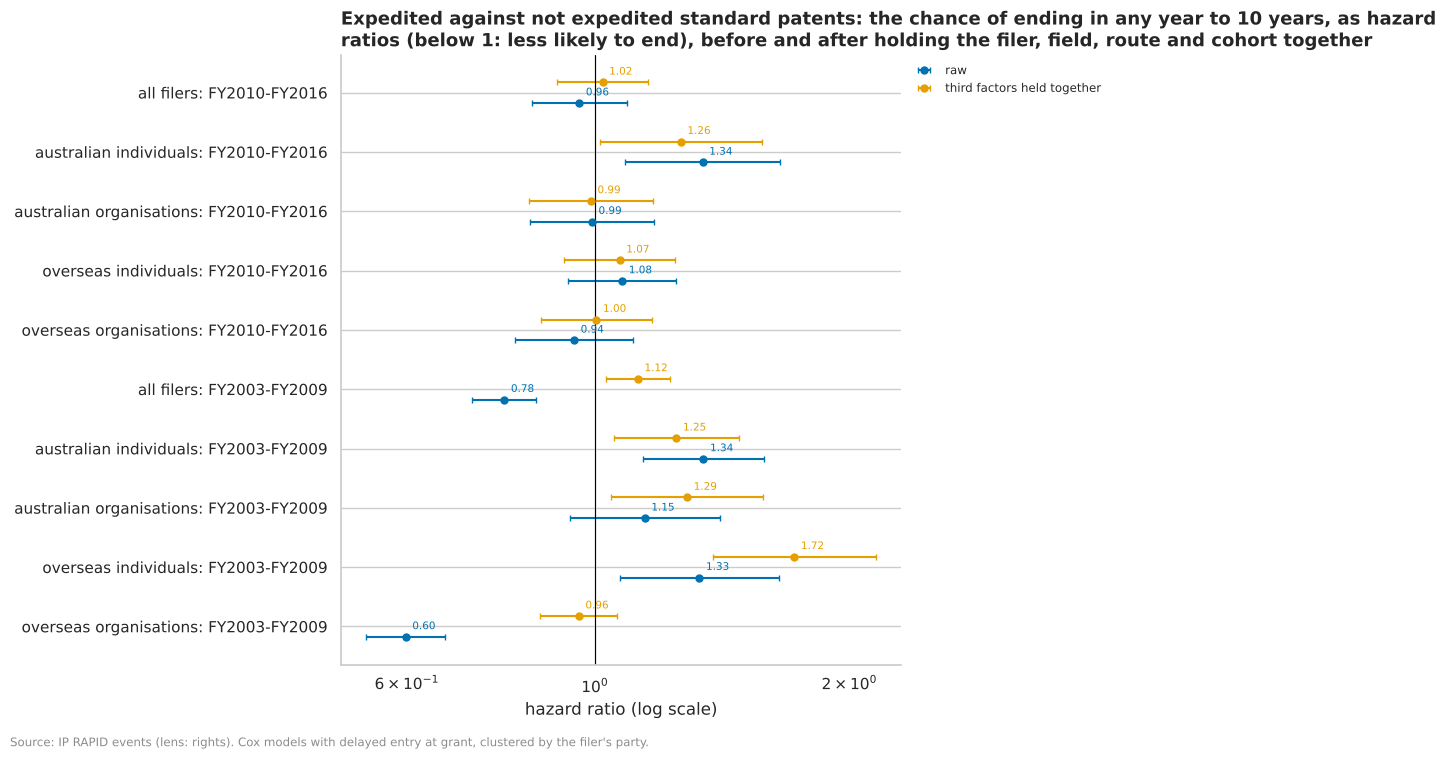

In [10]:
fig = multi.effects_chart(
    expedite,
    title="Expedited against not expedited standard patents: the chance of ending in any year to 10 years, as hazard\n"
    "ratios (below 1: less likely to end), before and after holding the filer, field, route and cohort together",
    xlabel="hazard ratio (log scale)",
    percent=False,
    fmt="{:.2f}",
    null=1,
)
fig.axes[0].set_xscale("log")
style.source(
    fig, "IP RAPID events (lens: rights). Cox models with delayed entry at grant, clustered by the filer's party."
)

#### Observations

**M5 (observational). Expedited examination's link with a longer life does not survive the other factors: pooled, it
is not detected once the filer, field, route and cohort are held (FY2010 to FY2016) and reverses (FY2003 to FY2009);
among Australian individuals, expedited patents are more likely to end, in both periods.** Hazard ratios, expedited
against not (below 1: less likely to end), to 10 years from the date of patent (raw; held together):
- **All filers:** FY2010 to FY2016, 0.958 (0.842 to 1.091) and 1.021 (0.902 to 1.156), not detected either way;
  FY2003 to FY2009, 0.782 (0.717 to 0.853) and 1.124 (1.030 to 1.228), **reversed**. The earlier period's raw
  advantage (B13's 3.7 points) is accounted for by what is held: B13 found it was not the mix of filers, and here the
  field, route, cohort, founders and classes held with the filer take it away. **Revisits B13**, whose "not a
  composition effect" held for the filer mix only.
- **Overseas organisations** (most of the patents): 0.945 (0.805 to 1.110) and 1.004 (0.863 to 1.169), then 0.598
  (0.537 to 0.665) and 0.957 (0.862 to 1.063): **not detected once held** in the earlier period.
- **Australian individuals:** 1.341 (1.086 to 1.656) and 1.264 (1.013 to 1.576), then 1.344 (1.141 to 1.582) and
  1.249 (1.053 to 1.481): **holds** in both periods, expedited patents about a quarter more likely to end in a given
  year. B13 found the same direction in shares (59.7% against 68.5%, then 55.1% against 65.0%).
- **Australian organisations:** 0.992 and 0.989 (0.836 to 1.170), not detected either way; then 1.146 (0.934 to
  1.405) and 1.285 (1.046 to 1.580), appears once held. **Overseas individuals:** 1.077 and 1.070 (0.920 to 1.244),
  not detected either way; then 1.329 (1.070 to 1.651) and 1.721 (1.378 to 2.149), holds.
- **So** expedited examination is not a sign of a patent that lasts longer, once who files, the field and the route
  are known; for Australian individuals it goes with a shorter life. One reading, to test: an individual who asks for
  speed may want a granted patent quickly (to show investors or licensees) and let it go if nothing comes of it. Since
  2014 "expedited" also includes work-sharing requests (OQ25), so the kinds of request are mixed.

### 1.5 Australian-founded patents now held only overseas: reach, grant and the filer's type held together

**Revisits:** B19. **Informs:** Q1. Stage 2 found that Australian-founded standard patents now held only overseas
(two endpoints: the founding applicant in Australia, every current holder overseas; not a transfer history, ADR 0040)
are commoner among the wide (five or more offices), the granted and organisations' patents. The three go together
(wide patents are more often granted, and organisations' are wider), so each is read here with the other two held,
and the **field**, **route**, **filing year** and **several founding applicants** with them. Filed FY2003 to FY2011,
then FY2012 to FY2021 (which have had less time to change hands), as in B19; reach compares five or more offices with
Australia only (two to four offices held as their own band in the other readings). Clustered by the filer's party.

In [11]:
OVERSEAS_COLUMNS = f"""
    (NOT australian_applicant)::INT AS held_overseas, {REACH} AS reach,
    (registered_date IS NOT NULL)::INT AS granted,
    (split_part(filer_group, '_', 2) = 'organisation')::INT AS organisation,
    coalesce(main_area, 'unknown') AS field, coalesce(filing_route, 'unknown') AS route, filing_fy,
    CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
    coalesce(filer_party, application_number) AS filer_party"""
rows = []
for lo, hi in ((2003, 2011), (2012, 2021)):
    d = rsql(f"""
        WITH @FILER_PARTY
        SELECT {OVERSEAS_COLUMNS}
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE patent_type = 'standard' AND founding_australian AND filer_group IS NOT NULL
          AND australian_applicant IS NOT NULL AND filing_fy BETWEEN {lo} AND {hi}
    """)
    name = f"FY{lo}-FY{hi}"
    base = ["field", "route", "filing_fy", "founders"]
    wide = d[d.reach.isin(["Australia only", "five or more offices"])].assign(
        wide=lambda x: (x.reach == "five or more offices").astype(int)
    )
    rows.append(
        multi.adjusted_effect(
            wide, "held_overseas", "wide", ["granted", "organisation", *base], cluster="filer_party"
        ).rename(f"five or more offices (against Australia only): {name}")
    )
    rows.append(
        multi.adjusted_effect(
            d, "held_overseas", "granted", ["reach", "organisation", *base], cluster="filer_party"
        ).rename(f"granted (against never granted): {name}")
    )
    rows.append(
        multi.adjusted_effect(
            d, "held_overseas", "organisation", ["reach", "granted", *base], cluster="filer_party"
        ).rename(f"organisation (against individual): {name}")
    )
overseas = pd.DataFrame(rows)
overseas[EFFECT].round(4)

,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
five or more offices (against Australia only): FY2003-FY2011,17262,0.1452,0.0375,0.1076,0.0423,0.173,0.0432,0.0275,0.0588,0.4011,126,weakened
granted (against never granted): FY2003-FY2011,23216,0.0996,0.0115,0.0881,0.0331,0.1432,0.0563,0.0459,0.0668,0.6393,740,holds
organisation (against individual): FY2003-FY2011,23216,0.0691,0.0157,0.0534,0.0131,0.0937,0.0262,0.015,0.0373,0.4902,740,weakened
five or more offices (against Australia only): FY2012-FY2021,16088,0.0625,0.0116,0.0509,0.0383,0.0636,0.0222,0.0115,0.033,0.4368,85,weakened
granted (against never granted): FY2012-FY2021,25819,0.0481,0.0087,0.0394,0.0322,0.0465,0.0277,0.0217,0.0337,0.7036,130,holds
organisation (against individual): FY2012-FY2021,25819,0.0284,0.0181,0.0102,0.0034,0.0171,0.0005,-0.0079,0.009,0.0523,130,not detected once held


#### Observations

**M6 (observational). Australian-founded patents now held only overseas are commoner among the granted, with reach and
the filer's type held; the wide patents' higher rate is more than halved once grant and type are held, and the
organisations' gap goes in the later period.** Difference in the share now held only overseas, in points (raw; held
together, with the field, route, filing year and founders), filed FY2003 to FY2011 then FY2012 to FY2021:
- **Granted against never granted:** +8.8 (3.3 to 14.3) and +5.6 (4.6 to 6.7); +3.9 (3.2 to 4.7) and +2.8 (2.2 to
  3.4). **Holds** in both, 63.9% and 70.4% remaining.
- **Five or more offices against Australia only:** +10.8 (4.2 to 17.3) and +4.3 (2.8 to 5.9); +5.1 (3.8 to 6.4) and
  +2.2 (1.2 to 3.3). **Weakened** in both, 40.1% and 43.7% remaining: much of the wide patents' higher rate goes with
  their being granted and organisations'.
- **Organisations against individuals:** +5.3 (1.3 to 9.4) and +2.6 (1.5 to 3.7), weakened; +1.0 (0.3 to 1.7) and
  +0.05 (-0.8 to 0.9), **not detected once held** in the later period.
- The raw intervals in the earlier period are wide (clustered by filer): a few filers hold many of these patents.
  The later period has had less time for holders to change (B19).
- **Two endpoints, not transfers** (ADR 0040): grant and reach are seen today, not necessarily before the holder
  changed, and nothing here says where value goes. The signal for Q1 is that granted Australian-founded patents are
  the ones more often held only overseas now, whatever their reach and filer.

### 1.6 Women among inventors: the filer, with the field and year held together

**Revisits:** B17, B18. **Informs:** Q2. Stage 2 found that the field matters more than the filer for women among
inventors in Australia on standard patents (4.2% to 26.9% by field; the filer gap did not replicate), and that on
provisional applications Australian organisations' inventors include more women than Australian individuals' (21.19%
against 16.12%, FY2013 to FY2022). Its named third factor was the field, which the two filer groups may weight
differently. Here each patent's estimated share of women among its inventors is modelled, weighted by its inventors
with an estimate (a quasi-binomial model), Australian organisations against Australian individuals:

- **standard patents** (inventors in Australia, from Google Patents, as in B17), with the **field**, **filing year**
  and **state** held together, FY2010 to FY2019 then FY2000 to FY2009;
- **provisionals** (the register's inventors, with the applicant's country, as in B18), with the **filing year**,
  **state** and **several founding applicants** held together, FY2013 to FY2022 then FY2003 to FY2012. Provisionals
  have no technology field in IP RAPID, so the field cannot be held for them.

Expected counts from first names, read for inventors in Australia only (U97); clustered by the filer's party.

In [12]:
std = rsql(
    """
    WITH @FILER_PARTY
    SELECT r.application_number, @PERIOD AS period, (r.filer_group = 'australian_organisation')::INT AS organisation,
           coalesce(r.main_area, 'unknown') AS field, r.filing_fy, coalesce(r.founder_state, 'unknown') AS state,
           coalesce(p.filer_party, r.application_number) AS filer_party,
           sum(i.p_female) / count(i.p_female) AS women_share, count(i.p_female) AS estimated
    FROM {lens/rights} r JOIN {google_patents_inventors/inventors} i USING (family_id)
         LEFT JOIN filer_party p USING (ip_right_type, application_number)
    WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 2000 AND 2019 AND i.country_code = 'AU'
      AND r.filer_group IN ('australian_individual', 'australian_organisation') AND i.p_female IS NOT NULL
    GROUP BY ALL
"""
)
prov = rsql("""
    WITH @FILER_PARTY
    SELECT CASE WHEN filing_fy BETWEEN 2013 AND 2022 THEN 'FY2013-FY2022' ELSE 'FY2003-FY2012' END AS period,
           (filer_group = 'australian_organisation')::INT AS organisation, filing_fy,
           coalesce(founder_state, 'unknown') AS state,
           CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
           coalesce(filer_party, application_number) AS filer_party,
           register_inventors_women_expected / (register_inventors - register_inventors_gender_unknown) AS women_share,
           register_inventors - register_inventors_gender_unknown AS estimated
    FROM {lens/rights} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
    WHERE patent_type = 'provisional' AND filing_fy BETWEEN 2003 AND 2022
      AND filer_group IN ('australian_individual', 'australian_organisation')
      AND register_inventors - register_inventors_gender_unknown > 0
""")
rows = []
for period, d in std.groupby("period", sort=False):
    rows.append(
        multi.adjusted_effect(
            d,
            "women_share",
            "organisation",
            ["field", "filing_fy", "state"],
            cluster="filer_party",
            weights="estimated",
        ).rename(f"standard patents: {period}")
    )
for period, d in prov.groupby("period", sort=False):
    rows.append(
        multi.adjusted_effect(
            d,
            "women_share",
            "organisation",
            ["filing_fy", "state", "founders"],
            cluster="filer_party",
            weights="estimated",
        ).rename(f"provisionals: {period}")
    )
women = pd.DataFrame(rows).sort_index()
print(
    f"Standard patents: {len(std):,}, {std.estimated.sum():,} inventors with an estimate;",
    f"provisionals: {len(prov):,}, {prov.estimated.sum():,.0f}",
)
women[EFFECT].round(4)

Standard patents: 18,182, 35,446 inventors with an estimate; provisionals: 110,717, 140,492


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
provisionals: FY2003-FY2012,63728,0.2551,0.189,0.0662,0.054,0.0783,0.0663,0.0548,0.0778,1.002,0,holds
provisionals: FY2013-FY2022,46989,0.2119,0.1612,0.0507,0.0377,0.0638,0.0556,0.0426,0.0687,1.097,0,holds
standard patents: FY2000-FY2009,4762,0.159,0.1122,0.0468,-0.0112,0.1048,-0.0212,-0.0535,0.0112,-0.4523,23,not detected either way
standard patents: FY2010-FY2019,13420,0.1218,0.1113,0.0105,-0.0065,0.0275,-0.0282,-0.0458,-0.0107,-2.685,0,appears once held


#### Observations

**M7 (observational). On provisionals, Australian organisations' inventors include more women than Australian
individuals', and the gap holds with the year, state and founders held, in both decades; on standard patents, the
organisations' apparent advantage is the field: with the field held, organisations' inventors include fewer women in
FY2010 to FY2019.** Difference in the estimated share of women among inventors, Australian organisations minus
Australian individuals, in points (raw; held together), weighted by inventors with an estimate:
- **Provisionals** (the register's inventors; 110,717 provisionals, 140,492 inventors with an estimate): FY2013 to
  FY2022, 21.19% against 16.12%, raw +5.07 (3.77 to 6.38), held together +5.56 (4.26 to 6.87); FY2003 to FY2012,
  25.51% against 18.90%, +6.62 (5.40 to 7.83) and +6.63 (5.48 to 7.78). **Holds** in both. The field cannot be held
  for provisionals (none has one in IP RAPID).
- **Standard patents** (inventors in Australia; 18,182 patents, 35,446 inventors with an estimate): FY2010 to FY2019,
  12.18% against 11.13%, raw +1.05 (-0.65 to 2.75), held together -2.82 (-4.58 to -1.07), which **appears once held**;
  FY2000 to FY2009, 15.90% against 11.22%, +4.68 (-1.12 to 10.48) and -2.12 (-5.35 to 1.12), not detected either way.
  B17's filer gap (15.9% against 11.22%, with intervals that did not overlap) is not detected once the filer is
  clustered, and turns negative with the field held.
- **So** B17's reading, that the field matters more than the filer, is confirmed: within the same field and year,
  organisations' patents name no more women than individuals', and in the later decade fewer. The provisional gap
  stands but cannot be checked against the field. Expected counts from first names, levels for inventors in Australia
  only (U97); the provisionals' estimates use the applicant's country (B18).

### 1.7 Divisionals among organisations' standard patents, with the field and the filer held

**Revisits:** B15 (carried to Stage 3 by notebook 2's section 8, and not taken up in the first pass; added in the
review of 3 November 2026). **Informs:** Q4. B15 found that divisionals (applications split from an earlier one, which
keep its filing date and can keep a claim pending longer) doubled among organisations' standard patents between FY2000
to FY2009 and FY2010 to FY2019: Australian organisations' from 11.6% to 22.4%, overseas organisations' from 7.1% to
15.6%. Here the decade's difference is modelled with the **technology field**, **several founding applicants** and the
**number of classes** held, clustered by the filer's party (the route cannot be held: a divisional is a route); then
**within the same filers** (filers with patents in both decades, each filer's own average taken out: a linear model
with a fixed effect for the filer); and without the ten filers with the most divisionals in the later decade.
Applications with a field only (one abandoned before it is classified has neither a field nor a class count, so the
two would repeat each other), capped at 200,000 a group by the hash, as elsewhere.

In [13]:
import statsmodels.api as sm

DIV_COLUMNS = """
    (filing_route = 'divisional')::INT AS divisional, (filing_fy >= 2010)::INT AS later, main_area AS field,
    CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
    CASE WHEN class_count = 1 THEN '1' WHEN class_count <= 3 THEN '2-3' ELSE '4+' END AS classes,
    coalesce(filer_party, application_number) AS filer_party"""
rows, conc = [], []
for fg, who in (
    ("australian_organisation", "Australian organisations"),
    ("overseas_organisation", "overseas organisations"),
):
    d = rsql(f"""
        WITH @FILER_PARTY
        SELECT {DIV_COLUMNS}
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
        WHERE patent_type = 'standard' AND filer_group = '{fg}' AND filing_fy BETWEEN 2000 AND 2019
          AND filing_route IS NOT NULL AND main_area IS NOT NULL
        ORDER BY hash(application_number || 'stage3'), application_number
        LIMIT 200000
    """)
    r = multi.adjusted_effect(d, "divisional", "later", ["field", "founders", "classes"], cluster="filer_party")
    rows.append(r.rename(f"{who}: FY2010-FY2019 against FY2000-FY2009"))
    top10 = d[(d.later == 1) & (d.divisional == 1)].filer_party.value_counts().head(10).index
    r = multi.adjusted_effect(
        d[~d.filer_party.isin(top10)], "divisional", "later", ["field", "founders", "classes"], cluster="filer_party"
    )
    rows.append(r.rename(f"{who}, without the ten filers with the most later divisionals"))
    # within the same filers: those with patents in both decades, a linear probability model with each filer's own
    # mean taken out (a fixed effect for the filer), clustered by filer
    w = d[d.groupby("filer_party").later.transform("nunique") == 2].copy()
    for c in ("divisional", "later"):
        w[c + "_w"] = w[c] - w.groupby("filer_party")[c].transform("mean")
    fit = sm.OLS(w.divisional_w, w[["later_w"]]).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(w.filer_party)[0]}
    )
    lo_, hi_ = fit.conf_int().loc["later_w"]
    later_div = d[(d.later == 1) & (d.divisional == 1)].filer_party.value_counts()
    conc.append(
        {
            "filers": who,
            "rows": len(d),
            "share earlier (%)": 100 * d[d.later == 0].divisional.mean(),
            "share later (%)": 100 * d[d.later == 1].divisional.mean(),
            "filers in both decades": w.filer_party.nunique(),
            "their rows": len(w),
            "within the same filers (points)": 100 * fit.params["later_w"],
            "low": 100 * lo_,
            "high": 100 * hi_,
            "later divisionals": int(later_div.sum()),
            "top 10 filers' share of them (%)": 100 * later_div.head(10).sum() / later_div.sum(),
        }
    )
divisionals = pd.DataFrame(rows)
display(pd.DataFrame(conc).set_index("filers").round(2))
divisionals[EFFECT].round(3)

,rows,share earlier (%),share later (%),filers in both decades,their rows,within the same filers (points),low,high,later divisionals,top 10 filers' share of them (%)
filers,,,,,,,,,,
Australian organisations,35437,11.59,22.62,1413,17107,19.18,9.45,28.91,4317,38.61
overseas organisations,200000,7.08,15.63,5664,125932,10.97,10.1,11.84,17050,8.51


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
Australian organisations: FY2010-FY2019 against FY2000-FY2009,35437,0.226,0.116,0.11,0.012,0.209,0.107,0.048,0.166,0.969,0,holds
"Australian organisations, without the ten filers with the most later divisionals",30436,0.163,0.092,0.071,0.06,0.082,0.071,0.06,0.081,0.995,0,holds
overseas organisations: FY2010-FY2019 against FY2000-FY2009,200000,0.156,0.071,0.085,0.078,0.093,0.088,0.081,0.094,1.026,0,holds
"overseas organisations, without the ten filers with the most later divisionals",191453,0.152,0.07,0.082,0.076,0.088,0.084,0.078,0.09,1.028,0,holds


#### Observations

**M26 (observational). Divisionals doubled among organisations' standard patents with the field and the filer held,
and within the same filers; for Australian organisations ten filers hold 38.61% of the later decade's divisionals, but
the rise holds without them.** Applications with a field, FY2010 to FY2019 against FY2000 to FY2009; difference in the
share that are divisionals, in points (raw; with the field, founders and classes held), clustered by the filer:
- **Australian organisations:** 11.59% to 22.62%, raw +11.0 (1.2 to 20.9), held together +10.7 (4.8 to 16.6), 96.9%
  remaining: **holds**. Without the ten filers with the most later divisionals, +7.1 (6.0 to 8.2) and +7.1 (6.0 to
  8.1). **Within the same filers** (1,413 filers with patents in both decades, 17,107 applications): +19.18 (9.45 to
  28.91).
- **Overseas organisations:** 7.08% to 15.63%, raw +8.5 (7.8 to 9.3), held together +8.8 (8.1 to 9.4): **holds**;
  without their ten largest +8.4 (7.8 to 9.0); within the same filers (5,664 filers) +10.97 (10.10 to 11.84). Their
  ten largest hold 8.51% of the later divisionals.
- **So** B15's doubling is not a change in the mix of fields or filers: the same organisations file more divisionals.
  Why is not in the data; B15's lead, that a divisional keeps claims pending longer, is for Q4 and needs the dates of
  each divisional's parent and its examination.

### 1.8 Inventions made in Australia and filed from overseas: the inventor team, field and reach held together

**Revisits:** B16 (carried, not taken up in the first pass; added 3 November 2026). **Informs:** Q1. B16 found that of
the standard patents with an inventor in Australia, 19.28% (FY2000 to FY2009) and 14.51% (FY2010 to FY2019) were
filed from overseas (no founding applicant in Australia). Two questions: is the fall between the decades the mix of
fields, reach and teams; and which patents made here are filed from overseas, those whose inventors are all in
Australia, or international teams with an inventor here? The share filed from overseas is modelled against the decade
with whether the team also has **inventors abroad**, the **field**, the **reach** band, the **number of inventors in
Australia** and **several founding applicants** held together; then, within each decade, against inventors abroad
and against wide reach. Inventors' countries are known only where Google Patents gives them (U95), so patents made
here and filed only abroad are not in IP RAPID at all (F07); clustered by the filer's party.

In [14]:
MADE_COLUMNS = f"""
    (NOT founding_australian)::INT AS filed_overseas, (filing_fy >= 2010)::INT AS later,
    (inventors_abroad > 0)::INT AS team_abroad, coalesce(main_area, 'unknown') AS field, {REACH} AS reach,
    CASE WHEN inventors_au = 1 THEN '1' WHEN inventors_au <= 3 THEN '2-3' ELSE '4+' END AS inventors_here,
    CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
    coalesce(filer_party, application_number) AS filer_party"""
made = rsql(f"""
    WITH @FILER_PARTY
    SELECT {MADE_COLUMNS}
    FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND invented_in_australia
      AND founding_australian IS NOT NULL AND filer_group IS NOT NULL
""")
mix_made = made.groupby(["later", "team_abroad"]).filed_overseas.agg(["mean", "size", "sum"])
mix_made.index = mix_made.index.set_levels(["FY2000-FY2009", "FY2010-FY2019"], level="later").set_levels(
    ["every inventor known in Australia", "inventors abroad too"], level="team_abroad"
)
print(
    f"Standard patents with an inventor in Australia, FY2000 to FY2019: {len(made):,};",
    f"with inventors abroad too: {made.team_abroad.mean():.2%}",
)
display(
    mix_made.rename(columns={"mean": "filed from overseas", "size": "patents", "sum": "filed from overseas (n)"}).round(
        4
    )
)
MADE_CONTROLS = ["field", "reach", "inventors_here", "founders"]
rows = [
    multi.adjusted_effect(
        made, "filed_overseas", "later", ["team_abroad", *MADE_CONTROLS], cluster="filer_party"
    ).rename("FY2010-FY2019 against FY2000-FY2009")
]
for later, sub in made.groupby("later"):
    per = "FY2010-FY2019" if later else "FY2000-FY2009"
    rows.append(
        multi.adjusted_effect(sub, "filed_overseas", "team_abroad", MADE_CONTROLS, cluster="filer_party").rename(
            f"inventors abroad too (against every inventor here): {per}"
        )
    )
    rows.append(
        multi.adjusted_effect(
            sub.assign(wide=(sub.reach == "five or more offices").astype(int)),
            "filed_overseas",
            "wide",
            ["team_abroad", "field", "inventors_here", "founders"],
            cluster="filer_party",
        ).rename(f"five or more offices (against fewer, or unknown): {per}")
    )
made_fx = pd.DataFrame(rows)
alone_here = made[(made.team_abroad == 0) & (made.filed_overseas == 1)].filer_party.value_counts()
print(
    f"Patents whose known inventors are all in Australia, filed from overseas: {alone_here.sum():,} from",
    f"{len(alone_here):,} filers; the ten largest {alone_here.head(10).sum() / alone_here.sum():.1%}",
)
made_fx[EFFECT].round(4)

Standard patents with an inventor in Australia, FY2000 to FY2019: 22,335; with inventors abroad too: 13.96%


filed from overseas  patents  filed from overseas (n)
later         team_abroad                                                                             
FY2000-FY2009 every inventor known in Australia               0.1085     5132                      557
              inventors abroad too                            0.6208     1010                      627
FY2010-FY2019 every inventor known in Australia               0.0857    14086                     1207
              inventors abroad too                             0.542     2107                     1142

Patents whose known inventors are all in Australia, filed from overseas: 1,764 from 583 filers; the ten largest 33.0%


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
FY2010-FY2019 against FY2000-FY2009,22335,0.1451,0.1928,-0.0477,-0.0781,-0.0174,-0.0269,-0.0459,-0.0078,0.5632,0,holds
inventors abroad too (against every inventor here): FY2000-FY2009,6142,0.6208,0.1085,0.5123,0.4474,0.5771,0.5203,0.466,0.5747,1.016,22,holds
"five or more offices (against fewer, or unknown): FY2000-FY2009",6142,0.2496,0.1452,0.1044,0.0267,0.1821,0.0453,-0.0005,0.0911,0.4341,22,not detected once held
inventors abroad too (against every inventor here): FY2010-FY2019,16193,0.542,0.0857,0.4563,0.4026,0.51,0.4752,0.4298,0.5206,1.041,27,holds
"five or more offices (against fewer, or unknown): FY2010-FY2019",16193,0.2106,0.1086,0.102,0.0557,0.1482,0.0573,0.0327,0.0819,0.562,27,holds


#### Observations

**M27 (observational). Of standard patents with an inventor in Australia, those whose teams also have inventors abroad
are filed from overseas more than half the time, against about one in ten whose known inventors are all here; the
fall between the decades holds with the team, field and reach held.** 22,335 patents filed FY2000 to FY2019 with an
inventor in Australia, 13.96% with inventors abroad too:
- **Filed from overseas:** every inventor known in Australia 10.85% (557 of 5,132), then 8.57% (1,207 of 14,086);
  inventors abroad too 62.08% (627 of 1,010), then 54.20% (1,142 of 2,107). In FY2010 to FY2019 the two kinds of team
  give about as many patents filed from overseas (1,207 and 1,142).
- **Inventors abroad too, against every inventor here:** +51.2 points raw, +52.0 (46.6 to 57.5) held together, then
  +45.6 and +47.5 (43.0 to 52.1): **holds**.
- **The decade:** 19.28% to 14.51%, raw -4.8 (-7.8 to -1.7), held together -2.7 (-4.6 to -0.8), 56.3% remaining:
  **holds**. **Wide reach** (five or more offices): +10.4 raw and +4.5 (-0.05 to 9.1) held in FY2000 to FY2009, not
  detected once held; +10.2 and +5.7 (3.3 to 8.2) in FY2010 to FY2019.
- The patents with every known inventor here that were filed from overseas: 1,764, from 583 filers, the ten largest
  33.0%.
- **So** B16's "one in seven" is two things in about equal parts: international teams with an inventor here, filed by
  their owners abroad, and teams wholly here whose filer is overseas (a parent or a buyer at filing; who they are is
  not in the data). Inventors' countries are known only where Google Patents gives them (U95), and inventions made
  here but filed only abroad are not in IP RAPID (F07).

### 1.9 Fee changes at each right's renewal: are more rights let go at the anniversary after a change?

**Revisits:** B49, which left this test to Stage 3 ("whether fees move renewal is for the test at each right's
anniversary (the rights lens), in Stage 3"); added 3 November 2026. **Informs:** Q4, Q5. A fee to keep a right falls
due on an anniversary: each year from the fourth for a standard patent (of its date of patent), at 10 years for a
trade mark and at 5 years for a design (of the filing date, under the 1995 and 2003 Acts). For each change in those
fees from 2000 (`frl_fees`: patents in September 2002, March 2007, August 2010, July 2012, October 2016 and October
2020; trade marks in October 2016; designs in July 2012 and October 2020; October 2024 is too recent to have its year
after), every right whose changed anniversary fell in the 12 months before or after the change, granted before it and
not ended before it, is a row. It is **let go** if it ceased at that anniversary: for patents, a cessation dated 3 to
12 months after it (cessations are dated at the end of the six-month grace period); for trade marks and designs, one
dated from a month before to two months after it (dated at the anniversary).

The signal is an anniversary **after** the change. Held together: a straight-line trend in time with its own slope on
each side of the change (so that a drift is not read as a step), the anniversary number, the filer's origin and type,
the field (patents) or main class (trade marks, designs), and several founders (patents) or classes (trade marks,
designs); clustered by the filer's party; capped at 200,000 anniversaries by the hash. As a control, for the 2010 and
2016 patent changes, the anniversaries whose fee did not change, read the same way. An owner can pay before the
anniversary at the fee then in force, so this tests the decision at the anniversary, not the price each owner paid.

,fee change (median %),anniversaries,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"patents, September 2002",15.27,14,147442,0.138,0.1185,0.0194,0.0117,0.0271,0.0008,-0.0082,0.0098,0.0406,21,not detected once held
"patents, March 2007",-10,12,146624,0.0804,0.0923,-0.0119,-0.0169,-0.007,-0.0057,-0.0127,0.0012,0.481,0,not detected once held
"patents, August 2010",12.92,10,106255,0.1084,0.132,-0.0235,-0.0336,-0.0135,-0.0012,-0.0123,0.01,0.0492,0,not detected once held
"patents, July 2012",11.11,15,199996,0.0896,0.0895,0.0001,-0.0078,0.0081,0.0005,-0.0079,0.009,4.889,0,not detected either way
"patents, October 2016",10.87,10,135484,0.1058,0.106,-0.0003,-0.0076,0.0071,0.0043,-0.0055,0.0141,-16.21,0,not detected either way
"patents, October 2020",29.55,15,200000,0.102,0.1064,-0.0044,-0.0115,0.0028,-0.0006,-0.0084,0.0072,0.1404,0,not detected either way
"trade marks, October 2016",33.33,1,78661,0.4945,0.4895,0.005,-0.0049,0.0149,-0.0099,-0.0278,0.008,-1.979,0,not detected either way
"designs, July 2012",16.36,1,11091,0.4669,0.4719,-0.005,-0.05,0.0401,0.0624,-0.0074,0.1321,-12.55,114,not detected either way
"designs, October 2020",25,1,12646,0.4021,0.4008,0.0012,-0.0409,0.0433,-0.0249,-0.0929,0.0432,-19.93,14,not detected either way
"patents, August 2010: anniversaries not changed (control)",0,6,98094,0.0804,0.0972,-0.0168,-0.0263,-0.0072,0.0072,-0.002,0.0164,-0.4289,4340,not detected once held


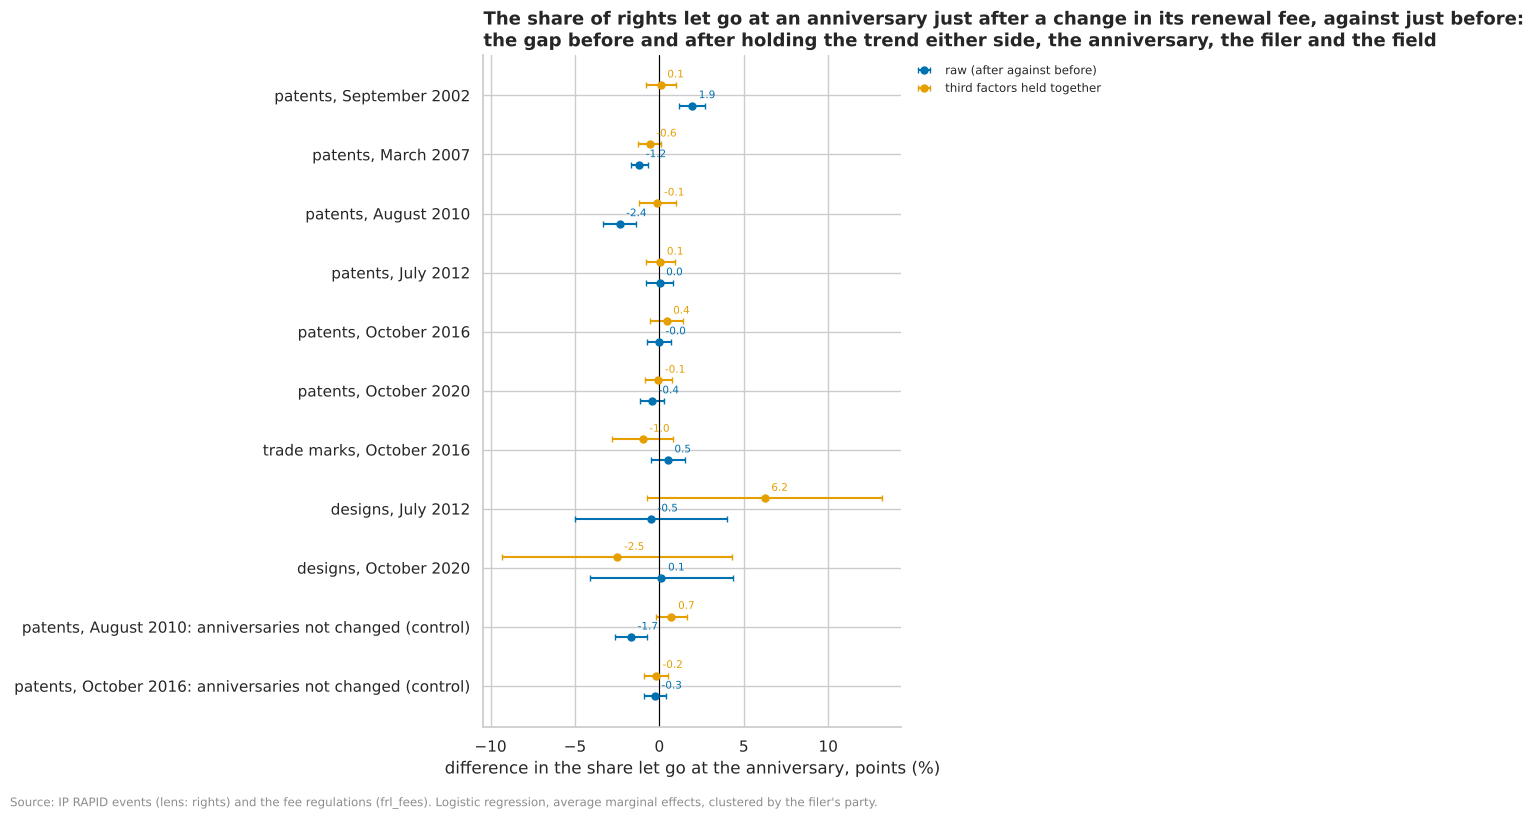

In [15]:
# Each change in a fee to keep a right, with the anniversaries whose fee it changed and by how much
kept = sql("""
    WITH k AS (SELECT "right", fee, coalesce(anniversary, 0) AS anniversary, start, amount_aud,
                      lag(amount_aud) OVER (PARTITION BY "right", fee, anniversary ORDER BY start) AS before,
                      lag("end") OVER (PARTITION BY "right", fee, anniversary ORDER BY start) AS before_end
               FROM {frl_fees/key_fees} WHERE fee IN ('standard_renewal', 'renewal'))
    SELECT "right", start, anniversary, 100 * (amount_aud / before - 1) AS pct
    FROM k WHERE before IS NOT NULL AND before_end = start AND amount_aud <> before
""")
RENEWAL_CHANGES = [
    ("patent", "2002-09-01"), ("patent", "2007-03-01"), ("patent", "2010-08-01"), ("patent", "2012-07-01"),
    ("patent", "2016-10-10"), ("patent", "2020-10-01"), ("trade_mark", "2016-10-10"), ("design", "2012-07-01"),
    ("design", "2020-10-01"),
]  # fmt: skip


def renewal_rows(right, when, unchanged=False):
    t0 = pd.Timestamp(when)
    lo, hi = (t0 - pd.DateOffset(months=12)).date(), (t0 + pd.DateOffset(months=12)).date()
    ch = kept[(kept.right == right) & (pd.to_datetime(kept.start) == t0)]
    if right == "patent":
        ks = sorted(set(range(4, 20)) - set(ch.anniversary.astype(int))) if unchanged else ch.anniversary.astype(int)
        ks = ", ".join(str(k) for k in sorted(ks) if 4 <= k <= 19)
        base = f"""
            SELECT r.application_number, k AS anniversary, r.date_of_patent + to_years(k) AS anniv,
                   coalesce(main_area, 'unknown') AS field, filer_group AS filer,
                   CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders, r.status, r.retired_date,
                   r.registered_date
            FROM {{lens/rights}} r, unnest([{ks}]) t(k)
            WHERE r.patent_type = 'standard' AND r.date_of_patent IS NOT NULL AND filer_group IS NOT NULL"""
        let_go = "retired_date >= anniv + INTERVAL 3 MONTH AND retired_date < anniv + INTERVAL 12 MONTH"
        alive = "retired_date IS NULL OR retired_date >= anniv + INTERVAL 3 MONTH"
    else:
        years = 10 if right == "trade_mark" else 5
        base = f"""
            SELECT r.application_number, {years} AS anniversary, r.application_date + to_years({years}) AS anniv,
                   coalesce(main_class, 'unknown') AS field, filer_group AS filer,
                   CASE WHEN class_count = 1 THEN 'one' ELSE 'several' END AS founders, r.status, r.retired_date,
                   r.registered_date
            FROM {{lens/rights}} r
            WHERE r.ip_right_type = '{right}' AND r.application_date >= DATE '1996-01-01' AND filer_group IS NOT NULL"""
        let_go = "retired_date >= anniv - INTERVAL 1 MONTH AND retired_date < anniv + INTERVAL 2 MONTH"
        alive = "retired_date IS NULL OR retired_date >= anniv - INTERVAL 1 MONTH"
    d = rsql(f"""
        WITH @FILER_PARTY, b AS ({base})
        SELECT (status = 'ceased' AND {let_go})::INT AS let_go, (anniv >= DATE '{t0.date()}')::INT AS after,
               date_diff('day', DATE '{t0.date()}', anniv) / 365.25 AS t, anniversary, field, filer, founders,
               coalesce(p.filer_party, b.application_number) AS filer_party
        FROM b LEFT JOIN filer_party p ON p.ip_right_type = '{right}' AND p.application_number = b.application_number
        WHERE anniv >= DATE '{lo}' AND anniv < DATE '{hi}' AND registered_date < anniv AND ({alive})
        ORDER BY hash(b.application_number || anniversary::VARCHAR || 'stage3'), b.application_number, anniversary
        LIMIT 200000
    """)
    return d.assign(t_after=lambda x: x.t * x.after), ch.pct.median()


rows = []
runs = [(r, w, False) for r, w in RENEWAL_CHANGES] + [("patent", "2010-08-01", True), ("patent", "2016-10-10", True)]
for right, when, unchanged in runs:
    d, pct = renewal_rows(right, when, unchanged)
    r = multi.adjusted_effect(
        d,
        "let_go",
        "after",
        ["t", "t_after", "anniversary", "filer", "field", "founders"],
        numeric=["t", "t_after"],
        cluster="filer_party",
    )
    extra = pd.Series({"fee change (median %)": 0.0 if unchanged else pct, "anniversaries": d.anniversary.nunique()})
    name = f"{right.replace('_', ' ')}s, {pd.Timestamp(when):%B %Y}"
    rows.append(pd.concat([extra, r]).rename(name + (": anniversaries not changed (control)" if unchanged else "")))
renewal_fx = pd.DataFrame(rows)
fig = multi.effects_chart(
    renewal_fx,
    title="The share of rights let go at an anniversary just after a change in its renewal fee, against just before:\n"
    "the gap before and after holding the trend either side, the anniversary, the filer and the field",
    xlabel="difference in the share let go at the anniversary, points",
    raw_name="raw (after against before)",
)
style.source(
    fig,
    "IP RAPID events (lens: rights) and the fee regulations (frl_fees). Logistic regression, average marginal effects,"
    " clustered by the filer's party.",
)
renewal_fx[["fee change (median %)", "anniversaries", *EFFECT]].round(4)

#### Observations

**M28 (observational). At the anniversary after a change in its renewal fee, rights were not let go more often than at
the anniversary before, after any of nine changes from 2000 (rises of 11% to 33% and a 10% cut); for patents the
intervals rule out more than about 1.4 points either way.** Difference in the share let go at the anniversary, after
the change against before, in points (raw; with the trend either side, the anniversary, the filer, the field and the
founders held), clustered by the filer:
- **Patents:** September 2002 (a median +15.27% over 14 anniversaries) raw +1.94 (1.17 to 2.71), held together +0.08
  (-0.82 to 0.98); March 2007 (-10%) -1.19 and -0.57 (-1.27 to 0.12); August 2010 (+12.92%) -2.35 and -0.12 (-1.23
  to 1.00); July 2012 (+11.11%) +0.01 and +0.05 (-0.79 to 0.90); October 2016 (+10.87%) -0.03 and +0.43 (-0.55 to
  1.41); October 2020 (+29.55%) -0.44 and -0.06 (-0.84 to 0.72). **Not detected** after any. The raw gaps of 2002,
  2007 and 2010 are each period's trend: the anniversaries whose fee did not change in August 2010 show one too (-1.68
  raw), and it goes once the trend is held (+0.72, -0.20 to 1.64).
- **Trade marks**, October 2016 (+33.33% at the 10-year renewal): raw +0.50, held together -0.99 (-2.78 to 0.80).
  **Designs**, July 2012 (+16.36%) +6.24 (-0.74 to 13.21) and October 2020 (+25%) -2.49 (-9.29 to 4.32), about 11,000
  and 12,600 designs: not detected, with wide intervals.
- **For Q4 and Q5:** at this design's power, owners' decisions at the anniversary did not respond to these changes in
  the fee to keep a right. **Revisits B49**, which found cessations beyond every placebo month after three changes in
  the national series: at each right's own anniversary none is seen (M34 reads the series again). Not a cause either
  way: an owner can pay before the anniversary at the old fee, and a change announced months ahead may move decisions
  outside the window.

### 1.10 Summary of the rights lens

| Stage 2 signal | Stage 3 | What is left once the third factors are held together |
|---|---|---|
| B6: filing alone and grant | M1 | **Holds** for Australian individuals in both decades (about 31 points, 86% to 87% of the raw gap) and for trade marks (21 to 23 points); for Australian organisations only in FY2010 to FY2019 |
| B10: no agent before the first renewal | M2 | **Holds** for trade marks (11 to 14 points) and designs (14 to 16 points), within individuals and organisations |
| B8, B11, B12: reach, citations and life, by origin | M3, M4 | Less likely to end within the same reach (**holds**, hazard ratios 0.65 to 0.81); fewer offices (**holds**) and fewer citations (**weakened**: about 27% to 30% fewer at the same reach, field, route and year) |
| B13: expedited examination and life | M5 | **Not detected once held**, pooled; **reversed** in FY2003 to FY2009; Australian individuals' expedited patents more likely to end (**holds**) |
| B19: Australian-founded, now held only overseas | M6 | Granted patents (**holds**); wide patents (**weakened**); organisations (weakened, then not detected) |
| B17, B18: women among inventors | M7 | Provisionals: organisations' inventors include more women (**holds**); standard patents: the field accounts for the organisations' apparent advantage |
| B15: divisionals (added in the review) | M26 | **Holds** for Australian (+10.7 points) and overseas organisations (+8.8), and within the same filers (+19.18 and +10.97) |
| B16: made here, filed from overseas (added) | M27 | International teams filed from overseas over half the time, all-Australian teams about one in ten; the fall between decades **holds** (-2.7 points) |
| B49: renewal at each anniversary (added) | M28 | **Not detected** after any of nine fee changes; for patents within about 1.4 points |

**Revisits for the atlas** (listed in the handover, not changed while it is frozen): B13 (its pooled link does not
survive the field, route and cohort), B17 (its filer gap is not detected with the filer clustered, and turns
negative with the field held), and, from the review of 3 November 2026, B15 (the rise is within the same filers),
B16 (two kinds of team in about equal parts) and B49 (no response at each right's anniversary).

### 1.11 Early, unprompted requests for examination and staying in force (C3; added 4 November 2026)

**Revisits:** B13 and M5. **Informs:** Q1, Q4. Added at the owner's decision (OQ27, A36) after the audit against IP
Australia's published evidence (`docs/audit-ip-australia.md`, section 11). IP Australia's commissioned study (Motu and
EPFL; ipr-2025 p9 to p15) found that applicants who use the options to speed up examination are more likely to renew,
commercialise and build on their patents, and it counts among those options a request for examination made **early and
unprompted**, before the Commissioner directs one: 41.9% of granted patents (ipr-2025 p10). M5 tested only expedited
requests, a few per cent of patents, so the audit read it as a different measure. IP RAPID records each direction to
request examination, so the study's measure can be built: a request is **unprompted** if it was made before any
direction. A check first reproduces the study's share; then, as in 1.4, the hazard of ending to 10 years from the date
of patent (each patent counted from its grant), with the **filer**, **field**, **route**, **cohort**, **several
founding applicants**, the **number of classes** and **expedited examination** held together, among granted standard
patents with a request, divisionals left out as the study left them out. The same model within each filer group
follows. The study's own specification is not in the report, so this is its measure, not its model.


In [4]:
# Unprompted examination requests (C3, M5): a request made before any direction from the Commissioner, as IP
# Australia's commissioned study counts "early and unprompted" (ipr-2025 p10)
DIRECTION = """direction AS (
    SELECT application_number, min(event_effective_date) AS direction FROM {iprapid/events}
    WHERE ip_right_type = 'patent' AND event_type = 'exam_direction_to_request_exam' GROUP BY 1
)"""
UNPROMPTED = "(d.direction IS NULL OR r.exam_requested_date < d.direction)"
# check: the study's 41.9% of granted patents, 2004 to 2016, divisionals left out (its sample: 316,077 patents)
unprompted_check = rsql(f"""
    WITH {DIRECTION}
    SELECT count(*) AS patents, count(*) FILTER (WHERE r.registered_date IS NOT NULL) AS granted,
           100 * avg({UNPROMPTED}::INT) FILTER (WHERE r.registered_date IS NOT NULL) AS unprompted_pct_of_granted,
           100 * avg((d.direction IS NULL)::INT) FILTER (WHERE r.registered_date IS NOT NULL) AS never_directed_pct
    FROM {{lens/rights}} r LEFT JOIN direction d USING (application_number)
    WHERE r.patent_type = 'standard' AND NOT r.divisional AND year(r.date_of_patent) BETWEEN 2004 AND 2016
""")
UNPROMPTED_CONTROLS = ["filer", "field", "route", "cohort", "founders", "classes", "expedited"]
rows, shares = [], []
for lo, hi in ((2010, 2016), (2003, 2009)):
    d = rsql(f"""
        WITH @FILER_PARTY, {DIRECTION}
        SELECT {LIFETIME}, {UNPROMPTED}::INT AS unprompted, exam_expedited::INT::VARCHAR AS expedited,
               filer_group AS filer, coalesce(main_area, 'unknown') AS field,
               coalesce(filing_route, 'unknown') AS route,
               {DOP_FY} AS cohort, CASE WHEN founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
               CASE WHEN class_count IS NULL THEN 'unknown' WHEN class_count = 1 THEN '1' WHEN class_count <= 3
                    THEN '2-3' ELSE '4+' END AS classes,
               coalesce(filer_party, r.application_number) AS filer_party
        FROM {{lens/rights}} r LEFT JOIN filer_party p USING (ip_right_type, application_number)
             LEFT JOIN direction d ON d.application_number = r.application_number
        WHERE patent_type = 'standard' AND NOT divisional AND filer_group IS NOT NULL
          AND exam_requested_date IS NOT NULL AND exam_expedited IS NOT NULL AND {LIFE}
          AND {DOP_FY} BETWEEN {lo} AND {hi}
        ORDER BY hash(r.application_number || 'stage3'), r.application_number
        LIMIT 200000
    """)
    name = f"FY{lo}-FY{hi}"
    shares.append(d.groupby("filer").unprompted.agg(["size", "mean"]).assign(period=name))
    r = multi.adjusted_hazard(
        d, "t", "ended", "entry", "unprompted", UNPROMPTED_CONTROLS, cluster="filer_party", horizon=10
    )
    rows.append(r.rename(f"all filers: {name}"))
    for fg, sub in d.groupby("filer"):
        r = multi.adjusted_hazard(
            sub, "t", "ended", "entry", "unprompted", UNPROMPTED_CONTROLS[1:], cluster="filer_party", horizon=10
        )
        rows.append(r.rename(f"{fg.replace('_', ' ')}s: {name}"))
unprompted = pd.DataFrame(rows)
unprompted_shares = pd.concat(shares).rename(columns={"size": "patents", "mean": "share unprompted"})
display(unprompted_check.round(2), unprompted_shares.round(4))
unprompted[HAZARD].round(3)

,patents,granted,unprompted_pct_of_granted,never_directed_pct
0,303486,191477,41.39,41.28


,patents,share unprompted,period
filer,,,
australian_individual,1207,0.517,FY2010-FY2016
australian_organisation,5313,0.4602,FY2010-FY2016
overseas_individual,5417,0.4325,FY2010-FY2016
overseas_organisation,97765,0.5148,FY2010-FY2016
australian_individual,1746,0.3585,FY2003-FY2009
australian_organisation,5502,0.2357,FY2003-FY2009
overseas_individual,5279,0.2743,FY2003-FY2009
overseas_organisation,80723,0.273,FY2003-FY2009


,rows,ended,with signal,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
all filers: FY2010-FY2016,109693,36587,55734,1.214,1.116,1.321,1.276,1.172,1.389,1.256,0,holds
australian individuals: FY2010-FY2016,1207,383,624,1.427,1.162,1.754,1.169,0.907,1.505,0.438,286,not detected once held
australian organisations: FY2010-FY2016,5313,1362,2445,1.126,0.965,1.313,1.005,0.856,1.18,0.04,50,not detected either way
overseas individuals: FY2010-FY2016,5416,1985,2343,1.273,1.158,1.4,1.298,1.168,1.443,1.081,67,holds
overseas organisations: FY2010-FY2016,97757,32857,50322,1.212,1.105,1.33,1.282,1.171,1.404,1.293,0,holds
all filers: FY2003-FY2009,93204,27480,25397,1.366,1.252,1.49,1.383,1.286,1.487,1.039,0,holds
australian individuals: FY2003-FY2009,1743,614,626,1.661,1.424,1.936,1.486,1.217,1.815,0.781,150,holds
australian organisations: FY2003-FY2009,5496,1301,1296,1.477,1.15,1.897,1.587,1.235,2.038,1.184,37,holds
overseas individuals: FY2003-FY2009,5276,1741,1446,1.431,1.25,1.638,1.34,1.17,1.536,0.817,22,holds
overseas organisations: FY2003-FY2009,80689,23824,22029,1.343,1.217,1.483,1.388,1.281,1.503,1.111,0,holds


#### Observations

**M40 (observational). Early, unprompted requests for examination go with patents more likely to end, not less: the
open data do not repeat the link IP Australia's commissioned study reports, on the study's own measure, in either
period, with the filer, field, route, cohort and expedited examination held together.** Added at the owner's decision
(OQ27, A36).
- **The measure reproduces the study's share:** of standard patents with a date of patent in 2004 to 2016,
  divisionals left out (303,486, of which 191,477 granted), 41.39% of the granted had examination requested before any
  direction, against the study's 41.9% (of 316,077 patents; it does not say how it counted them); 41.28% were never
  directed. The share rose between the periods, as a share of the sampled patents: overseas organisations 0.273
  (FY2003 to FY2009) to 0.5148 (FY2010 to FY2016), Australian organisations 0.2357 to 0.4602, Australian individuals
  0.3585 to 0.517.
- **All filers:** hazard ratios, unprompted against directed (above 1: more likely to end in a given year), to 10
  years from the date of patent (raw; held together): FY2010 to FY2016, 1.214 (1.116 to 1.321) and 1.276 (1.172 to
  1.389); FY2003 to FY2009, 1.366 (1.252 to 1.490) and 1.383 (1.286 to 1.487). **Holds**, in both periods, and in
  the opposite direction to the study's finding.
- **By filer, held together:** overseas organisations (most of the patents) 1.282 (1.171 to 1.404), then 1.388 (1.281
  to 1.503); overseas individuals 1.298, then 1.340; Australian organisations 1.005 (0.856 to 1.180), **not detected
  either way**, then 1.587 (1.235 to 2.038); Australian individuals 1.169 (0.907 to 1.505), **not detected once held**
  (raw 1.427), then 1.486 (1.217 to 1.815).
- **So** a patent whose applicant asked for examination before being directed is about 28% (FY2010 to FY2016) and
  38% (FY2003 to FY2009) more likely to end in a given year after grant than one examined after a direction, with who
  filed, the field, the route, the cohort and expedited examination held. This is the study's measure, not its
  model: its outcome ("the lifetime over which the applicant renews the patent") and its controls are not in IP
  Australia's report, so the difference may lie there. Here each patent is followed from its grant, so the comparison
  is among patents alive at the same age. One reading, to test: applicants who wait use the years to drop weak
  applications before grant (the study's own point about delay as an option, ipr-2025 p11), so the granted patents of
  those who were directed are already filtered. **Revisits B13** (and M5): on the study's wider measure, too, asking
  for examination sooner does not go with a patent kept longer.


## 2. Lens: Firms (one row per ABN)

Stage 2's shorthands carry over: a firm **has a filing linked** if `ip_record` is "filed" (ADR 0036; "no filing
linked", never "never filed", since IP RAPID leaves many recent filers without an ABN, U45); the two samples are the
**halves** of `bi.half_sql` on the ABN; and **age** is on the record at the corpus build date, with undated firms and
those first seen before 2001 as their own groups, never read as old (ADR 0039). One row is one firm, so no clustering
is needed.

In [16]:
FILED = "(ip_record = 'filed')"
FIRM_HALF = f"CASE WHEN {bi.half_sql('abn')} THEN 'first half' ELSE 'second half' END"
AGE = (
    "CASE WHEN first_seen IS NULL THEN 'no registration date' "
    "WHEN age_truncated THEN 'first seen before 2001 (may be older)' WHEN age_years < 3 THEN 'under 3 years'"
    " WHEN age_years < 10 THEN '3 to 10 years' WHEN age_years < 20 THEN '10 to 20 years' ELSE '20 years or more' END"
)
FIRM_COLUMNS = f"""
    {FIRM_HALF} AS half, {FILED}::INT AS filed, (n_patents_standard > 0)::INT AS patent,
    ({FILED} OR n_patents_standard_name_matched + n_patents_provisional_name_matched + n_trade_marks_name_matched
     + n_designs_name_matched > 0)::INT AS filed_or_matched,
    (n_patents_standard + n_patents_standard_name_matched > 0)::INT AS patent_or_matched,
    (n_trade_marks > 0)::INT AS trade_mark, coalesce(entity_group, 'unknown') AS entity_group, {AGE} AS age,
    coalesce(state, 'unknown') AS state, coalesce(remoteness, 'unknown') AS remoteness,
    coalesce(irsad_decile::VARCHAR, 'unknown') AS irsad_decile"""

### 2.1 Who files among R&D Tax Incentive claimants: spend, company form, age and place held together

**Revisits:** B22, B23. **Informs:** Q2, Q3, Q4. Stage 2 found that, among R&D Tax Incentive claimants, filing goes
with company form, age and cities, that R&D spend goes only weakly with patenting, and that about half of claimants
have no filing linked, mostly private companies of 3 to 10 years. Each of four signals is modelled here with the
others held together (and the state and the advantage of the postcode, its IRSAD decile): **R&D spend** (an average
claim above the claimants' median), **company form** (a public against a private company), **age** (20 years or more
against 3 to 10) and **place** (a major city against elsewhere). Two outcomes: any filing linked, and a standard
patent filed. Active ABNs that claimed in 2021-22 to 2023-24 with a recorded spend, in each half. The R&D Tax
Incentive covers companies only, so the form compares kinds of company.

In [17]:
rd = sql(
    f"""
    SELECT {FIRM_COLUMNS}, rd_expenditure_mean,
           (rd_expenditure_mean > median(rd_expenditure_mean) OVER ())::INT AS high_spend
    FROM {{lens/firms}} WHERE abn_active AND in_rdti AND rd_expenditure_mean > 0
""",
    max_rows=None,
)
rd["public"] = (rd.entity_group == "Public company").astype(int)
rd["old"] = (rd.age == "20 years or more").astype(int)
rd["city"] = (rd.remoteness == "Major Cities of Australia").astype(int)
print(
    f"Claimants: {len(rd):,}; median average claim ${rd.rd_expenditure_mean.median():,.0f};",
    "entity groups:",
    rd.entity_group.value_counts().to_dict(),
)
SIGNALS = {
    "high_spend": ("R&D spend above the median", ["entity_group", "age", "remoteness"], None),
    "public": (
        "public against private company",
        ["high_spend", "age", "remoteness"],
        ["Public company", "Private company"],
    ),
    "old": (
        "20 years or more against 3 to 10",
        ["high_spend", "entity_group", "remoteness"],
        ["20 years or more", "3 to 10 years"],
    ),
    "city": ("major city against elsewhere", ["high_spend", "entity_group", "age"], None),
}
rows = []
for outcome, oname in (("filed", "any filing linked"), ("patent", "a standard patent")):
    for sig, (sname, others, keep) in SIGNALS.items():
        for half, d in rd.groupby("half"):
            sub = d if keep is None else d[d.entity_group.isin(keep) if sig == "public" else d.age.isin(keep)]
            r = multi.adjusted_effect(sub, outcome, sig, [*others, "state", "irsad_decile"])
            rows.append(r.rename(f"{oname}: {sname}, {half}"))
rd_effects = pd.DataFrame(rows)
rd_effects[EFFECT].round(3)

Claimants: 17,514; median average claim $326,125; entity groups: {'Private company': 16510, 'Public company': 969, 'Other': 30, 'Trust': 3, 'Partnership': 2}


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"any filing linked: R&D spend above the median, first half",8841,0.545,0.485,0.06,0.039,0.081,0.024,0.003,0.045,0.408,93,weakened
"any filing linked: R&D spend above the median, second half",8673,0.552,0.489,0.064,0.043,0.085,0.028,0.007,0.049,0.439,87,weakened
"any filing linked: public against private company, first half",8820,0.638,0.508,0.13,0.085,0.175,0.059,0.01,0.108,0.453,70,weakened
"any filing linked: public against private company, second half",8659,0.647,0.513,0.134,0.091,0.177,0.064,0.018,0.111,0.478,68,weakened
"any filing linked: 20 years or more against 3 to 10, first half",6082,0.674,0.432,0.242,0.215,0.268,0.231,0.203,0.259,0.956,59,holds
"any filing linked: 20 years or more against 3 to 10, second half",5924,0.666,0.437,0.229,0.203,0.256,0.224,0.196,0.252,0.977,51,holds
"any filing linked: major city against elsewhere, first half",8841,0.52,0.469,0.052,0.017,0.086,0.056,0.017,0.096,1.085,56,holds
"any filing linked: major city against elsewhere, second half",8673,0.523,0.501,0.022,-0.013,0.056,0.005,-0.034,0.045,0.252,52,not detected either way
"a standard patent: R&D spend above the median, first half",8841,0.154,0.092,0.062,0.048,0.075,0.043,0.029,0.057,0.697,93,holds
"a standard patent: R&D spend above the median, second half",8673,0.161,0.094,0.066,0.052,0.08,0.047,0.033,0.061,0.712,87,holds


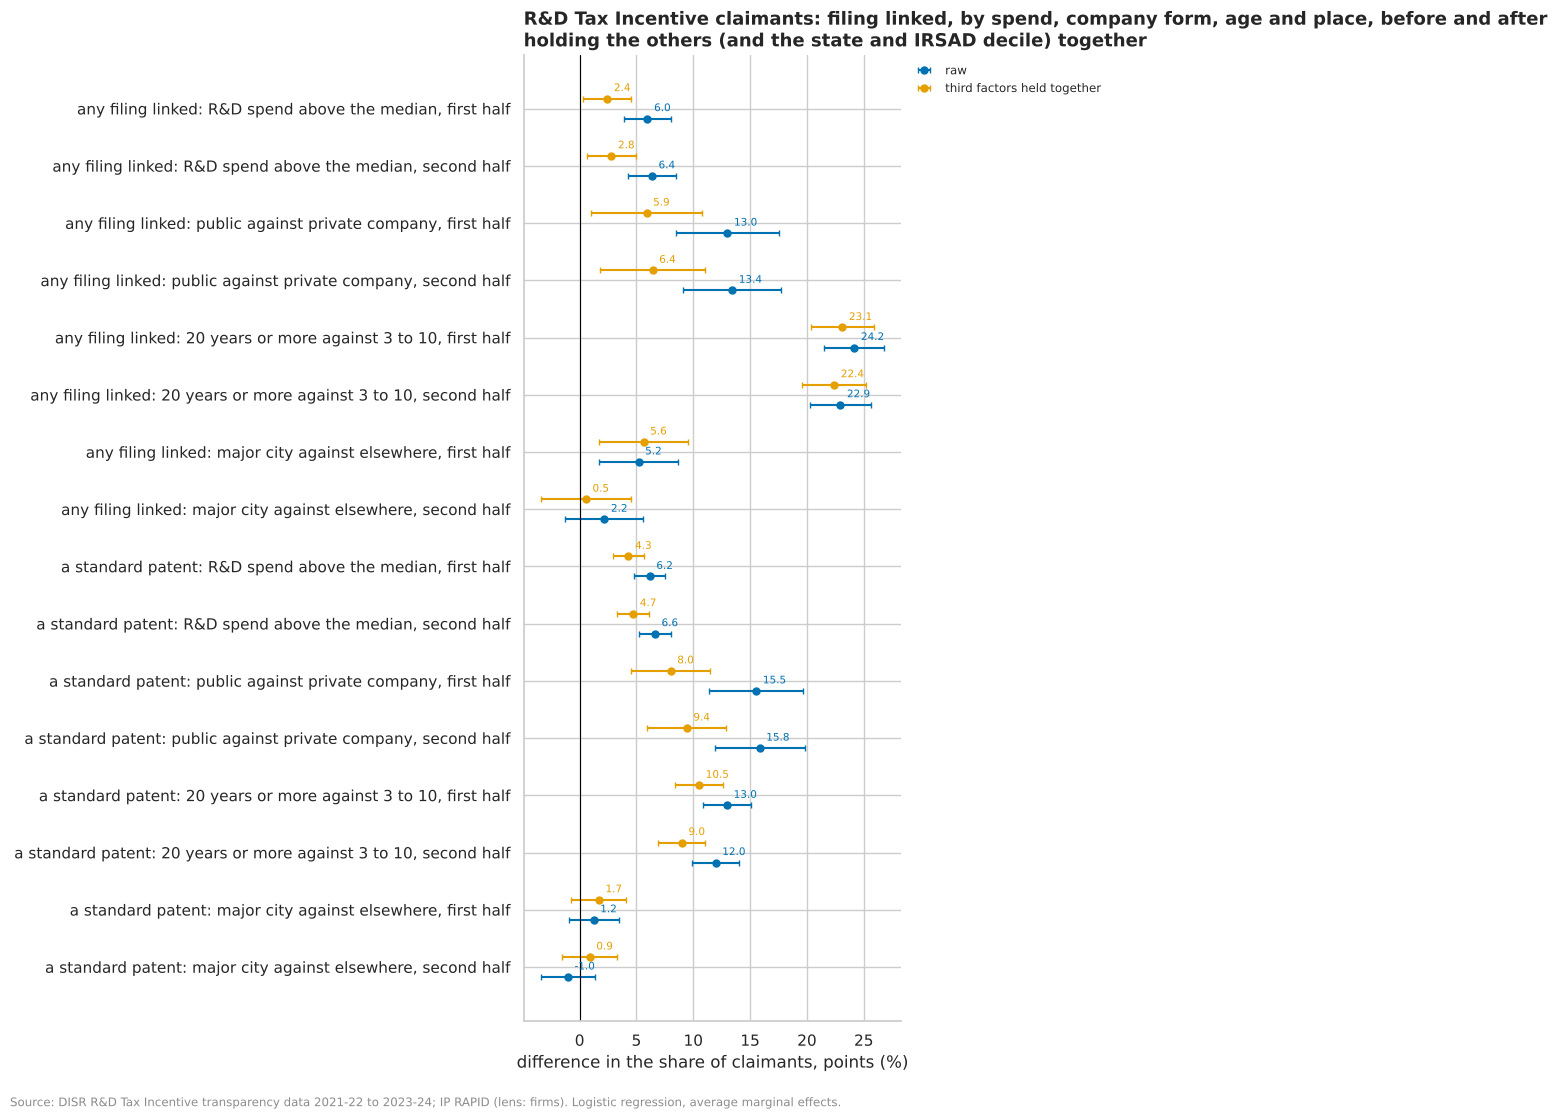

In [18]:
fig = multi.effects_chart(
    rd_effects,
    title="R&D Tax Incentive claimants: filing linked, by spend, company form, age and place, before and after\n"
    "holding the others (and the state and IRSAD decile) together",
    xlabel="difference in the share of claimants, points",
)
style.source(
    fig,
    "DISR R&D Tax Incentive transparency data 2021-22 to 2023-24; IP RAPID (lens: firms). Logistic"
    " regression, average marginal effects.",
)

#### Observations

**M8 (observational). Among R&D Tax Incentive claimants, age goes with having a filing linked almost as strongly with
spend, form and place held; higher R&D spend and being a public company go with a standard patent, held together,
but less with any filing; the city gap does not replicate.** 17,514 active claimants with a recorded spend (median
average claim $326,125; 16,510 private and 969 public companies). Difference in the share of claimants, in points
(raw; held together, with the state and IRSAD decile), first half then second:
- **20 years or more against 3 to 10:** any filing linked +24.2 (21.5 to 26.8) and +23.1 (20.3 to 25.9); +22.9 and
  +22.4 (19.6 to 25.2). A standard patent +13.0 and +10.5 (8.4 to 12.6); +12.0 and +9.0 (6.9 to 11.1). **Holds.**
  Age is on the record at the build date, so an older firm has had longer to file: part of this is time, not kind.
- **R&D spend above the median:** a standard patent +6.2 (4.8 to 7.5) and +4.3 (2.9 to 5.7); +6.6 and +4.7 (3.3 to
  6.1), **holds**. Any filing linked +6.0 (3.9 to 8.1) and +2.4 (0.3 to 4.5); +6.4 and +2.8 (0.7 to 4.9),
  **weakened**: the form and age of high spenders account for more than half of their higher filing.
- **Public against private company:** a standard patent +15.5 (11.4 to 19.7) and +8.0 (4.5 to 11.5); +15.8 and +9.4
  (5.9 to 12.9), **holds** (51.5% and 59.5% remaining). Any filing +13.0 and +5.9 (1.0 to 10.8); +13.4 and +6.4 (1.8 to
  11.1), **weakened**.
- **Major city against elsewhere:** any filing +5.2 (1.7 to 8.6) and +5.6 (1.7 to 9.6) in the first half, but +2.2
  (-1.3 to 5.6) and +0.5 (-3.4 to 4.5) in the second: **does not replicate**. A standard patent: not detected either
  way in both halves. (B22 found the city gap among government suppliers; among claimants it is not a lead.)
- **So** for Q3 and Q4: B23's reading that R&D spend goes only weakly with patenting stands (about 4 to 5 points for
  spending above the median, held together), and younger claimants are far less often linked to a filing at the
  same spend, form and place. "No filing linked" is not "never filed" (ADR 0036).

### 2.2 Government suppliers: contracts and their value, with the filer's form, age and place held together

**Revisits:** B24. **Informs:** Q3, Q4. Stage 2 found that suppliers with a filing linked hold more contracts and more
contract value, in each entity group shown but trusts. Here the number of contracts is modelled as a negative
binomial and the total value (at each contract's latest amendment) as a gamma model with a log link, both as ratios:
a firm with a filing linked against one without, with the **entity group**, **age**, **state**, **remoteness** and
**IRSAD decile** held together. Active ABNs with a contract, in each half. The ratio says how many times as many
contracts (or as much value) a firm with a filing linked has, at the same form, age and place.

In [19]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

sup = sql(
    f"""
    SELECT {FIRM_COLUMNS}, austender_contracts AS contracts, austender_value / 1e3 AS value_k
    FROM {{lens/firms}} WHERE abn_active AND in_austender AND austender_contracts > 0
""",
    max_rows=None,
)
HELD = " + ".join(f"C({c})" for c in ("entity_group", "age", "state", "remoteness", "irsad_decile"))
rows = []
for half, d in sup.groupby("half"):
    for model, rhs in (("raw", "filed"), ("held together", f"filed + {HELD}")):
        nb = multi.nb_rate_ratios(d, f"contracts ~ {rhs}").loc[["filed"]]
        rows.append(nb.assign(measure="contracts", model=model, half=half))
        v = d[d.value_k > 0]
        fit = smf.glm(f"value_k ~ {rhs}", v, family=sm.families.Gamma(sm.families.links.Log())).fit(scale="X2")
        lo, hi = np.exp(fit.conf_int().loc["filed"])
        rows.append(
            pd.DataFrame(
                {
                    "rate ratio": [np.exp(fit.params["filed"])],
                    "low": [lo],
                    "high": [hi],
                    "rows": [int(fit.nobs)],
                    "measure": ["contract value"],
                    "model": [model],
                    "half": [half],
                }
            )
        )
supply = pd.concat(rows).set_index(["measure", "half", "model"]).sort_index()
print(f"Suppliers: {len(sup):,}; with a filing linked: {sup.filed.mean():.2%}")
supply[["rate ratio", "low", "high", "rows"]].round(3)

Suppliers: 52,884; with a filing linked: 25.05%


rate ratio   low  high   rows
measure        half        model                                       
contract value first half  held together       2.969 2.117 4.166  26287
                           raw                 4.437 2.715  7.25  26287
               second half held together        2.72 1.972  3.75  26597
                           raw                 5.352 3.209 8.926  26597
contracts      first half  held together       2.382 2.272 2.496  26287
                           raw                  3.95 3.775 4.133  26287
               second half held together       2.603 2.485 2.728  26597
                           raw                 4.742 4.534 4.958  26597

#### Observations

**M9 (observational). Government suppliers with a filing linked hold about two and a half times as many contracts and
nearly three times the contract value of those without, with the entity group, age, state, remoteness and IRSAD decile
held together.** 52,884 active suppliers, 25.05% with a filing linked. Ratios, a filing linked against none (raw; held
together), first half then second:
- **Contracts** (negative binomial): 3.950 (3.775 to 4.133) and 2.382 (2.272 to 2.496); 4.742 (4.534 to 4.958) and
  2.603 (2.485 to 2.728). On a log scale 63% and 61% of the raw ratio remains: **holds**.
- **Contract value** (gamma model, at each contract's latest amendment): 4.437 (2.715 to 7.250) and 2.969 (2.117 to
  4.166); 5.352 (3.209 to 8.926) and 2.720 (1.972 to 3.750); 73% and 60% remains on a log scale: **holds**.
- Not a cause in either direction: larger suppliers may both file and win more, and firm size is not in the model
  (known only for employers of 100 or more, section 2.4). B24's reading holds with age and place held.

### 2.3 Which comes first, a trade mark or a patent: by cohorts of firms, not a window of filings

**Revisits:** B25 (the final review's "window-free within-firm order"). **Informs:** Q2. B25 found that, of firms whose
first trade mark and first standard patent were both filed FY2010 to FY2026, 72.86% filed the trade mark first. A
window on the filings favours pairs filed close together: a firm whose first trade mark came in 2005 and first patent
in 2015 is left out. Here firms are followed by **cohort**, the year of their first public registration (2001 to 2005,
2006 to 2010, 2011 to 2015), to the end of the data, whenever their first filings fell; only firms whose registration
date is not truncated are used, and a first filing dated before the registration is kept and counted (it is on the
record). Of the firms in each cohort that have filed both, the share whose first trade mark came first, with Wilson
intervals, in each half; and how many of the cohort have filed both, so the selection is visible. A cohort followed
for longer has had more time to file its second kind of right, so the later cohorts' shares lean to pairs filed
close together, as B25's did.

In [20]:
order = sql(f"""
    SELECT {FIRM_HALF} AS half,
           CASE WHEN year(first_seen) BETWEEN 2001 AND 2005 THEN '2001-2005'
                WHEN year(first_seen) BETWEEN 2006 AND 2010 THEN '2006-2010'
                WHEN year(first_seen) BETWEEN 2011 AND 2015 THEN '2011-2015' END AS cohort,
           count(*) AS firms,
           count(*) FILTER (trade_mark_first_date_filled IS NOT NULL AND patent_first_date_filled IS NOT NULL) AS both,
           count(*) FILTER (trade_mark_first_date_filled < patent_first_date_filled) AS trade_mark_first,
           count(*) FILTER (trade_mark_first_date_filled = patent_first_date_filled) AS same_day,
           median(abs(date_diff('day', trade_mark_first_date_filled, patent_first_date_filled)) / 365.25)
               FILTER (trade_mark_first_date_filled IS NOT NULL AND patent_first_date_filled IS NOT NULL)
               AS median_years_apart
    FROM {{lens/firms}}
    WHERE NOT age_truncated AND year(first_seen) BETWEEN 2001 AND 2015
    GROUP BY ALL ORDER BY cohort, half
""")
order["trade mark first (%)"] = 100 * order.trade_mark_first / order.both
lo, hi = bi.wilson(order.trade_mark_first, order.both)
order["low"], order["high"] = 100 * lo, 100 * hi
order["filed both (% of cohort)"] = 100 * order.both / order.firms
order.set_index(["cohort", "half"]).round(2)

firms  both  trade_mark_first  same_day  median_years_apart  trade mark first (%)   low  high  filed both (% of cohort)
cohort    half                                                                                                                                
2001-2005 first half   21321   762               488         2                4.04                 64.04 60.57 67.37                      3.57
          second half  21558   752               497         3                4.85                 66.09 62.63 69.38                      3.49
2006-2010 first half   29143   841               572         0                3.61                 68.01 64.79 71.08                      2.89
          second half  29295   880               601         2                2.96                  68.3 65.15 71.28                         3
2011-2015 first half   37477  1041               715         0                2.79                 68.68  65.8 71.43                      2.78
          second half  37847  1114               774         1                2.92                 69.48 66.71 72.11                      2.94

#### Observations

**M10 (descriptive). Followed by cohort rather than a window of filings, about two thirds of firms that file both
filed a trade mark before their first standard patent, a little less than B25's 72.86%, and less in the older
cohort.** Firms by the year of first public registration, not truncated, with both a first trade mark and a first
standard patent at any date (first half; second half):
- **2001 to 2005:** 64.04% (60.57% to 67.37%) of 762; 66.09% (62.63% to 69.38%) of 752; a median 4.04 and 4.85 years
  between the two. **2006 to 2010:** 68.01% and 68.30%; 3.61 and 2.96 years. **2011 to 2015:** 68.68% and 69.48%;
  2.79 and 2.92 years.
- Only 2.78% to 3.57% of each cohort's firms in the lens have filed both, and almost none on the same day (0 to 3).
- **Revisits B25:** its window (both first filings in FY2010 to FY2026) favoured pairs filed close together. With
  cohorts the order holds, but the share is lower, and lowest (64% to 66%) in the cohort followed longest, whose
  later second filings the window cut off. The later cohorts have had less time, so their shares still lean to
  pairs filed close together.

### 2.4 Size and industry together, among employers of 100 or more (WGEA)

**Revisits:** B50, B51. **Informs:** Q2, Q3. Stage 2 found that among employers of 100 or more, filing rises with size
(read over every employer, not only those the lens holds: ADR 0043) and is sorted by industry, and that R&D spend's
weak link to patenting holds within size. Here (a) the size gap, employers of 1,000 or more against those under 250,
is modelled with the **ANZSIC division** held, over every employer with a WGEA report (those outside the lens counted
as having no filing linked, as in B50); only WGEA's own fields are held, since anything taken from the lens (age,
place) is missing for exactly the employers with no link; and (b) among WGEA employers claiming the R&D Tax Incentive,
R&D spend above their median is modelled with the **size band** and **division** held. Each in the two halves of the
employers.

In [21]:
from eda import build

every = sql(f"""
    WITH e AS (SELECT abn, arg_max(employer_size, reporting_year) AS wgea_size_band,
                      arg_max(lpad(anzsic_code, 4, '0'), reporting_year) AS anzsic_class
               FROM {{wgea/employers}} WHERE anzsic_code ~ '^[0-9]+$' GROUP BY 1)
    SELECT CASE WHEN {bi.half_sql("e.abn")} THEN 'first half' ELSE 'second half' END AS half, e.wgea_size_band,
           coalesce({build._division_of("e.anzsic_class")}, 'unknown') AS division,
           f.abn IS NOT NULL AS in_lens, coalesce(f.ip_record = 'filed', false)::INT AS filed,
           coalesce(f.n_patents_standard > 0, false)::INT AS patent,
           coalesce(f.n_trade_marks > 0, false)::INT AS trade_mark,
           coalesce(f.in_rdti, false) AS in_rdti, f.rd_latest
    FROM e LEFT JOIN {{lens/firms}} f USING (abn) ORDER BY e.abn
""")
print(
    f"WGEA employers (latest report): {len(every):,}; in the lens: {int(every.in_lens.sum()):,};",
    "by size band:",
    every.wgea_size_band.value_counts().to_dict(),
)
size = every[every.wgea_size_band.isin(["<250", "1000-4999", "5000+"])].assign(
    large=lambda d: d.wgea_size_band.isin(["1000-4999", "5000+"]).astype(int)
)
rows = []
for outcome, oname in (("filed", "any filing linked"), ("patent", "a standard patent"), ("trade_mark", "a trade mark")):
    for half, d in size.groupby("half"):
        r = multi.adjusted_effect(d, outcome, "large", ["division"])
        rows.append(r.rename(f"{oname}: 1,000 or more against under 250, {half}"))
wrd = every[every.in_rdti & every.rd_latest.notna()].copy()
wrd["high_spend"] = (wrd.rd_latest > wrd.rd_latest.median()).astype(int)
print(
    f"WGEA employers claiming the R&D Tax Incentive with a spend: {len(wrd):,};",
    f"median latest claim ${wrd.rd_latest.median():,.0f}",
)
for half, d in wrd.groupby("half"):
    r = multi.adjusted_effect(d, "patent", "high_spend", ["wgea_size_band", "division"])
    rows.append(r.rename(f"a standard patent: R&D spend above the claimants' median, {half}"))
wgea = pd.DataFrame(rows)
wgea[EFFECT].round(3)

WGEA employers (latest report): 9,742; in the lens: 7,126; by size band: {'<250': 5208, '250-499': 2200, '500-999': 1171, '1000-4999': 1002, '5000+': 155, 'NA': 6}


WGEA employers claiming the R&D Tax Incentive with a spend: 509; median latest claim $2,194,930


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"any filing linked: 1,000 or more against under 250, first half",3189,0.653,0.483,0.17,0.126,0.213,0.191,0.149,0.233,1.124,24,holds
"any filing linked: 1,000 or more against under 250, second half",3176,0.669,0.49,0.18,0.137,0.222,0.203,0.162,0.244,1.13,0,holds
"a standard patent: 1,000 or more against under 250, first half",3189,0.148,0.074,0.074,0.043,0.105,0.121,0.088,0.155,1.638,239,holds
"a standard patent: 1,000 or more against under 250, second half",3176,0.21,0.077,0.134,0.099,0.168,0.16,0.125,0.194,1.196,0,holds
"a trade mark: 1,000 or more against under 250, first half",3189,0.64,0.469,0.171,0.127,0.215,0.19,0.148,0.233,1.114,24,holds
"a trade mark: 1,000 or more against under 250, second half",3176,0.644,0.477,0.167,0.124,0.21,0.19,0.149,0.232,1.137,0,holds
"a standard patent: R&D spend above the claimants' median, first half",262,0.37,0.222,0.148,0.038,0.257,0.147,0.037,0.256,0.991,131,holds
"a standard patent: R&D spend above the claimants' median, second half",247,0.362,0.267,0.096,-0.02,0.211,0.038,-0.085,0.161,0.401,111,not detected either way


#### Observations

**M11 (observational). Over every employer of 100 or more, the largest file more, and the gap is wider within the same
industry: large employers are in divisions that file less. R&D spend's link to patenting within size and industry
does not replicate in this small group.** 9,742 WGEA employers (latest report), 7,126 of them in the lens. Difference
in the share, employers of 1,000 or more against under 250, in points (raw; with the ANZSIC division held), first
half then second:
- **Any filing linked:** 65.3% against 48.3%, +17.0 (12.6 to 21.3) and +19.1 (14.9 to 23.3); +18.0 (13.7 to 22.2) and
  +20.3 (16.2 to 24.4). **Holds**, and more than holds.
- **A standard patent:** +7.4 (4.3 to 10.5) and +12.1 (8.8 to 15.5); +13.4 (9.9 to 16.8) and +16.0 (12.5 to 19.4).
  **A trade mark:** +17.1 and +19.0 (14.8 to 23.3); +16.7 and +19.0 (14.9 to 23.2). **Holds.**
- **R&D spend above the median** of the 509 WGEA employers claiming the R&D Tax Incentive (median latest claim
  $2,194,930), with the size band and division held: a standard patent +14.8 (3.8 to 25.7) and +14.7 (3.7 to 25.6)
  in the first half, but +9.6 (-2.0 to 21.1) and +3.8 (-8.5 to 16.1) in the second: **does not replicate**. B51's
  reading (a weak link within size) is consistent with this; with about 250 employers in each half, little can be
  detected either way.
- Size is known only for WGEA reporters (OQ20), so these are large employers only; they are not the firms most IP
  filers are.

### 2.5 Firms' IP counts checked against a name match to the ABR and ASIC

**From:** A30, ADR 0045, ADR 0047. **Revisits:** U44, U45, M8. **Informs:** Q2, Q3. Firms' IP counts are lower bounds:
a right is credited to a firm only where IP RAPID, or IP Australia's register, gives the filer's ABN (U41, U45). Here
Australian organisations' rights with no filer's ABN are matched by the filer's name to the ABR's main names and
ASIC's company names (current and former), a match kept only if exactly one ABN has the name and is registered in the
filer's state (`name_matched_abn` in the `rights` lens, built by `build.name_match_sql`). Three parts:

1. **The test** (ADR 0045, point 3): the same match run on rights whose ABN is known, with the ABN hidden: the share
   recovered, and the share of matches that name another ABN, by type of right and decade. The postcode, which ADR
   0045 first included, is shown as a variant: it halves the matches without making them more accurate (ADR 0047).
2. **U45 again:** the share of Australian organisations' rights with a filer's ABN, by year, with and without the
   matched links, and first observed linked filers by year.
3. **The firm leads again:** U44's concentration and M8's claimants, with the matched links beside the counts.

The matched links are never added to the counts (ADR 0045, point 4); every figure that uses them is labelled.

In [22]:
from eda import build

# The test runs the build's own match on rights whose filer's ABN is known, with that ABN hidden
MASKED = """(SELECT ip_right_type, application_number, filer_group, NULL AS filer_abn, filer_abn AS known_abn,
                    coalesce(patent_type, ip_right_type) AS t, filing_fy
             FROM {lens/rights}
             WHERE filer_group = 'australian_organisation' AND filer_abn IS NOT NULL AND filing_fy >= 2000)"""
test = sql(f"""
    WITH masked AS {MASKED},
    {build.name_match_sql("masked")}
    SELECT t, CASE WHEN filing_fy < 2010 THEN 'FY2000-FY2009' WHEN filing_fy < 2020 THEN 'FY2010-FY2019'
                   ELSE 'FY2020-FY2026' END AS period,
           count(*) AS rights, count(m.name_matched_abn) AS matched,
           count(*) FILTER (m.name_matched_abn = known_abn) AS recovered
    FROM masked LEFT JOIN name_match m USING (ip_right_type, application_number)
    GROUP BY ALL ORDER BY ALL
""")
test["matched (%)"] = 100 * test.matched / test.rights
test["recovered (%)"] = 100 * test.recovered / test.rights
test["another ABN (% of matched)"] = 100 * (test.matched - test.recovered) / test.matched
lo, hi = bi.wilson(test.matched - test.recovered, test.matched)
test["low"], test["high"] = 100 * lo, 100 * hi
test.set_index(["t", "period"]).round(2)

rights  matched  recovered  matched (%)  recovered (%)  another ABN (% of matched)  low  high
t           period                                                                                                      
design      FY2000-FY2009   10707     7842       7070        73.24          66.03                        9.84  9.2 10.52
            FY2010-FY2019   16501    12889      12650        78.11          76.66                        1.85 1.64   2.1
            FY2020-FY2026   12016    10220      10104        85.05          84.09                        1.14 0.95  1.36
provisional FY2000-FY2009   25137    19120      18283        76.06          72.73                        4.38  4.1  4.68
            FY2010-FY2019   23711    19626      19260        82.77          81.23                        1.86 1.68  2.06
            FY2020-FY2026   17199    14851      14620        86.35             85                        1.56 1.37  1.77
second_tier FY2000-FY2009    2282     1687       1612        73.93          70.64                        4.45 3.56  5.54
            FY2010-FY2019    4443     3660       3562        82.38          80.17                        2.68  2.2  3.25
            FY2020-FY2026    1875     1618       1594        86.29          85.01                        1.48    1   2.2
standard    FY2000-FY2009   12285     9467       9067        77.06          73.81                        4.23 3.84  4.65
            FY2010-FY2019   16411    13689      13407        83.41           81.7                        2.06 1.84  2.31
            FY2020-FY2026   13292     9165       9018        68.95          67.85                         1.6 1.37  1.88
trade_mark  FY2000-FY2009  204120   144030     137073        70.56          67.15                        4.83 4.72  4.94
            FY2010-FY2019  268761   212017     205845        78.89          76.59                        2.91 2.84  2.98
            FY2020-FY2026  251266   200041     194480        79.61           77.4                        2.78 2.71  2.85

In [23]:
# The variant with the postcode as well (where both are known), and the match rate of the rights with no ABN
POSTCODE = build.name_match_sql("masked", postcode=True)
variant = sql(f"""
    WITH masked AS {MASKED},
    {POSTCODE}
    SELECT t, count(*) AS rights, count(m.name_matched_abn) AS matched,
           count(*) FILTER (m.name_matched_abn = known_abn) AS recovered
    FROM masked LEFT JOIN name_match m USING (ip_right_type, application_number)
    GROUP BY ALL ORDER BY ALL
""")
variant["matched (%)"] = 100 * variant.matched / variant.rights
variant["another ABN (% of matched)"] = 100 * (variant.matched - variant.recovered) / variant.matched
print("With the postcode as well (FY2000 to FY2026):")
display(variant.set_index("t").round(2))
unlinked = sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t, count(*) AS rights_with_no_abn,
           count(name_matched_abn) AS matched_by_name
    FROM {lens/rights}
    WHERE filer_group = 'australian_organisation' AND filer_abn IS NULL AND filing_fy >= 2000
    GROUP BY ALL ORDER BY ALL
""")
unlinked["matched (%)"] = 100 * unlinked.matched_by_name / unlinked.rights_with_no_abn
print("Rights with no filer's ABN, FY2000 to FY2026, and those matched by name (state agreeing):")
unlinked.set_index("t").round(2)

With the postcode as well (FY2000 to FY2026):


,rights,matched,recovered,matched (%),another ABN (% of matched)
t,,,,,
design,39224,18057,17207,46.04,4.71
provisional,66047,28861,28112,43.7,2.6
second_tier,8600,3711,3623,43.15,2.37
standard,41988,19136,18689,45.57,2.34
trade_mark,724147,308607,298059,42.62,3.42


Rights with no filer's ABN, FY2000 to FY2026, and those matched by name (state agreeing):


,rights_with_no_abn,matched_by_name,matched (%)
t,,,
design,8275,2171,26.24
pbr,3220,0,0
provisional,18317,6183,33.76
second_tier,2216,575,25.95
standard,9104,3217,35.34
trade_mark,117531,20845,17.74


rights                     filer's ABN (%)                     with the matched links (%)                    
t         design standard trade_mark          design standard trade_mark                     design standard trade_mark
filing_fy                                                                                                              
2015        1812     1615      32633            85.6    85.39       84.9                      92.49     89.1      87.56
2016        2123     1957      35532           87.56    84.26      84.67                      92.89    89.63      87.13
2017        1938     2012      34620           87.62    86.23      84.46                       90.2    90.31      86.68
2018        2138     2142      36211           81.48    86.93       85.4                      88.26    90.66      87.84
2019        2116     2158      34096           90.41    87.21      87.45                      91.68    90.78      90.02
2020        1686     2040      34650           90.98    87.35      88.74                      92.29    91.23       90.9
2021        1888     2041      40609           90.15    88.98      87.74                      92.06    91.96      89.81
2022        1650     2341      38150           89.09    88.98      90.11                      91.15    91.97      91.67
2023        1704     1987      35369           89.55    88.17      91.16                      90.38    89.83      92.43
2024        1838     2005      36243           92.27    88.68      92.34                      92.76    89.43      93.01
2025        2025     2044      37884           91.06    87.23      91.39                      92.35    89.82      92.82
2026        2241     2186      41309           89.34    83.85      90.94                      90.72     89.2      92.91

basis filer ABN            with the matched links           
t      standard trade_mark               standard trade_mark
fy                                                          
2015        556       8837                    565       9000
2016        617       9621                    637       9739
2017        661       9192                    674       9307
2018        716      10161                    746      10297
2019        675      11924                    686      12048
2020        660      13301                    675      13387
2021        703      14634                    715      14777
2022        817      14298                    830      14386
2023        628      13967                    638      13989
2024        633      14734                    633      14698
2025        591      15828                    617      16057
2026        542      19737                    616      20093

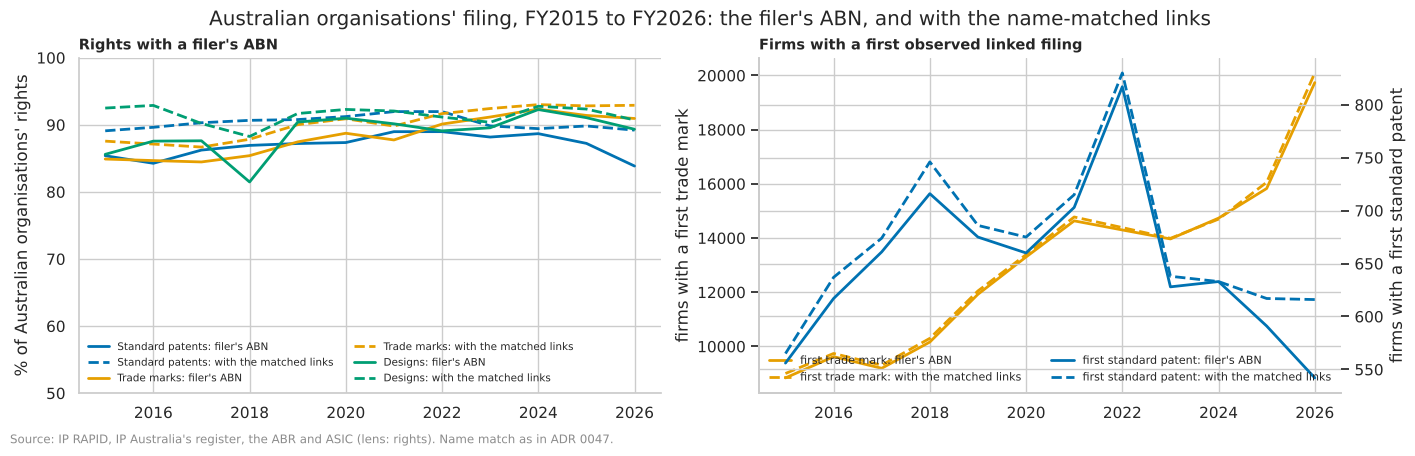

In [24]:
# U45 again: the share of Australian organisations' rights with a filer's ABN, by financial year, with the matched
# links beside it; and firms with a first observed linked filing in each year, by the filer's ABN alone and with the
# matched links (a firm's first filing by either)
link = sql("""
    SELECT coalesce(patent_type, ip_right_type) AS t, filing_fy, count(*) AS rights,
           count(filer_abn) AS with_abn, count(coalesce(filer_abn, name_matched_abn)) AS with_abn_or_match
    FROM {lens/rights}
    WHERE filer_group = 'australian_organisation' AND filing_fy BETWEEN 2015 AND 2026
      AND coalesce(patent_type, ip_right_type) IN ('standard', 'trade_mark', 'design')
    GROUP BY ALL ORDER BY ALL
""")
link["filer's ABN (%)"] = 100 * link.with_abn / link.rights
link["with the matched links (%)"] = 100 * link.with_abn_or_match / link.rights
first = sql("""
    WITH f AS (
        SELECT coalesce(patent_type, ip_right_type) AS t, filer_abn, name_matched_abn, filing_fy
        FROM {lens/rights}
        WHERE coalesce(patent_type, ip_right_type) IN ('standard', 'trade_mark') AND filing_fy >= 1980
    ),
    by_abn AS (SELECT t, filer_abn AS abn, min(filing_fy) AS fy FROM f WHERE filer_abn IS NOT NULL GROUP BY ALL),
    by_either AS (
        SELECT t, coalesce(filer_abn, name_matched_abn) AS abn, min(filing_fy) AS fy FROM f
        WHERE coalesce(filer_abn, name_matched_abn) IS NOT NULL GROUP BY ALL
    )
    SELECT t, fy, count(*) AS firms, 'filer ABN' AS basis FROM by_abn WHERE fy BETWEEN 2015 AND 2026 GROUP BY ALL
    UNION ALL
    SELECT t, fy, count(*), 'with the matched links' FROM by_either WHERE fy BETWEEN 2015 AND 2026 GROUP BY ALL
""").pivot_table(index=["t", "fy"], columns="basis", values="firms")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for i, (t, name) in enumerate((("standard", "Standard patents"), ("trade_mark", "Trade marks"), ("design", "Designs"))):
    d = link[link.t == t]
    axes[0].plot(d.filing_fy, d["filer's ABN (%)"], color=style.PALETTE[i], lw=2, label=f"{name}: filer's ABN")
    axes[0].plot(
        d.filing_fy,
        d["with the matched links (%)"],
        color=style.PALETTE[i],
        lw=2,
        ls="--",
        label=f"{name}: with the matched links",
    )
for i, (t, name) in enumerate((("standard", "first standard patent"), ("trade_mark", "first trade mark"))):
    d = first.xs(t)
    ax = axes[1] if t == "trade_mark" else axes[1].twinx()
    ax.plot(d.index, d["filer ABN"], color=style.PALETTE[i], lw=2, label=f"{name}: filer's ABN")
    ax.plot(
        d.index,
        d["with the matched links"],
        color=style.PALETTE[i],
        lw=2,
        ls="--",
        label=f"{name}: with the matched links",
    )
    ax.set_ylabel(f"firms with a {name}")
    ax.legend(frameon=False, fontsize=8, loc="lower left" if t == "trade_mark" else "lower right")
axes[0].set_ylabel("% of Australian organisations' rights")
axes[0].set_ylim(50, 100)
axes[0].legend(frameon=False, fontsize=7.5, ncol=2, loc="lower left")
axes[0].set_title("Rights with a filer's ABN", fontsize=10.5)
axes[1].set_title("Firms with a first observed linked filing", fontsize=10.5)
fig.suptitle("Australian organisations' filing, FY2015 to FY2026: the filer's ABN, and with the name-matched links")
style.source(fig, "IP RAPID, IP Australia's register, the ABR and ASIC (lens: rights). Name match as in ADR 0047.")
display(
    link.set_index(["t", "filing_fy"])[["rights", "filer's ABN (%)", "with the matched links (%)"]]
    .round(2)
    .unstack("t")
)
first.astype(int).unstack("t")

In [25]:
# U44 and M8 again. U44: the share of standard patents and trade marks filed by the top 1% of filing firms, with and
# without the matched links. M8: R&D Tax Incentive claimants with no filing linked, and how many gain one by name
conc = sql("""
    WITH f AS (
        SELECT abn, n_patents_standard AS s, n_patents_standard + n_patents_standard_name_matched AS s_m,
               n_trade_marks AS m, n_trade_marks + n_trade_marks_name_matched AS m_m
        FROM {lens/firms}
    )
    SELECT 'standard patents' AS t, 'filer ABN' AS basis, count(*) FILTER (s > 0) AS firms, sum(s) AS filings,
           (SELECT sum(s) FROM (SELECT s FROM f WHERE s > 0 ORDER BY s DESC, abn
                                LIMIT (SELECT ceil(count(*) / 100) FROM f WHERE s > 0))) AS top_1pct FROM f
    UNION ALL
    SELECT 'standard patents', 'with the matched links', count(*) FILTER (s_m > 0), sum(s_m),
           (SELECT sum(s_m) FROM (SELECT s_m FROM f WHERE s_m > 0 ORDER BY s_m DESC, abn
                                  LIMIT (SELECT ceil(count(*) / 100) FROM f WHERE s_m > 0))) FROM f
    UNION ALL
    SELECT 'trade marks', 'filer ABN', count(*) FILTER (m > 0), sum(m),
           (SELECT sum(m) FROM (SELECT m FROM f WHERE m > 0 ORDER BY m DESC, abn
                                LIMIT (SELECT ceil(count(*) / 100) FROM f WHERE m > 0))) FROM f
    UNION ALL
    SELECT 'trade marks', 'with the matched links', count(*) FILTER (m_m > 0), sum(m_m),
           (SELECT sum(m_m) FROM (SELECT m_m FROM f WHERE m_m > 0 ORDER BY m_m DESC, abn
                                  LIMIT (SELECT ceil(count(*) / 100) FROM f WHERE m_m > 0))) FROM f
""")
conc[["firms", "filings", "top_1pct"]] = conc[["firms", "filings", "top_1pct"]].astype(int)
conc["top 1% share (%)"] = 100 * conc.top_1pct / conc.filings
display(conc.set_index(["t", "basis"]).sort_index().round(2))
claim = sql(f"""
    SELECT {FIRM_HALF} AS half, count(*) AS claimants, count(*) FILTER ({FILED}) AS filed,
           count(*) FILTER (NOT {FILED} AND n_patents_standard_name_matched + n_patents_provisional_name_matched
                            + n_trade_marks_name_matched + n_designs_name_matched > 0) AS gain_by_name,
           count(*) FILTER (n_patents_standard = 0 AND n_patents_standard_name_matched > 0) AS first_patent_by_name
    FROM {{lens/firms}} WHERE abn_active AND in_rdti AND rd_expenditure_mean > 0 GROUP BY ALL ORDER BY 1
""")
claim["no filing linked (%)"] = 100 * (claim.claimants - claim.filed) / claim.claimants
claim["no filing linked, with the matched links (%)"] = (
    100 * (claim.claimants - claim.filed - claim.gain_by_name) / claim.claimants
)
display(claim.set_index("half").round(2))
# M8's signals again, with a filing linked by name counted as a filing (the same claimants and controls as 2.1)
rows = []
for outcome, oname in (
    ("filed_or_matched", "any filing linked or matched"),
    ("patent_or_matched", "a standard patent, linked or matched"),
):
    for sig, (sname, others, keep) in SIGNALS.items():
        for half, d in rd.groupby("half"):
            sub = d if keep is None else d[d.entity_group.isin(keep) if sig == "public" else d.age.isin(keep)]
            r = multi.adjusted_effect(sub, outcome, sig, [*others, "state", "irsad_decile"])
            rows.append(r.rename(f"{oname}: {sname}, {half}"))
rd_matched = pd.DataFrame(rows)
rd_matched[EFFECT].round(3)

firms  filings  top_1pct  top 1% share (%)
t                basis                                                              
standard patents filer ABN                23971   183989    101771             55.31
                 with the matched links   24595   187731    103361             55.06
trade marks      filer ABN               301249  1018160    261217             25.66
                 with the matched links  303985  1046707    272343             26.02

,claimants,filed,gain_by_name,first_patent_by_name,no filing linked (%),"no filing linked, with the matched links (%)"
half,,,,,,
first half,8841,4555,69,59,48.48,47.7
second half,8673,4515,69,53,47.94,47.15


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"any filing linked or matched: R&D spend above the median, first half",8841,0.554,0.492,0.062,0.041,0.083,0.025,0.004,0.046,0.398,93,weakened
"any filing linked or matched: R&D spend above the median, second half",8673,0.561,0.496,0.065,0.044,0.086,0.028,0.007,0.049,0.429,87,weakened
"any filing linked or matched: public against private company, first half",8820,0.662,0.515,0.147,0.102,0.192,0.073,0.024,0.122,0.498,70,weakened
"any filing linked or matched: public against private company, second half",8659,0.659,0.521,0.138,0.096,0.181,0.066,0.02,0.113,0.479,68,weakened
"any filing linked or matched: 20 years or more against 3 to 10, first half",6082,0.687,0.437,0.25,0.224,0.276,0.238,0.211,0.266,0.953,59,holds
"any filing linked or matched: 20 years or more against 3 to 10, second half",5924,0.679,0.442,0.236,0.21,0.263,0.232,0.204,0.26,0.982,51,holds
"any filing linked or matched: major city against elsewhere, first half",8841,0.528,0.476,0.052,0.017,0.086,0.054,0.014,0.093,1.038,56,holds
"any filing linked or matched: major city against elsewhere, second half",8673,0.531,0.508,0.023,-0.011,0.058,0.005,-0.034,0.045,0.218,52,not detected either way
"a standard patent, linked or matched: R&D spend above the median, first half",8841,0.163,0.097,0.067,0.053,0.081,0.045,0.031,0.06,0.678,93,holds
"a standard patent, linked or matched: R&D spend above the median, second half",8673,0.17,0.097,0.073,0.059,0.088,0.053,0.038,0.067,0.717,87,holds


#### Observations

**M12 (descriptive). A name match to the ABR and ASIC recovers a known ABN for 66% to 85% of Australian
organisations' rights, with 1.1% to 4.8% of matches naming another ABN (older designs 9.8%); applied to the rights
with no ABN it links 17.7% to 35.3% of them, and it changes no firm finding: it closes most of the recent fall in
standard patents linked to an ABN, and moves concentration and the claimants' figures by less than a point.**
- **The test** (ABN hidden on rights that have one; the state must agree): standard patents FY2010 to FY2019, 83.41%
  matched and 81.70% recovered, 2.06% of matches another ABN (1.84% to 2.31%); FY2020 to FY2026, 68.95%, 67.85% and
  1.60% (1.37% to 1.88%). Trade marks: 78.89%, 76.59%, 2.91%; then 79.61%, 77.40%, 2.78% (2.71% to 2.85%). Designs
  filed FY2000 to FY2009 are the weakest, 9.84% another ABN; every other type and decade is 1.14% to 4.83%. A
  "wrong" ABN can be a related company of the same group, which the test cannot tell.
- **With the postcode as well** (ADR 0045's first rule): 42.62% to 46.04% matched, with 2.34% to 4.71% another ABN, so
  it halves the matches for no gain in accuracy (ADR 0047).
- **Rights with no filer's ABN, FY2000 to FY2026:** 3,217 of 9,104 standard patents matched (35.34%), 20,845 of
  117,531 trade marks (17.74%), 6,183 of 18,317 provisionals (33.76%), 2,171 of 8,275 designs (26.24%); none of 3,220
  plant breeder's rights (IP RAPID gives none of them an ABN, so the match cannot be tested on them).
- **U45 again:** standard patents with a filer's ABN fall from 88.68% (FY2024) to 83.85% (FY2026); with the matched
  links, 89.43% to 89.20%, so most of the recent fall closes. Trade marks 92.34% to 90.94% become 93.01% to 92.91%;
  designs 92.27% to 89.34% become 92.76% to 90.72%. Firms with a first observed linked standard patent: 660 (FY2020)
  to 542 (FY2026) by the filer's ABN, 675 to 616 with the matched links, so U45's later fall in first patent filers
  is about half a matter of linking (an 18% fall becomes 9%).
- **U44 again:** the top 1% of firms file 55.31% of standard patents by the filer's ABN and 55.06% with the matched
  links (23,971 and 24,595 firms); trade marks 25.66% and 26.02%.
- **M8 again:** R&D Tax Incentive claimants with no filing linked fall from 48.48% to 47.70% (first half) and from
  47.94% to 47.15% (second), 69 claimants gaining a filing by name in each half; every signal of M8 keeps its
  direction and verdict (age +23.8 and +23.2 held together, against +23.1 and +22.4).
- **For the owner** (ADR 0045, point 5): the matched links are reliable enough to read beside the counts, not to
  replace them. Adopting them into the counts is the owner's decision.

### 2.6 Who files among government suppliers, and large taxpayers' income, with form, age and place held together

**Revisits:** B22, B24 (the first pass took up R&D claimants (2.1) and suppliers' contracts (2.2), not who files among
suppliers, nor the large taxpayers; added 3 November 2026). **Informs:** Q2, Q3, Q4. B22 found that among government
suppliers filing goes with company form, age, a city address and an advantaged postcode; B24, that large taxpayers
with a filing linked do not report clearly more income. Here, among active suppliers in each half, each of four
signals is modelled with the others and the state held: a public against a private company, 20 years or more against
3 to 10, a major city against elsewhere, and an IRSAD decile of 8 to 10 against 1 to 7. Then the large taxpayers'
latest total income (the ATO's transparency reports) as a gamma model with a log link: a filing linked against none,
with the entity group, age and state held, as a ratio.

In [26]:
doors = sql(
    f"""
    SELECT {FIRM_COLUMNS}, in_austender, in_ato_ctt, total_income_latest / 1e6 AS income_m
    FROM {{lens/firms}} WHERE abn_active AND (in_austender OR in_ato_ctt)
""",
    max_rows=None,
)
doors["public"] = (doors.entity_group == "Public company").astype(int)
doors["old"] = (doors.age == "20 years or more").astype(int)
doors["city"] = (doors.remoteness == "Major Cities of Australia").astype(int)
doors["advantaged"] = doors.irsad_decile.isin(["8.0", "9.0", "10.0"]).astype(int)
SUPPLIER_SIGNALS = {
    "public": ("public against private company", ["age", "remoteness", "irsad_decile"],
               ("entity_group", ["Public company", "Private company"])),
    "old": ("20 years or more against 3 to 10", ["entity_group", "remoteness", "irsad_decile"],
            ("age", ["20 years or more", "3 to 10 years"])),
    "city": ("major city against elsewhere", ["entity_group", "age", "irsad_decile"], None),
    "advantaged": ("IRSAD decile 8 to 10 against 1 to 7", ["entity_group", "age", "remoteness"], None),
}  # fmt: skip
suppliers = doors[doors.in_austender.fillna(False)]
rows = []
for sig, (sname, others, keep) in SUPPLIER_SIGNALS.items():
    for half, d in suppliers.groupby("half"):
        sub = d if keep is None else d[d[keep[0]].isin(keep[1])]
        rows.append(multi.adjusted_effect(sub, "filed", sig, [*others, "state"]).rename(f"{sname}, {half}"))
supplier_fx = pd.DataFrame(rows)
display(supplier_fx[EFFECT].round(3))
taxpayers = doors[doors.in_ato_ctt.fillna(False) & (doors.income_m > 0)]
rows = []
for half, d in taxpayers.groupby("half"):
    for model, rhs in (("raw", "filed"), ("held together", "filed + C(entity_group) + C(age) + C(state)")):
        fit = smf.glm(f"income_m ~ {rhs}", d, family=sm.families.Gamma(sm.families.links.Log())).fit(scale="X2")
        lo_, hi_ = np.exp(fit.conf_int().loc["filed"])
        rows.append(
            {
                "half": half,
                "model": model,
                "income ratio": np.exp(fit.params["filed"]),
                "low": lo_,
                "high": hi_,
                "taxpayers": int(fit.nobs),
                "with a filing linked (%)": 100 * d.filed.mean(),
            }
        )
print(f"Active suppliers: {len(suppliers):,}; large taxpayers with a latest income: {len(taxpayers):,}")
pd.DataFrame(rows).set_index(["half", "model"]).round(3)

,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
"public against private company, first half",16300,0.651,0.314,0.337,0.31,0.365,0.312,0.283,0.34,0.924,30,holds
"public against private company, second half",16580,0.637,0.312,0.325,0.297,0.352,0.292,0.264,0.32,0.899,25,holds
"20 years or more against 3 to 10, first half",14604,0.357,0.142,0.215,0.201,0.229,0.146,0.131,0.161,0.679,17,holds
"20 years or more against 3 to 10, second half",14788,0.356,0.139,0.217,0.203,0.231,0.143,0.128,0.159,0.66,12,holds
"major city against elsewhere, first half",26287,0.278,0.152,0.125,0.114,0.136,0.123,0.109,0.138,0.984,63,holds
"major city against elsewhere, second half",26597,0.28,0.144,0.136,0.125,0.147,0.132,0.118,0.146,0.971,0,holds
"IRSAD decile 8 to 10 against 1 to 7, first half",26287,0.267,0.221,0.046,0.035,0.057,-0,-0.012,0.012,-0.003,63,not detected once held
"IRSAD decile 8 to 10 against 1 to 7, second half",26597,0.269,0.218,0.051,0.04,0.061,-0.005,-0.017,0.007,-0.097,0,not detected once held


Active suppliers: 52,884; large taxpayers with a latest income: 6,310


income ratio   low  high  taxpayers  with a filing linked (%)
half        model                                                                       
first half  raw                   1.393 1.077 1.802       3184                     40.45
            held together         0.824 0.685  0.99       3184                     40.45
second half raw                   1.601 1.214 2.111       3126                      41.2
            held together         0.961 0.803  1.15       3126                      41.2

#### Observations

**M29 (observational). Among government suppliers, company form, age and a city address each go with a filing linked
with the others held, in both halves; the advantaged postcode does not once they are. Large taxpayers with a filing
linked do not report more income once their form, age and state are held.** 52,884 active suppliers; difference in
the share with a filing linked, in points (raw; with the others and the state held), first half then second:
- **Public against private company:** 65.1% against 31.4%, raw +33.7, held together +31.2 (28.3 to 34.0); +32.5 and
  +29.2 (26.4 to 32.0). **Holds.**
- **20 years or more against 3 to 10:** +21.5 and +14.6 (13.1 to 16.1); +21.7 and +14.3 (12.8 to 15.9). **Holds**
  (67.9% and 66.0% remaining). Age is on the record at the build date (ADR 0039).
- **Major city against elsewhere:** +12.5 and +12.3 (10.9 to 13.8); +13.6 and +13.2 (11.8 to 14.6). **Holds.**
- **IRSAD decile 8 to 10 against 1 to 7:** +4.6 (3.5 to 5.7) raw, -0.0 (-1.2 to 1.2) held; +5.1 and -0.5 (-1.7 to
  0.7): **not detected once held**. **Revisits B22:** the suppliers' gradient by advantage of postcode is their form,
  age and city address.
- **Large taxpayers** (6,310 with a latest income; 40.45% and 41.20% with a filing linked): the ratio of mean income,
  a filing linked against none, 1.393 (1.077 to 1.802) raw and 0.824 (0.685 to 0.990) held in the first half,
  **reversed**; 1.601 (1.214 to 2.111) and 0.961 (0.803 to 1.150) in the second, **not detected once held**. B24's
  reading (no clearly more income) stands, and with form, age and state held it is, if anything, less.
- Size is not held (it is in the lens only for WGEA's employers); associations, not causes.

### 2.7 The filing firm's age and patents now held only overseas, with grant, reach and field held

**Revisits:** B26 (carried in the row "who owns what is made here"; added 3 November 2026). **Informs:** Q1, Q2. B26
found, by firm, that the youngest filers are not clearly more often those whose Australian-founded patents are now held
only overseas, and that patents filed before the firm's first public registration are the most often held overseas.
Here M6's model (1.5) is joined to the filing firm by the filer's ABN (firms whose registration date is not truncated,
as B26): the share now held only overseas for firms under 2 years old when they filed, and for patents filed before
the firm's first registration, each against firms 10 years or more, with grant, reach, field, route, filing year and
founders held; clustered by the firm (its ABN), in B26's two periods. Two endpoints, not transfers (ADR 0040).

In [27]:
AGE_AT_FILING = "date_diff('day', f.first_seen, r.application_date) / 365.25"
firm_age = sql(f"""
    SELECT (NOT r.australian_applicant)::INT AS held_overseas,
           CASE WHEN {AGE_AT_FILING} < 0 THEN 'filed before first registration'
                WHEN {AGE_AT_FILING} < 2 THEN 'under 2 years' WHEN {AGE_AT_FILING} < 5 THEN '2 to 5 years'
                WHEN {AGE_AT_FILING} < 10 THEN '5 to 10 years' ELSE '10 years or more' END AS age_at_filing,
           CASE WHEN r.filing_fy <= 2011 THEN 'FY2003-FY2011' ELSE 'FY2012-FY2021' END AS period,
           (r.registered_date IS NOT NULL)::INT AS granted,
           CASE WHEN r.family_offices = 1 THEN 'Australia only' WHEN r.family_offices BETWEEN 2 AND 4
                THEN 'two to four offices' WHEN r.family_offices >= 5 THEN 'five or more offices'
                ELSE 'reach unknown' END AS reach,
           coalesce(r.main_area, 'unknown') AS field, coalesce(r.filing_route, 'unknown') AS route, r.filing_fy,
           CASE WHEN r.founder_count > 1 THEN 'several' ELSE 'one' END AS founders, f.abn
    FROM {{lens/rights}} r JOIN {{lens/firms}} f ON f.abn = r.filer_abn
    WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 2003 AND 2021 AND r.founding_australian
      AND r.australian_applicant IS NOT NULL AND NOT f.age_truncated
""")
print(f"Patents joined: {len(firm_age):,}; firms: {firm_age.abn.nunique():,}")
rows = []
for period, d in firm_age.groupby("period"):
    for band in ("under 2 years", "filed before first registration"):
        sub = d[d.age_at_filing.isin([band, "10 years or more"])].copy()
        sub["young"] = (sub.age_at_filing == band).astype(int)
        r = multi.adjusted_effect(
            sub,
            "held_overseas",
            "young",
            ["granted", "reach", "field", "route", "filing_fy", "founders"],
            cluster="abn",
        )
        rows.append(r.rename(f"{band} (against 10 years or more): {period}"))
firm_age_fx = pd.DataFrame(rows)
firm_age_fx[EFFECT].round(4)

Patents joined: 26,204; firms: 9,380


,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
under 2 years (against 10 years or more): FY2003-FY2011,4803,0.0579,0.0324,0.0255,-0.0127,0.0638,0.0366,-0.004,0.0771,1.433,472,not detected either way
filed before first registration (against 10 years or more): FY2003-FY2011,8037,0.0701,0.0324,0.0377,0.0154,0.06,0.054,0.0308,0.0772,1.434,112,holds
under 2 years (against 10 years or more): FY2012-FY2021,9497,0.0289,0.0233,0.0056,-0.0102,0.0214,0.0091,-0.0089,0.0271,1.629,243,not detected either way
filed before first registration (against 10 years or more): FY2012-FY2021,10442,0.0777,0.0233,0.0544,0.0266,0.0822,0.0621,0.0366,0.0876,1.141,445,holds


#### Observations

**M30 (observational). With grant, reach, field, route and year held, patents filed before the firm's first public
registration are more often now held only overseas than those of firms 10 years or more, in both periods; firms under
2 years old are not detected either way.** 26,204 patents from 9,380 firms (B26's join), clustered by firm; difference
in the share now held only overseas, in points (raw; held together):
- **Filed before first registration:** 7.01% against 3.24%, raw +3.77 (1.54 to 6.00), held +5.40 (3.08 to 7.72),
  FY2003 to FY2011; 7.77% against 2.33%, +5.44 (2.66 to 8.22) and +6.21 (3.66 to 8.76), FY2012 to FY2021. **Holds.**
- **Under 2 years old:** 5.79% against 3.24%, +2.55 (-1.27 to 6.38) and +3.66 (-0.40 to 7.71); 2.89% against 2.33%,
  +0.56 (-1.02 to 2.14) and +0.91 (-0.89 to 2.71): **not detected either way**.
- **So** B26's reading stands with the patent's own characteristics held. Who filed before the firm was registered (a
  founder, or a business before its ABN) is not in the data; two endpoints, not transfers (ADR 0040).

### 2.8 Summary of the firms lens

| Stage 2 signal | Stage 3 | What is left once the third factors are held together |
|---|---|---|
| B22, B23: who files among R&D claimants | M8 | Age (**holds**, 22 to 23 points; partly time to file); spend and public form go with a standard patent (**hold**) but less with any filing (**weakened**); the city gap does not replicate |
| B24: suppliers' contracts | M9 | **Holds**: 2.4 to 2.6 times the contracts and 2.7 to 3.0 times the value, with form, age and place held |
| B25: which comes first | M10 | By cohort, 64% to 69% file a trade mark first (B25's window: 72.86%) |
| B50, B51: size and industry | M11 | The size gap **holds** and widens with the division held; R&D within size does not replicate (about 250 employers a half) |
| U44, U45: firms' counts as lower bounds | M12 | The name match (1.1% to 4.8% of tested matches another ABN) closes most of the recent fall in standard patents linked to an ABN and changes no firm finding |
| B22: who files among suppliers (added in the review) | M29 | Form, age and city **hold**; the advantaged postcode **not detected once held** |
| B24: large taxpayers' income (added) | M29 | Not more income once form, age and state are held (0.824 and 0.961) |
| B26: firm age and patents held overseas (added) | M30 | Filed before the firm's first registration **holds** (+5.40, +6.21 points); under 2 years not detected either way |

**Revisits for the atlas:** B25 (M10); from the review, B22 (the suppliers' postcode gradient is form, age and city)
and B24 (M29). **For the owner:** whether to adopt the name-matched links into the counts (ADR 0045, point 5; M12).

## 3. Lens: Places (one row per postal area)

Stage 2 found that areas' filing rates rise along one gradient of advantage, education and business density, steep in
the most advantaged fifth, that advantage and remoteness each account for part of the other (B29), that the gradient
is not one firm's (B30), that business mix goes with filing (B31), and that residents' incomes go with filing in
levels but a decade's change was not seen to go with a change in filing (B58, B59). Its warning was that these
characteristics repeat each other, so no single one should be read as a driver. Stage 3 first measures how far they
repeat each other (3.1), then models filing against the few components that summarise them (3.2), takes B30 again with
the filer's party (3.3), and asks whether areas fall into distinct kinds (3.4).

Areas with 100 or more residents and an IRSAD score, as in B29; the two samples are the halves of `bi.half_sql` on
the postal area. All associations here are between areas (ecological): they say nothing of the people or firms in
them.

In [28]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

HALF_POA = bi.half_sql("poa_code")
areas = sql(f"""
    WITH degrees AS (  -- people with a bachelor or postgraduate degree, 2021 Census (G43)
        SELECT poa_code, sum(value) AS degree_holders FROM {{lens/region_indicators}}
        WHERE source = 'census'
          AND indicator IN ('G43.non_sch_qual_Bchelr_Degree_P', 'G43.non_sch_qual_PostGrad_Dgre_P')
        GROUP BY 1
    )
    SELECT r.poa_code, r.sa3_code, r.state, r.remoteness, r.persons, r.irsad_score, r.irsd_score, r.ier_score,
           r.ieo_score, r.median_age, r.median_personal_income_weekly, r.median_household_income_weekly,
           r.median_rent_weekly, r.average_household_size, r.share_major_cities, r.active_gst_abns, r.rdti_firms,
           r.patents_standard, r.trade_marks, r.designs, r.patents_provisional, d.degree_holders,
           CASE WHEN {HALF_POA} THEN 'first half' ELSE 'second half' END AS half
    FROM {{lens/regions}} r LEFT JOIN degrees d USING (poa_code)
    WHERE r.persons >= 100 AND r.irsad_score IS NOT NULL
    ORDER BY r.poa_code
""")
areas["degree_share"] = areas.degree_holders / areas.persons
areas["log_businesses_per_person"] = np.log((areas.active_gst_abns + 1) / areas.persons)
areas["rd_firms_per_1k_businesses"] = 1000 * areas.rdti_firms / areas.active_gst_abns.clip(lower=1)
for c in ("median_personal_income_weekly", "median_household_income_weekly", "median_rent_weekly"):
    areas[f"log_{c}"] = np.log(areas[c].where(areas[c] > 0).astype(float))
CHARACTERISTICS = {
    "irsad_score": "IRSAD (advantage and disadvantage)",
    "irsd_score": "IRSD (disadvantage)",
    "ier_score": "IER (economic resources)",
    "ieo_score": "IEO (education and occupation)",
    "degree_share": "people with a degree (share of residents)",
    "log_median_personal_income_weekly": "median personal income (log)",
    "log_median_household_income_weekly": "median household income (log)",
    "log_median_rent_weekly": "median rent (log)",
    "median_age": "median age",
    "average_household_size": "average household size",
    "share_major_cities": "share of people in major cities",
    "log_businesses_per_person": "GST-registered businesses per person (log)",
    "rd_firms_per_1k_businesses": "R&D Tax Incentive claimants per 1,000 businesses",
}
print(
    f"Areas: {len(areas):,} ({(areas.half == 'first half').sum():,} and {(areas.half == 'second half').sum():,});",
    f"with every characteristic: {len(areas.dropna(subset=list(CHARACTERISTICS))):,}",
)

Areas: 2,528 (1,317 and 1,211); with every characteristic: 2,525


### 3.1 How the place characteristics relate: correlations, variance inflation and components

**Revisits:** B27, B28. **Informs:** Q2. Thirteen characteristics of each area: the four SEIFA scores, the share of
residents with a degree, median personal and household incomes and rent (logs), median age, household size, the share
of people in major cities, businesses per person (log) and R&D Tax Incentive claimants per 1,000 businesses. The
correlation map shows how each pair moves together; **variance inflation** shows how far each can be predicted from
the others (above about 5 to 10, they repeat each other); **principal components** summarise them in a few combined
measures, each a weighted mix of all thirteen (its *loadings*), ordered by how much of the areas' variation it
carries.

,VIF
IRSAD (advantage and disadvantage),86
IRSD (disadvantage),32.1
IEO (education and occupation),25
median household income (log),19.6
IER (economic resources),13
people with a degree (share of residents),11.4
median personal income (log),7.4
average household size,6
median age,3.8
median rent (log),3.2


,% explained,cumulative %
PC1,49.5,49.5
PC2,14.5,64
PC3,11.3,75.3
PC4,6.9,82.3
PC5,5.9,88.2
PC6,4.8,93


,PC1,PC2,PC3,PC4
IRSAD (advantage and disadvantage),0.38,0.18,0.05,-0.01
IRSD (disadvantage),0.33,0.26,0.25,0.07
IER (economic resources),0.24,0.2,0.53,0.22
IEO (education and occupation),0.35,0.17,-0.13,-0.05
people with a degree (share of residents),0.33,0.07,-0.36,0.05
median personal income (log),0.32,-0.04,0.04,-0.32
median household income (log),0.36,-0.18,0.16,-0.12
median rent (log),0.28,-0.12,-0.12,0.52
median age,-0.17,0.52,0.08,0.46
average household size,0.13,-0.47,0.41,-0.08


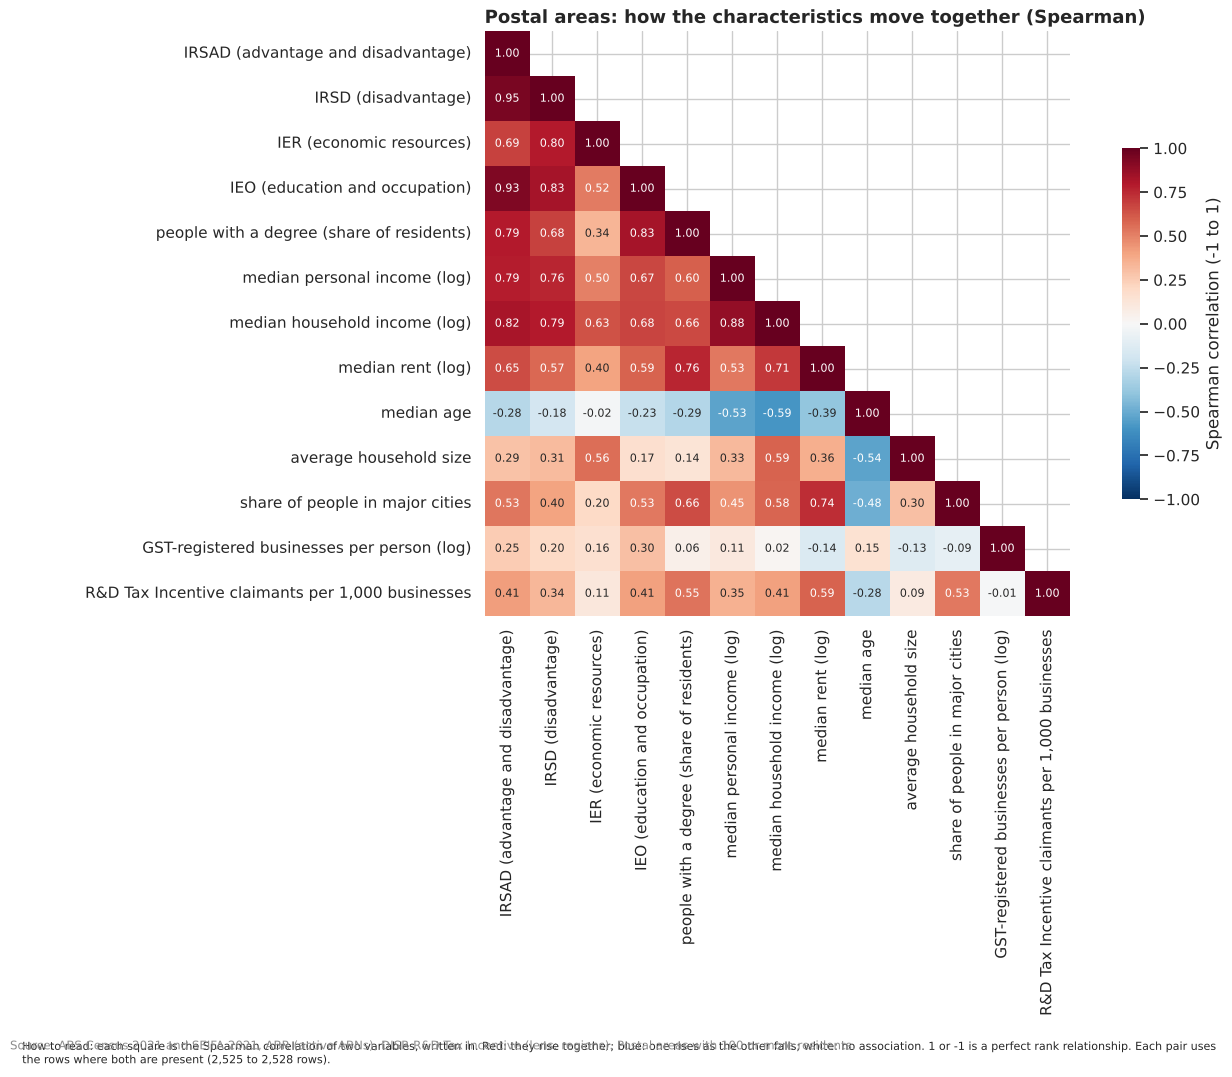

In [29]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

cols = list(CHARACTERISTICS)
fig = multi.corr_heatmap(
    areas, cols, names=CHARACTERISTICS, title="Postal areas: how the characteristics move together (Spearman)"
)
style.source(
    fig,
    "ABS Census 2021 and SEIFA 2021, ABR (active ABNs), DISR R&D Tax Incentive (lens: regions). "
    "Postal areas with 100 or more residents.",
)
complete = areas.dropna(subset=cols).copy()
display(multi.vif(complete, cols).rename(index=CHARACTERISTICS).round(1).to_frame())
explained, loadings = multi.pca(complete, cols)
# each area's scores on the first four components, standardised; a component's sign is arbitrary, so each is turned
# to rise with the variable that loads on it most (the loadings shown are turned the same way)
scores = PCA().fit_transform(StandardScaler().fit_transform(complete[cols]))[:, :4]
scores = (scores - scores.mean(axis=0)) / scores.std(axis=0)
for i in range(4):
    top = loadings.iloc[:, i].abs().idxmax()
    if loadings.iloc[:, i][top] < 0:
        scores[:, i] *= -1
        loadings.iloc[:, i] *= -1
    complete[f"pc{i + 1}"] = scores[:, i]
display(explained.head(6).round(1))
loadings.rename(index=CHARACTERISTICS).iloc[:, :4].round(2)

Largest loadings of each component:
  PC1: IRSAD (advantage and disadvantage) +0.38; median household income (log) +0.36; IEO (education and occupation) +0.35; IRSD (disadvantage) +0.33
  PC2: median age +0.52; average household size -0.47; GST-registered businesses per person (log) +0.46; IRSD (disadvantage) +0.26
  PC3: IER (economic resources) +0.53; R&D Tax Incentive claimants per 1,000 businesses -0.46; average household size +0.41; people with a degree (share of residents) -0.36
  PC4: median rent (log) +0.52; GST-registered businesses per person (log) -0.51; median age +0.46; median personal income (log) -0.32


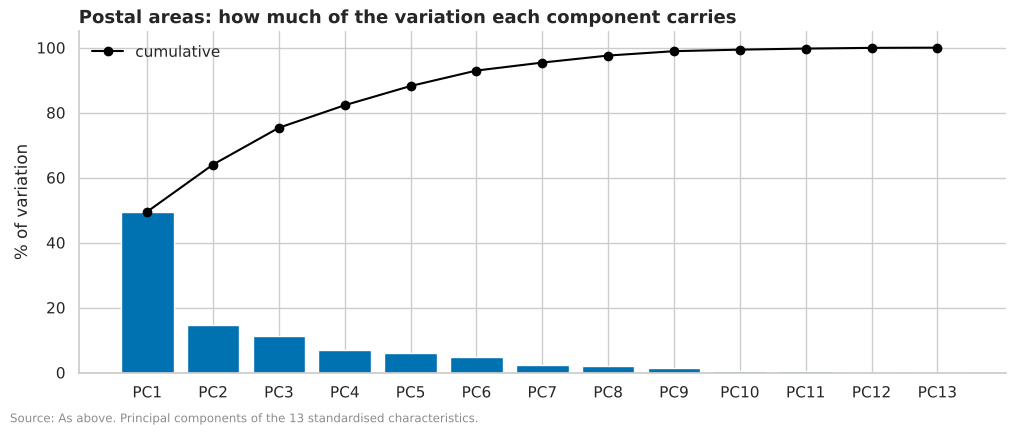

In [30]:
fig = multi.scree(explained, title="Postal areas: how much of the variation each component carries")
style.source(fig, "As above. Principal components of the 13 standardised characteristics.")
areas = areas.merge(complete[["poa_code", "pc1", "pc2", "pc3", "pc4"]], on="poa_code", how="left")
print("Largest loadings of each component:")
for i in range(4):
    top = loadings.iloc[:, i].sort_values(key=abs, ascending=False).head(4)
    print(f"  PC{i + 1}:", "; ".join(f"{CHARACTERISTICS[k]} {v:+.2f}" for k, v in top.items()))

#### Observations

**M13 (descriptive). Places' characteristics repeat each other: one component, advantage, carries half of the
variation across postal areas, and the advantage measures can largely be predicted from one another.** 2,525 areas
with every characteristic:
- **Variance inflation:** IRSAD 86.0, IRSD 32.1, IEO 25.0, median household income 19.6, IER 13.0, the share with a
  degree 11.4: all above 10, so each is largely predictable from the others. Businesses per person (1.6) and R&D
  claimants per 1,000 businesses (1.3) are not.
- **Components:** the first carries 49.5% of the variation, the first four 82.3% (14.5%, 11.3% and 6.9% for the
  second to fourth). The first loads on every advantage measure together (IRSAD +0.38, household income +0.36, IEO
  +0.35, IRSD +0.33, the degree share +0.33): it is the **advantage gradient**. The second rises with median age
  (+0.52) and businesses per person (+0.46) and falls with household size (-0.47): older areas of small households
  and many businesses. The third rises with economic resources (IER +0.53) and household size (+0.41) and falls with
  R&D claimants per 1,000 businesses (-0.46) and the degree share (-0.36): its low end is areas with more degrees and
  R&D claimants than their resources alone would suggest. The fourth rises with rent (+0.52) and age (+0.46) and
  falls with businesses per person (-0.51).
- **So** B27's and B28's single indicators (income, education, advantage) are mostly one measure. Read one at a time,
  each stands for the whole gradient; none should be read as the one that matters.

### 3.2 Filing against the components, with remoteness: which dimensions of a place go with filing

**Revisits:** B29, B28, B31. **Informs:** Q2, Q4. Areas' counts over ten years (FY2017 to FY2026) as negative
binomial models with the area's residents as the exposure, as in B29: first against the first component alone (the
advantage gradient, the reading B29 gave with IRSAD), then against all four components and remoteness together. The
result is a rate ratio per standard deviation of each component: how many times higher an area's filing rate is one
standard deviation up, with the others held. The components are uncorrelated with each other by construction, so
holding them together mostly shows what each adds beyond the advantage gradient. In each half of the areas.

In [31]:
REMOTE = "C(remoteness, Treatment('Major Cities of Australia'))"
fit_areas = areas.dropna(subset=["pc1", "remoteness"]).assign(exposure=lambda d: d.persons * 10)
rows = []
for count in ("patents_standard", "trade_marks", "designs", "patents_provisional"):
    for half, d in fit_areas.groupby("half"):
        for model, rhs in (
            ("first component alone", "pc1"),
            ("four components and remoteness", f"pc1 + pc2 + pc3 + pc4 + {REMOTE}"),
        ):
            r = multi.nb_rate_ratios(d, f"{count} ~ {rhs}", "exposure")
            rows.append(r.assign(measure=count, half=half, model=model))
comp = pd.concat(rows).rename_axis("term").reset_index()
comp["term"] = comp.term.str.replace(r"C\(remoteness, Treatment\('Major Cities of Australia'\)\)\[T\.", "", regex=True)
comp["term"] = comp.term.str.rstrip("]")
print("All fits converged:", bool(comp.converged.all()))
comp.set_index(["measure", "model", "term", "half"])[["rate ratio", "low", "high", "alpha", "rows"]].round(3).unstack(
    "half"
)

All fits converged: True


rate ratio                    low                   high                  alpha  \
half                                                                        first half second half first half second half first half second half first half   
measure             model                          term                                                                                                       
designs             first component alone          pc1                           1.863       2.054      1.695       1.857      2.047       2.272      1.912   
                    four components and remoteness Inner Regional Australia      0.425       0.388      0.309       0.281      0.584       0.537      1.299   
                                                   Outer Regional Australia      0.279       0.199      0.188       0.131      0.416       0.304      1.299   
                                                   Remote Australia              0.171       0.251      0.084       0.138      0.348       0.454      1.299   
                                                   Very Remote Australia         0.025       0.073      0.007        0.03      0.092       0.178      1.299   
                                                   pc1                           1.186       1.205      1.025       1.048      1.372       1.386      1.299   
                                                   pc2                           1.213       1.353      1.069       1.189      1.377        1.54      1.299   
                                                   pc3                           0.761       0.807      0.685        0.72      0.846       0.905      1.299   
                                                   pc4                           0.598       0.648      0.534       0.577       0.67       0.729      1.299   
patents_provisional first component alone          pc1                           1.652        1.96      1.548        1.83      1.764       2.099      1.066   
                    four components and remoteness Inner Regional Australia      0.662       0.709      0.537       0.568      0.818       0.886      0.642   
                                                   Outer Regional Australia      0.628       0.423      0.485       0.319      0.812       0.561      0.642   
                                                   Remote Australia              0.503        0.36      0.329       0.235      0.769        0.55      0.642   
                                                   Very Remote Australia         0.307       0.176      0.182       0.102      0.518       0.304      0.642   
                                                   pc1                           1.247       1.313      1.133       1.188      1.373       1.451      0.642   
                                                   pc2                           1.455       1.311      1.344       1.201      1.575       1.431      0.642   
                                                   pc3                           0.739       0.819      0.691       0.762       0.79       0.879      0.642   
                                                   pc4                           0.801       0.735      0.743       0.678      0.863       0.797      0.642   
patents_standard    first component alone          pc1                           1.932       2.135      1.788       1.958      2.088       2.327      1.253   
                    four components and remoteness Inner Regional Australia      0.518       0.738      0.404       0.562      0.664       0.969      0.713   
                                                   Outer Regional Australia      0.482       0.505      0.355        0.36      0.655       0.707      0.713   
                                                   Remote Australia              0.411       0.384      0.241       0.222      0.703       0.665      0.713   
                                                   Very Remote Australia         0.218       0.115   

#### Observations

**M14 (observational). With the four components and remoteness held together, the advantage gradient is still there
but weaker, and two other dimensions go with filing: business density, and degrees and R&D claimants beyond what an
area's resources would suggest.** Negative binomial rate ratios per standard deviation of each component, first half
then second (raw: the first component alone; held: with the other three and remoteness):
- **Standard patents, advantage (the first component):** 1.932 (1.788 to 2.088) and 1.256 (1.122 to 1.405) held;
  2.135 (1.958 to 2.327) and 1.341 (1.190 to 1.511). On a log scale 35% and 39% of the raw ratio remains:
  **weakened**. Trade marks 1.830 and 1.362 (1.273 to 1.457), 51% remaining (**holds**, just); 1.988 and 1.386, 48%
  (weakened). Designs 1.863 and 1.186 (1.025 to 1.372); 2.054 and 1.205 (27% and 26%); provisionals 1.652 and 1.247;
  1.960 and 1.313 (44% and 40%): **weakened**.
- **The other dimensions, held together** (standard patents): the second component (older areas, small households,
  many businesses) 1.446 (1.312 to 1.593) and 1.219 (1.092 to 1.361); the third 0.731 (0.674 to 0.792) and 0.663
  (0.606 to 0.725), so areas with more degrees and R&D claimants than their resources would suggest file more; the
  fourth (high rent, few businesses per person) 0.702 (0.642 to 0.768) and 0.666 (0.603 to 0.736). The same signs
  hold for trade marks, designs and provisionals in both halves.
- **Remoteness stays**, with the components held: inner regional areas file standard patents at 0.518 (0.404 to
  0.664) and 0.738 (0.562 to 0.969) of major cities' rate, very remote areas at 0.218 and 0.115.
- **The extra spread falls** (alpha 1.253 and 1.582 with advantage alone, 0.713 and 0.935 with every factor; trade
  marks 0.737 and 0.813, then 0.419 and 0.408): the dimensions together account for a good part of how far areas
  differ beyond chance (U53).
- **Revisits B29:** its IRSAD ratio (1.717 and 1.857) is mostly the whole advantage gradient, and part of it is where
  businesses, degree holders and R&D claimants are, and remoteness. Between areas, not people or firms (ecological).

### 3.3 Is the gradient one filer's? B30 with the filer's party

**Revisits:** B30 (the final review's "party-aligned filer"). **Informs:** Q2. B30 took each area's largest filer by
the first founding applicant with an ABN, which for a jointly founded patent need not be the party whose postcode
places the patent. Here the largest filer is the **filer's party** itself (1.0), the same party that gives the patent
its postcode, so a filer is counted whether or not it has an ABN. Australian standard patents filed FY2017 to FY2026,
placed by the filer's postcode; the IRSAD rate ratio as in B29, with and without each area's largest filer, in each
half.

In [32]:
by_party = rsql("""
    WITH @FILER_PARTY,
    f AS (
        SELECT r.founder_postcode AS poa_code, p.filer_party, count(*) AS n
        FROM {lens/rights} r JOIN filer_party p USING (ip_right_type, application_number)
        WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 2017 AND 2026 AND r.founding_australian
          AND r.founder_postcode IS NOT NULL
        GROUP BY ALL
    )
    SELECT poa_code, sum(n) AS total, max(n) AS largest, count(*) AS filers FROM f GROUP BY 1
""")
a3 = areas.merge(by_party, on="poa_code", how="left").fillna({"total": 0, "largest": 0, "filers": 0})
a3["without_largest"] = (a3.total - a3.largest).astype(int)
a3["total"] = a3.total.astype(int)
a3["z_irsad"] = (a3.irsad_score - a3.irsad_score.mean()) / a3.irsad_score.std()
a3["exposure"] = a3.persons * 10
print(
    f"Areas: {len(a3):,}; their patents: {a3.total.sum():,}; held by each area's largest filer (by party):",
    f"{100 * a3.largest.sum() / a3.total.sum():.1f}%; filers: {int(a3.filers.sum()):,}",
)
rows = []
for half, d in a3.groupby("half"):
    for count in ("total", "without_largest"):
        rows.append(multi.nb_rate_ratios(d, f"{count} ~ z_irsad", "exposure").assign(measure=count, half=half))
pd.concat(rows).set_index(["measure", "half"])[["rate ratio", "low", "high", "alpha", "rows", "converged"]].round(3)

Areas: 2,528; their patents: 24,879; held by each area's largest filer (by party): 31.4%; filers: 12,793


,,rate ratio,low,high,alpha,rows,converged
measure,half,,,,,,
total,first half,1.717,1.597,1.845,1.354,1317,True
without_largest,first half,1.933,1.771,2.11,1.994,1317,True
total,second half,1.857,1.717,2.008,1.65,1211,True
without_largest,second half,2.031,1.856,2.223,1.912,1211,True


#### Observations

**M15 (observational). The advantage gradient is not one filer's, with each area's largest filer taken by the
filer's party: without it the gradient is steeper.** 24,879 Australian standard patents placed in 2,528 areas, from
12,793 filers; each area's largest filer holds 31.4% of them (B30, by the first founding ABN: 29.2%). IRSAD rate
ratios per standard deviation, first half then second: with every filer 1.717 (1.597 to 1.845) and 1.857 (1.717 to
2.008), as in B29; without each area's largest 1.933 (1.771 to 2.110) and 2.031 (1.856 to 2.223). **Holds**, and B30's
reading stands with the party-aligned filer. Nor do the largest filers account for how far areas differ: the spread
beyond chance is larger without them (alpha 1.994 and 1.912, against 1.354 and 1.650 with them).

### 3.4 Kinds of places: are there distinct groups?

**Informs:** Q2, Q4. k-means groups the areas by their scores on the four components, for two to eight groups, each
scored by its **silhouette** (from -1 to 1: how much closer each area is to its own group than to the next). Under
ADR 0046 the groups are read as kinds of place only with a silhouette of 0.25 or more; below that, the areas form a
continuum and any grouping is a convenience, not a finding.

In [33]:
pcs = ["pc1", "pc2", "pc3", "pc4"]
kinds = multi.clusters(complete, pcs, ks=range(2, 9))
kinds["reading"] = kinds.silhouette.map(multi.silhouette_word)
display(kinds.round(4))
best = int(kinds.silhouette.idxmax())
labels, profile = multi.assign(complete, pcs, best)
groups = (
    complete.assign(group=labels)
    .groupby("group")
    .agg(
        areas=("poa_code", "size"),
        residents=("persons", "sum"),
        patents=("patents_standard", "sum"),
        trade_marks=("trade_marks", "sum"),
        irsad=("irsad_score", "median"),
        city_share=("share_major_cities", "mean"),
    )
)
groups["patents a year per 10,000 people"] = 1000 * groups.patents / groups.residents
groups["trade marks a year per 10,000 people"] = 1000 * groups.trade_marks / groups.residents
print(f"Best silhouette at k = {best}: {kinds.silhouette.max():.3f} ({multi.silhouette_word(kinds.silhouette.max())})")
profile.round(2).join(groups.round(2))

,silhouette,inertia,reading
k,,,
2,0.2343,"8,123",no clear segments
3,0.2442,"6,720",no clear segments
4,0.2499,"5,527",no clear segments
5,0.2694,"4,563",some structure
6,0.2533,"4,148",some structure
7,0.2316,"3,798",no clear segments
8,0.2336,"3,474",no clear segments


Best silhouette at k = 5: 0.269 (some structure)


,n,pc1,pc2,pc3,pc4,areas,residents,patents,trade_marks,irsad,city_share,"patents a year per 10,000 people","trade marks a year per 10,000 people"
cluster,,,,,,,,,,,,,
0,539,-0.3,0.49,0.67,-1.12,539,1064067,437,9317,973,0.01,0.41,8.76
1,288,1.36,0.3,-1.66,-0.49,288,4451909,13993,223165,"1,088",0.95,3.14,50.13
2,725,-0.8,0.59,-0.13,0.66,725,3579135,1327,33942,932,0.07,0.37,9.48
3,713,0.78,-0.51,0.56,0.46,713,11871712,6998,158745,"1,029",0.72,0.59,13.37
4,260,-0.8,-1.61,-0.72,-0.22,260,4389449,2124,46647,897,0.49,0.48,10.63


#### Observations

**M16 (descriptive). Postal areas form at most a weak structure: the best grouping, five kinds, has a silhouette of
0.269, and one group of 288 city areas holds more than half of the patents placed.** Silhouettes for two to eight
groups run from 0.232 to 0.269 (corrected 3 November 2026 in the review: this gave 0.231; the lowest is 0.2316); the best, five groups at 0.269, is "some structure" under ADR 0046, short of clear
segments (0.5 or more). Read as a description, not kinds of place:
- **288 areas** (4,451,909 residents; 95% of their people in major cities; median IRSAD 1,088), high on advantage
  (1.36) and low on the third component (-1.66: more degrees and R&D claimants than their resources), file 3.14
  standard patents a year per 10,000 people and 50.13 trade marks: 13,993 of the 24,879 patents placed (56%).
- **713 areas** (11,871,712 residents, the most), above average on advantage (0.78): 0.59 patents and 13.37 trade
  marks a year per 10,000 people.
- The other three groups (260, 539 and 725 areas) are below average on advantage (-0.80, -0.30 and -0.80), file 0.37
  to 0.48 patents and 8.76 to 10.63 trade marks a year per 10,000 people, and differ on the second and fourth
  components and in how many of their people live in major cities (49%, 1% and 7%).
- **So** the concentration of filing in a minority of advantaged, educated, city areas is the clearest structure in
  the places lens; the rest is a continuum.

### 3.5 Business mix, incomes and change, beyond the components

**Revisits:** B31, B58, B59 (carried in the places row of notebook 2's section 8; the first pass named B31 in 3.2 but
did not model the business mix, and did not take up B58 or B59; added 3 November 2026). **Informs:** Q2, Q4. Partial
rank correlations, as in sections 4, 6 and 7 (the correlation of two variables' ranks once what the held factors
explain is removed from both), with 95% intervals from 1,000 resamples of areas, in each half:

- **business mix (B31):** each division's share of an area's businesses (CABEE, June 2025; areas with 100 or more
  businesses) against organisations' standard patents and trade marks per 1,000 businesses, with the four components
  and remoteness held (remoteness as a rank, major cities 1 to very remote 5);
- **incomes (B58):** taxable income per individual and the share of individuals with business income (the ATO,
  2023-24) against standard patents and trade marks per 10,000 people, with the same held;
- **change (B59):** the change from 2011 to 2021 in an area's share of graduates and in its median income against the
  change in its filing (B59's measures), with the area's 2011 levels held (its graduates' share, its income and its
  filing then), since an area that starts high has less room to rise.

In [34]:
REMOTE_ORDER = {
    "Major Cities of Australia": 1, "Inner Regional Australia": 2, "Outer Regional Australia": 3,
    "Remote Australia": 4, "Very Remote Australia": 5,
}  # fmt: skip
PLACE_HELD = ["pc1", "pc2", "pc3", "pc4", "remoteness_rank"]
mix = sql("""
    SELECT poa_code, split_part(indicator, '|', 2) AS division, sum(value) AS businesses
    FROM {lens/region_indicators}
    WHERE source = 'cabee' AND period = 'June 2025' AND indicator LIKE 'employment|%|Total'
      AND split_part(indicator, '|', 2) <> 'X'
    GROUP BY ALL
""").pivot(index="poa_code", columns="division", values="businesses")
mix = mix[mix.sum(axis=1) >= 100]
mix = mix.div(mix.sum(axis=1), axis=0)
MIX = {
    "K": "financial and insurance services", "M": "professional, scientific and technical services",
    "L": "rental, hiring and real estate", "J": "information media and telecommunications", "C": "manufacturing",
    "E": "construction", "I": "transport, postal and warehousing", "A": "agriculture, forestry and fishing",
}  # fmt: skip
ato = sql("""
    SELECT poa_code,
           max(value) FILTER (indicator = 'Taxable income or loss|$')
             / max(value) FILTER (indicator = 'Individuals|no.') AS taxable_per_individual,
           max(value) FILTER (indicator = 'Total business income|no.')
             / max(value) FILTER (indicator = 'Individuals|no.') AS business_share
    FROM {lens/region_indicators} WHERE source = 'ato_postcode' AND period = '2023-24' GROUP BY 1
""").set_index("poa_code")
place_rates = sql("""
    SELECT poa_code, patents_standard_per_1k_businesses, trade_marks_per_1k_businesses,
           patents_standard_per_10k_people, trade_marks_per_10k_people FROM {lens/regions}
""").set_index("poa_code")
pl = (
    areas.dropna(subset=["pc1"])
    .set_index("poa_code")
    .assign(remoteness_rank=lambda d: d.remoteness.map(REMOTE_ORDER))
    .join(mix.rename(columns=lambda c: f"mix_{c}"))
    .join(ato)
    .join(place_rates)
)
rows = []
for half, d in pl.groupby("half"):
    for code, name in MIX.items():
        for rate, rname in (
            ("patents_standard_per_1k_businesses", "standard patents"),
            ("trade_marks_per_1k_businesses", "trade marks"),
        ):
            r = multi.partial_corr_interval(d, f"mix_{code}", rate, PLACE_HELD, reps=1000)
            rows.append(r.rename(f"{name} (share of businesses) ~ {rname} per 1,000 businesses, {half}"))
    for x, xname in (
        ("taxable_per_individual", "taxable income per individual"),
        ("business_share", "share with business income"),
    ):
        for rate, rname in (
            ("patents_standard_per_10k_people", "standard patents"),
            ("trade_marks_per_10k_people", "trade marks"),
        ):
            r = multi.partial_corr_interval(d, x, rate, PLACE_HELD, reps=1000)
            rows.append(r.rename(f"{xname} ~ {rname} per 10,000 people, {half}"))
mix_fx = pd.DataFrame(rows)[["n", "raw", "raw low", "raw high", "partial", "partial low", "partial high"]]
mix_fx.astype(float).round(3)

,n,raw,raw low,raw high,partial,partial low,partial high
"financial and insurance services (share of businesses) ~ standard patents per 1,000 businesses, first half",321,0.444,0.351,0.531,0.161,0.049,0.273
"financial and insurance services (share of businesses) ~ trade marks per 1,000 businesses, first half",976,0.66,0.619,0.699,0.227,0.161,0.294
"professional, scientific and technical services (share of businesses) ~ standard patents per 1,000 businesses, first half",321,0.386,0.282,0.483,0.102,-0.011,0.215
"professional, scientific and technical services (share of businesses) ~ trade marks per 1,000 businesses, first half",976,0.654,0.611,0.692,0.191,0.118,0.264
"rental, hiring and real estate (share of businesses) ~ standard patents per 1,000 businesses, first half",321,0.437,0.331,0.522,0.119,-0.007,0.234
"rental, hiring and real estate (share of businesses) ~ trade marks per 1,000 businesses, first half",976,0.483,0.43,0.535,0.212,0.148,0.277
"information media and telecommunications (share of businesses) ~ standard patents per 1,000 businesses, first half",321,0.328,0.226,0.423,0.003,-0.111,0.129
"information media and telecommunications (share of businesses) ~ trade marks per 1,000 businesses, first half",976,0.556,0.509,0.598,0.094,0.027,0.161
"manufacturing (share of businesses) ~ standard patents per 1,000 businesses, first half",321,0.111,-0.003,0.222,0.449,0.357,0.53
"manufacturing (share of businesses) ~ trade marks per 1,000 businesses, first half",976,0.09,0.023,0.162,0.349,0.286,0.407


In [35]:
# B59 again: the change from the 2011 to the 2021 Census against the change in filing, with the 2011 levels held
tsp = sql("""
    SELECT poa_code, period,
           sum(value) FILTER (indicator = 'T01.Tot_persons_P') AS persons,
           sum(value) FILTER (indicator IN ('T29.H_n_s_q_BD_P', 'T29.H_n_s_q_Gr_D_G_Ce_P', 'T29.H_no_sc_qu_Po_De_P'))
             / nullif(sum(value) FILTER (indicator = 'T29.Per_age_15over_P'), 0) AS degree,
           any_value(value) FILTER (indicator = 'T02.Med_person_inc_we') AS income
    FROM {lens/region_indicators}
    WHERE source = 'census_tsp' AND period IN ('2011', '2021') GROUP BY 1, 2
""").pivot(index="poa_code", columns="period")
then_now = sql("""
    SELECT founder_postcode AS poa_code,
           count(*) FILTER (patent_type = 'standard' AND filing_fy BETWEEN 2007 AND 2011) AS pat_then,
           count(*) FILTER (patent_type = 'standard' AND filing_fy BETWEEN 2017 AND 2021) AS pat_now,
           count(*) FILTER (ip_right_type = 'trade_mark' AND filing_fy BETWEEN 2007 AND 2011) AS tm_then,
           count(*) FILTER (ip_right_type = 'trade_mark' AND filing_fy BETWEEN 2017 AND 2021) AS tm_now
    FROM {lens/rights} WHERE founder_postcode IS NOT NULL GROUP BY 1
""").set_index("poa_code")
ok = (tsp[("persons", "2011")] >= 1000) & (tsp[("persons", "2021")] >= 1000)
chg = pd.DataFrame(index=tsp.index[ok])
p11, p21 = tsp[("persons", "2011")][ok], tsp[("persons", "2021")][ok]
f = then_now.reindex(chg.index).fillna(0)
chg["degree_change"] = 100 * (tsp[("degree", "2021")] - tsp[("degree", "2011")])[ok]
chg["income_change"] = np.log(tsp[("income", "2021")] / tsp[("income", "2011")])[ok]
chg["degree_2011"] = 100 * tsp[("degree", "2011")][ok]
chg["log_income_2011"] = np.log(tsp[("income", "2011")][ok].astype(float))
chg["patents_then"] = np.log((f.pat_then + 1) / p11 * 1e4)
chg["trade_marks_then"] = np.log((f.tm_then + 1) / p11 * 1e4)
chg["patents_change"] = np.log((f.pat_now + 1) / p21 * 1e4) - chg.patents_then
chg["trade_marks_change"] = np.log((f.tm_now + 1) / p21 * 1e4) - chg.trade_marks_then
chg["half"] = np.where(bi.split_half(pd.Series(chg.index, index=chg.index)), "first half", "second half")
# a fixed row order, and the parallel sums' last-digit noise rounded away, so that the resamples (a fixed seed) give
# the same intervals on every run
chg = chg.sort_index()
chg[chg.columns.drop("half")] = chg[chg.columns.drop("half")].round(10)
rows = []
for half, d in chg.groupby("half"):
    for x, xname in (("degree_change", "gain in graduates' share"), ("income_change", "gain in median income")):
        for y, then, yname in (
            ("patents_change", "patents_then", "change in standard patents"),
            ("trade_marks_change", "trade_marks_then", "change in trade marks"),
        ):
            r = multi.partial_corr_interval(d, x, y, ["degree_2011", "log_income_2011", then], reps=1000)
            rows.append(r.rename(f"{xname} ~ {yname} (2011 levels held), {half}"))
change_fx = pd.DataFrame(rows)[["n", "raw", "raw low", "raw high", "partial", "partial low", "partial high"]]
change_fx.astype(float).round(3)

,n,raw,raw low,raw high,partial,partial low,partial high
"gain in graduates' share ~ change in standard patents (2011 levels held), first half",921,-0.065,-0.131,0.005,-0.115,-0.18,-0.048
"gain in graduates' share ~ change in trade marks (2011 levels held), first half",921,-0.104,-0.172,-0.034,0.024,-0.036,0.09
"gain in median income ~ change in standard patents (2011 levels held), first half",921,-0.081,-0.143,-0.017,-0.028,-0.091,0.037
"gain in median income ~ change in trade marks (2011 levels held), first half",921,-0.016,-0.078,0.049,0.009,-0.054,0.076
"gain in graduates' share ~ change in standard patents (2011 levels held), second half",868,-0.108,-0.177,-0.046,-0.134,-0.204,-0.062
"gain in graduates' share ~ change in trade marks (2011 levels held), second half",868,-0.137,-0.202,-0.071,0.063,-0.004,0.131
"gain in median income ~ change in standard patents (2011 levels held), second half",868,-0.059,-0.123,0.007,-0.024,-0.088,0.043
"gain in median income ~ change in trade marks (2011 levels held), second half",868,-0.016,-0.083,0.049,0.06,-0.008,0.13


#### Observations

**M31 (observational). Beyond the advantage gradient and remoteness, an area's share of manufacturing businesses goes
with more patents and trade marks per business, where B31 found no link; finance and professional services keep only
a trade mark link; incomes add nothing detectable; and gaining graduates goes with a fall in patents against the 2011
level.** Partial rank correlations (raw; with the four components and remoteness held), first half then second:
- **Manufacturing's share of businesses:** standard patents per 1,000 businesses 0.111 (-0.003 to 0.222) raw and
  0.449 (0.357 to 0.530) held; -0.022 and 0.396 (0.296 to 0.489): **appears once held**. Trade marks 0.090 and 0.349
  (0.286 to 0.407); 0.062 and 0.371 (0.308 to 0.425). **Revisits B31** ("manufacturing's share makes no difference"):
  among areas of the same advantage, density and remoteness, more manufacturing businesses go with more filing per
  business. Still not who files (U75), and a business's address can be a head office (U47).
- **Other divisions:** financial and insurance services, patents 0.444 and 0.161 (0.049 to 0.273), then 0.380 and
  0.017 (-0.099 to 0.130), not replicated; trade marks 0.660 and 0.227 (0.161 to 0.294), 0.696 and 0.162 (0.092 to
  0.227), **weakened**. Professional services, patents 0.386 and 0.102 (-0.011 to 0.215), 0.361 and 0.035: not detected
  once held; trade marks 0.654 and 0.191, 0.714 and 0.157: weakened. Construction, patents -0.375 and -0.019, -0.382
  and 0.036: not detected once held. Transport, patents -0.392 and -0.258 (-0.357 to -0.151), then -0.302 and -0.107
  (-0.212 to 0.002). Agriculture, trade marks -0.622 and -0.119 (-0.186 to -0.054), -0.654 and -0.128: weakened.
- **Incomes (B58):** taxable income per individual against patents per 10,000 people 0.384 and 0.076 (-0.035 to
  0.185), 0.405 and 0.012 (-0.079 to 0.104); against trade marks 0.457 and -0.044, 0.518 and -0.039: **not detected
  once held**. **Revisits B58:** its income link is the advantage gradient. The share with business income goes with
  trade marks a little beyond it (0.087, 0.025 to 0.151; 0.143, 0.077 to 0.210).
- **Change (B59),** with the 2011 levels held: gaining graduates against the change in standard patents -0.115
  (-0.180 to -0.048) and -0.134 (-0.204 to -0.062) in both halves (raw -0.065 and -0.108); against trade marks 0.024
  and 0.063, not detected; gaining income, not detected (-0.028 and 0.009; -0.024 and 0.060). Small; an area gaining
  graduates may be gaining residents who do not file. **Revisits B59:** a decade's gain in graduates goes with a
  slight fall in patents, not no association.
- Between areas, not people or firms (ecological).

### 3.6 Every attached indicator beyond the components (B28 again)

**Revisits:** B28 (the first pass reduced 13 characteristics to components but did not take the attachments through
Stage 3; added 3 November 2026). **Informs:** Q2. B28 screened every indicator in `region_indicators` against the
filing rates and found most go with filing along one gradient. Stage 3 asks which go with it **beyond** that gradient:
the same screen (each indicator in the period covering the most areas; counts as rates per 1,000 residents), now with
all seven sources (the ATO's postcode tables and the Census time series, added after Stage 2, included), as partial
rank correlations with the four components and remoteness held, against standard patents and trade marks per 10,000
people. B28's rule for a lead: the false discovery rate controlled over every pair in the first half, then the same
sign, a size of 0.1 or more and a pass under its own correction in the second. The raw screen of the same areas is
counted beside it.

In [36]:
from scipy import stats
from scipy.stats import rankdata

SCREEN_RATES = {"patents_standard_per_10k_people": "standard patents", "trade_marks_per_10k_people": "trade marks"}
BEST = """
    WITH c AS (SELECT source, indicator, period, count(*) AS areas FROM {lens/region_indicators} GROUP BY ALL),
    best AS (SELECT source, indicator, arg_max(period, areas * 1000000 + k) AS period
             FROM (SELECT *, rank() OVER (PARTITION BY source, indicator ORDER BY period) AS k FROM c) GROUP BY ALL)
"""
screen_meta = sql(
    BEST
    + """
    SELECT b.source, b.indicator, b.period, any_value(r.topic) AS topic, any_value(r.label) AS label
    FROM best b JOIN {lens/region_indicators} r USING (source, indicator, period) GROUP BY ALL
"""
)
screen_base = pl[["half", *PLACE_HELD, *SCREEN_RATES]]


def partial_rank(x, y, held):
    # Spearman's correlation of x and y, and the same once the ranks of `held` are taken out of both (least squares)
    c = np.column_stack([np.ones(len(x)), np.apply_along_axis(rankdata, 0, held)])
    xr, yr = rankdata(x), rankdata(y)
    rx = xr - c @ np.linalg.lstsq(c, xr, rcond=None)[0]
    ry = yr - c @ np.linalg.lstsq(c, yr, rcond=None)[0]
    den = np.sqrt((rx @ rx) * (ry @ ry))
    return np.corrcoef(xr, yr)[0, 1], (rx @ ry) / den if den > 0 else np.nan


rows = []
for source in sorted(screen_meta.source.unique()):
    long = sql(
        BEST
        + f"""
        SELECT r.poa_code, r.indicator, CASE WHEN r.additive THEN 1000 * r.value / g.persons ELSE r.value END AS value
        FROM {{lens/region_indicators}} r JOIN best b USING (source, indicator, period)
             JOIN {{lens/regions}} g USING (poa_code)
        WHERE r.source = '{source}' AND g.persons >= 100
    """,
        max_rows=None,
    )
    wide = long.pivot(index="poa_code", columns="indicator", values="value").reindex(screen_base.index)
    for half, b in screen_base.groupby("half"):
        w, held = wide.loc[b.index], b[PLACE_HELD].to_numpy(float)
        for rate in SCREEN_RATES:
            y = b[rate].to_numpy(float)
            for ind in w.columns:
                x = w[ind].to_numpy(float)
                ok = ~np.isnan(x) & ~np.isnan(y)
                if ok.sum() < 30 or np.std(x[ok]) == 0:
                    continue
                raw, part = partial_rank(x[ok], y[ok], held[ok])
                rows.append((source, ind, rate, half, int(ok.sum()), raw, part))
scr = pd.DataFrame(rows, columns=["source", "indicator", "rate", "half", "n", "raw", "partial"])
for col, k in (("raw", 0), ("partial", len(PLACE_HELD))):
    r, dof = scr[col].clip(-0.999999, 0.999999), scr.n - 2 - k
    scr[f"p {col}"] = 2 * stats.t.sf(np.abs(r * np.sqrt(dof / (1 - r**2))), dof)
scr = scr.pivot_table(
    index=["source", "indicator", "rate"], columns="half", values=["raw", "partial", "p raw", "p partial", "n"]
)
scr.columns = [f"{a} ({b})" for a, b in scr.columns]
scr = scr.dropna(subset=["raw (first half)", "raw (second half)"]).reset_index()
for col in ("raw", "partial"):  # B28's rule for a lead
    q1 = bi.fdr(scr[f"p {col} (first half)"])
    fwd = (scr[f"{col} (first half)"].abs() >= 0.1) & (q1 < 0.05)
    q2 = pd.Series(np.nan, index=scr.index)
    q2[fwd] = bi.fdr(scr.loc[fwd, f"p {col} (second half)"])
    scr[f"lead ({col})"] = (
        fwd & (scr[f"{col} (second half)"].abs() >= 0.1) & (q2 < 0.05)
        & (np.sign(scr[f"{col} (first half)"]) == np.sign(scr[f"{col} (second half)"]))
    )  # fmt: skip
scr = scr.merge(screen_meta, on=["source", "indicator"], how="left")
counts = scr.groupby(["source", "rate"]).agg(
    pairs=("indicator", "size"), leads_raw=("lead (raw)", "sum"), leads_beyond_the_components=("lead (partial)", "sum")
)
print(f"Indicators: {len(screen_meta):,};", "by source:", screen_meta.source.value_counts().to_dict())
display(counts.rename(index=SCREEN_RATES, level="rate"))
print("Every pair:", counts.sum().astype(int).to_dict())
for rate, rname in SCREEN_RATES.items():
    d = scr[(scr.rate == rate) & scr["lead (partial)"]]
    cols = ["source", "label", "partial (first half)", "partial (second half)", "raw (first half)", "n (first half)"]
    print(f"\n{rname} per 10,000 people: {len(d):,} leads beyond the components; the strongest each way")
    with pd.option_context("display.max_colwidth", 80):
        display(
            pd.concat([d.nlargest(10, "partial (first half)"), d.nsmallest(6, "partial (first half)")])[cols].round(3)
        )

Indicators: 6,882; by source: {'census': 2993, 'phidu': 2368, 'data_by_region': 774, 'cabee': 260, 'ato_postcode': 243, 'census_tsp': 233, 'cer': 11}


pairs  leads_raw  leads_beyond_the_components
source         rate                                                           
ato_postcode   standard patents    243        208                           15
               trade marks         243        227                           44
cabee          standard patents    258        201                          103
               trade marks         260        222                          133
census         standard patents   2954       1502                          284
               trade marks        2957       2036                          296
census_tsp     standard patents    233        164                           27
               trade marks         233        193                           43
cer            standard patents      7          2                            0
               trade marks           7          0                            4
data_by_region standard patents    768        512                           83
               trade marks         774        648                          116
phidu          standard patents   2368       1666                           46
               trade marks        2368       1958                           87

Every pair: {'pairs': 13673, 'leads_raw': 9539, 'leads_beyond_the_components': 1281}

standard patents per 10,000 people: 558 leads beyond the components; the strongest each way


,source,label,partial (first half),partial (second half),raw (first half),n (first half)
7559,data_by_region,Businesses with turnover of $2m or more (no.),0.414,0.471,0.562,431
7547,data_by_region,Employing businesses with 20 or more employees (no.),0.407,0.435,0.531,431
763,cabee,"Businesses: Manufacturing, Total",0.379,0.423,0.362,431
520,cabee,"Businesses: Manufacturing, Total",0.379,0.425,0.362,431
7525,data_by_region,Number of businesses:Manufacturing industry (no.),0.379,0.415,0.393,431
516,cabee,"Businesses: Manufacturing, 5-19 Employees",0.355,0.441,0.305,431
7549,data_by_region,Employing businesses with 5-19 employees (no.),0.349,0.432,0.51,431
755,cabee,"Businesses: Manufacturing, $200k to less than $2m",0.343,0.386,0.311,431
536,cabee,"Businesses: Construction, 20-199 Employees",0.332,0.342,0.301,431
518,cabee,"Businesses: Manufacturing, Non employing",0.33,0.303,0.373,431



trade marks per 10,000 people: 723 leads beyond the components; the strongest each way


,source,label,partial (first half),partial (second half),raw (first half),n (first half)
7526,data_by_region,Number of businesses:Manufacturing industry (no.),0.327,0.379,0.245,"1,069"
764,cabee,"Businesses: Manufacturing, Total",0.318,0.38,0.192,"1,072"
521,cabee,"Businesses: Manufacturing, Total",0.317,0.38,0.191,"1,072"
7536,data_by_region,"Number of businesses:Professional, scientific and technical services industr...",0.301,0.394,0.723,"1,071"
641,cabee,"Businesses: Professional, Scientific and Technical Services, Total",0.301,0.394,0.724,"1,072"
904,cabee,"Businesses: Professional, Scientific and Technical Services, Total",0.3,0.394,0.724,"1,072"
820,cabee,"Businesses: Retail Trade, Total",0.297,0.369,0.508,"1,072"
569,cabee,"Businesses: Retail Trade, Total",0.297,0.369,0.508,"1,072"
756,cabee,"Businesses: Manufacturing, $200k to less than $2m",0.29,0.348,0.187,"1,072"
896,cabee,"Businesses: Professional, Scientific and Technical Services, $200k to less t...",0.289,0.343,0.707,"1,072"


#### Observations

**M32 (observational). Beyond the components and remoteness, 1,281 of 13,673 pairs of an attached indicator and a
filing rate remain leads, against 9,539 raw: most of the attachments' links with filing are the advantage gradient;
what remains is mostly where businesses, and manufacturing businesses, are.** 6,882 indicators from seven sources,
against standard patents and trade marks per 10,000 people:
- **Leads, raw then beyond the components** (patents; trade marks): the Census 1,502 to 284 and 2,036 to 296; PHIDU
  1,666 to 46 and 1,958 to 87; Data by Region 512 to 83 and 648 to 116; CABEE 201 to 103 and 222 to 133; the ATO 208
  to 15 and 227 to 44; the Census time series 164 to 27 and 193 to 43; the CER 2 to 0 and 0 to 4.
- **Strongest beyond the components, standard patents** (first half; second): businesses with a turnover of $2
  million or more per resident 0.414 and 0.471 (raw 0.562); employing businesses with 20 or more employees 0.407 and
  0.435; manufacturing businesses 0.379 and 0.423 (CABEE). The other way: households with one motor vehicle -0.240 and
  -0.287, lone-person households -0.236 and -0.253.
- **Trade marks:** manufacturing businesses 0.327 and 0.379 (Data by Region); professional, scientific and technical
  businesses 0.301 and 0.394 (raw 0.723); retail businesses 0.297 and 0.369; the other way, people employed full time
  (the Census) -0.230 and -0.237.
- **So** PHIDU's health and social indicators and most of the Census go with filing only as the gradient does (46 and
  87 of 2,368 PHIDU indicators survive); counts of businesses by size and industry carry information beyond it, as M31
  found for the mix. Many indicators are versions of one another, so leads are not independent; between areas.
  **Revisits B28.**

### 3.7 Summary of the places lens

| Stage 2 signal | Stage 3 | What is left once the third factors are held together |
|---|---|---|
| B27, B28: advantage, education and income | M13 | One component (advantage) carries 49.5% of the variation; the single measures repeat each other (variance inflation 11 to 86) |
| B29: advantage and remoteness | M14 | Advantage **weakened** (35% to 39% of the log ratio left for standard patents; trade marks 48% to 51%) with business density, degrees and R&D claimants, and remoteness held; remoteness stays |
| B30: not one firm's | M15 | **Holds** with the filer's party: steeper without each area's largest filer |
| (structure) | M16 | Weak structure (silhouette 0.269); 288 advantaged city areas with many degree holders and R&D claimants hold 56% of placed patents |
| B31: business mix (added in the review) | M31 | Manufacturing's share **appears once held** (0.449 and 0.396 for patents per business); finance and professional services weakened to a trade mark link |
| B58: incomes (added) | M31 | **Not detected once held** (taxable income per individual) |
| B59: change (added) | M31 | Gaining graduates goes with a slight fall in patents against the 2011 level (-0.115 and -0.134) |
| B28: every attached indicator (added) | M32 | 1,281 of 13,673 pairs remain leads (9,539 raw); business counts by size and industry carry most of them |

**Revisits for the atlas:** B29 (its ratio is mostly the whole gradient and partly business density, education and R&D
beyond resources, M14); from the review, B28 (M32), B31, B58 and B59 (M31).

## 4. Lens: Australia and other countries (one row per country, year and indicator)

Stage 2 found that across countries IP follows R&D and income (a development gradient), that Australia's business
R&D fell from 13th to 20th in the OECD while its patenting stayed near what its business R&D predicts (104.9% in 2016
to 2020, inside a wide interval), and that within a decade changes in R&D went with little change in patenting (no
association detected, B33, B34). Here, as in Stage 2, each indicator is a country's mean over a period (2016 to 2020,
then 2006 to 2010), as a ratio to people where it is a count, for the 36 OECD members; 36 countries give wide
intervals, so these are leads at most, and the second period is a **stability check** of the same countries.

In [37]:
NAT = bi.screens()["national"]
nat_names = (
    sql("SELECT indicator, any_value(indicator_name) AS name FROM {lens/national} GROUP BY 1")
    .set_index("indicator")
    .name
)


def national_wide(period):
    # Stage 2's table (notebook 2, 4.0): one row per country of a million people or more, each indicator's mean over
    # the period, as a ratio to people where it is a count
    long = sql(f"""
        WITH v AS (SELECT iso3, indicator, avg(value) AS value FROM {{lens/national}}
                   WHERE entity = 'country' AND {period} AND value IS NOT NULL GROUP BY ALL)
        SELECT v.*, p.value AS people, n.oecd
        FROM v JOIN (SELECT iso3, value FROM v WHERE indicator = 'SP.POP.TOTL') p USING (iso3)
             JOIN (SELECT iso3, bool_or(oecd) AS oecd FROM {{lens/national}} GROUP BY 1) n USING (iso3)
        WHERE p.value >= 1000000
    """)
    how = {k: v for k, v in NAT["indicators"].items() if isinstance(v, str)}
    long = long[long.indicator.isin(how)]
    scale = long.indicator.map(how).map({"per_million_people": 1e6, "per_person": 1.0, "as_is": None})
    long["value"] = np.where(scale.notna(), long.value / long.people * scale.fillna(1), long.value)
    wide = long.pivot(index="iso3", columns="indicator", values="value")
    wide["oecd"] = long.groupby("iso3").oecd.first()
    return wide[wide.oecd.fillna(False).astype(bool)].drop(columns="oecd").sort_index()


oecd = {"2016-2020": national_wide(NAT["discovery"]), "2006-2010": national_wide(NAT["replication"])}
COUNTRY_TRAITS = {
    "NY.GDP.PCAP.PP.KD": "GDP per person, PPP (log)",
    "OECD.MSTI.B": "business R&D, % of GDP (BERD)",
    "IP.JRN.ARTC.SC": "journal articles per million (log)",
    "SE.TER.ENRR": "tertiary enrolment (% gross)",
    "SL.TLF.ADVN.ZS": "labour force with advanced education (%)",
    "NV.IND.MANF.ZS": "manufacturing, % of GDP",
    "NE.EXP.GNFS.ZS": "exports, % of GDP",
    "TX.VAL.TECH.MF.ZS": "high-technology exports, % of manufactured exports",
    "BX.KLT.DINV.WD.GD.ZS": "foreign direct investment inflows, % of GDP",
    "IC.BUS.NDNS.ZS": "new business density",
    "SP.POP.TOTL": "population (log)",
}
LOGGED = {"NY.GDP.PCAP.PP.KD", "IP.JRN.ARTC.SC", "SP.POP.TOTL"}
for w in oecd.values():
    for c in LOGGED | {"IP.PAT.RESD", "WIPO.PAT.APP", "WIPO.TM.CLASS"}:
        w[c] = np.log10(w[c].where(w[c] > 0))
print({p: len(w) for p, w in oecd.items()})

{'2016-2020': 36, '2006-2010': 36}


### 4.1 Australia's profile across indicators, and the members most like it

**Revisits:** B32, B33. **Informs:** Q1, Q4. Eleven indicators of each OECD member that are not IP measures
(income, business R&D, research output, education, the economy's make-up, investment, new businesses and size),
in 2016 to 2020: their correlation map, variance inflation and principal components, Australia's position on each
(as standard deviations from the members' mean), and the members closest to Australia on the first four components. Total R&D (GERD) is left out because business R&D is part of it (their variance
inflation was 116 and 95 together), and researchers per million because the World Bank's series for Australia ends
in 2010 (U63).

,VIF
journal articles per million (log),8.3
"GDP per person, PPP (log)",6.5
"exports, % of GDP",4.1
"business R&D, % of GDP (BERD)",2.8
population (log),2.5
new business density,2.3
"manufacturing, % of GDP",2.3
"high-technology exports, % of manufactured exports",2.1
labour force with advanced education (%),1.5
tertiary enrolment (% gross),1.4


,% explained,cumulative %
PC1,24.7,24.7
PC2,20.1,44.9
PC3,17.5,62.4
PC4,11,73.4
PC5,7,80.4


Members with every indicator: 35; closest to Australia on the first four components: NOR (1.21), NZL (1.76), SWE (1.82), DNK (2.44), GBR (2.46)
Australia's scores: {'pc1': 1.08, 'pc2': -2.47, 'pc3': 0.65, 'pc4': 0.66}


,PC1,PC2,PC3,PC4
"GDP per person, PPP (log)",0.53,0.04,0.19,-0.07
"business R&D, % of GDP (BERD)",0.3,0.17,0.43,0.21
journal articles per million (log),0.53,-0.09,0.17,-0.17
tertiary enrolment (% gross),0.11,-0.31,0.17,-0.47
labour force with advanced education (%),0.17,-0.39,-0.26,0.24
"manufacturing, % of GDP",0.07,0.56,-0.06,-0.16
"exports, % of GDP",0.29,0.34,-0.4,-0.29
"high-technology exports, % of manufactured exports",0.25,0.26,0.1,0.55
"foreign direct investment inflows, % of GDP",-0.01,0.31,-0.41,0.18
new business density,0.25,-0.34,-0.3,0.4


,Australia (standard deviations from the members' mean)
indicator,
"GDP per person, PPP (log)",0.64
"business R&D, % of GDP (BERD)",-0.35
journal articles per million (log),0.96
tertiary enrolment (% gross),1.78
labour force with advanced education (%),0.32
"manufacturing, % of GDP",-1.57
"exports, % of GDP",-1.06
"high-technology exports, % of manufactured exports",0.64
"foreign direct investment inflows, % of GDP",-0.06


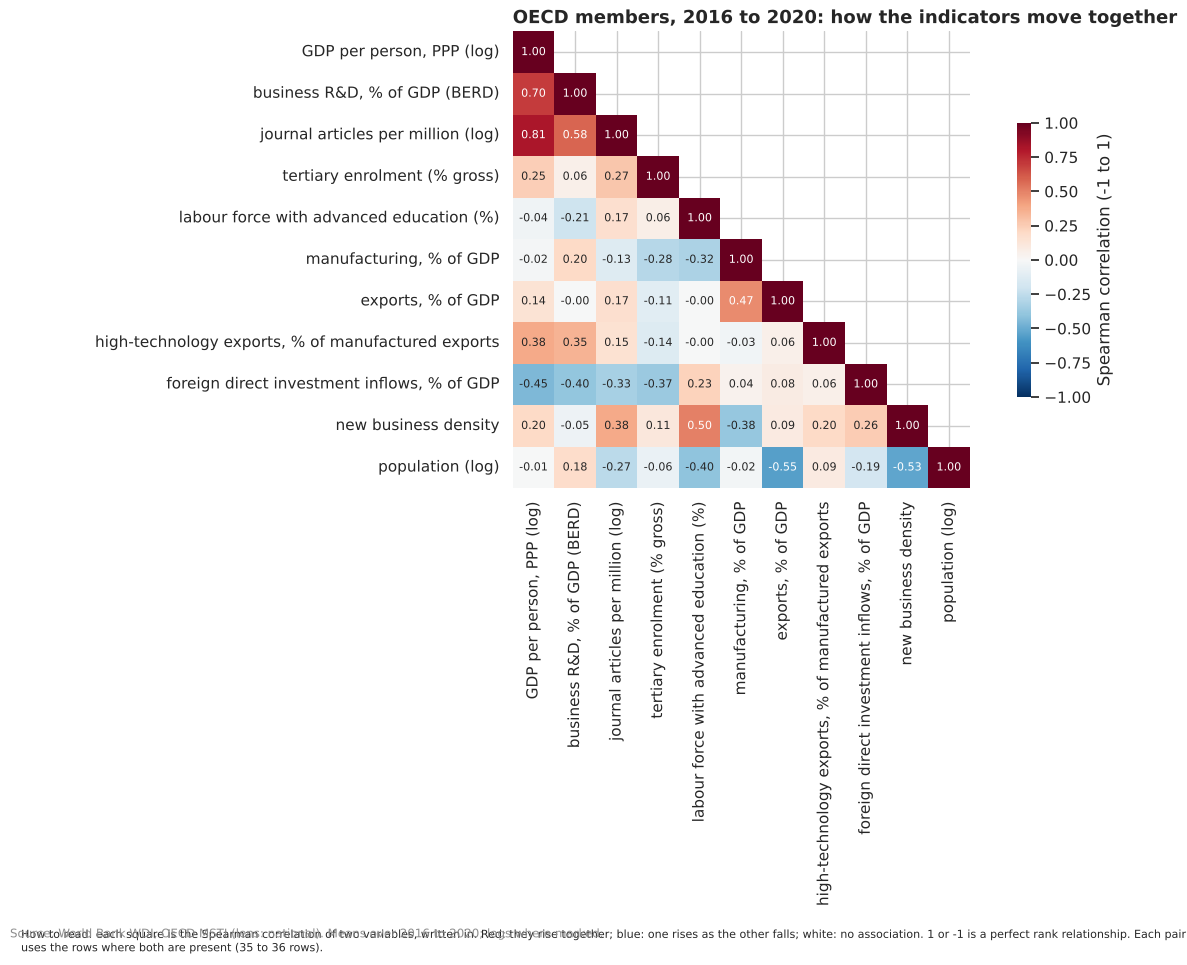

In [38]:
cw = oecd["2016-2020"]
traits = list(COUNTRY_TRAITS)
fig = multi.corr_heatmap(
    cw, traits, names=COUNTRY_TRAITS, title="OECD members, 2016 to 2020: how the indicators move together"
)
style.source(fig, "World Bank WDI, OECD MSTI (lens: national). Means over 2016 to 2020; logs where marked.")
full = cw.dropna(subset=traits)
display(multi.vif(full, traits).rename(index=COUNTRY_TRAITS).round(1).to_frame())
c_explained, c_loadings = multi.pca(full, traits)
display(c_explained.head(5).round(1))
z = (full[traits] - full[traits].mean()) / full[traits].std()
c_scores = PCA().fit_transform(StandardScaler().fit_transform(full[traits]))[:, :4]
for i in range(4):  # turned to rise with the indicator that loads on it most, as in 3.1
    top = c_loadings.iloc[:, i].abs().idxmax()
    if c_loadings.iloc[:, i][top] < 0:
        c_scores[:, i] *= -1
        c_loadings.iloc[:, i] *= -1
c_scores = pd.DataFrame(c_scores, index=full.index, columns=["pc1", "pc2", "pc3", "pc4"])
distance = np.sqrt(((c_scores - c_scores.loc["AUS"]) ** 2).sum(axis=1)).drop("AUS").sort_values()
print(
    f"Members with every indicator: {len(full)}; closest to Australia on the first four components:",
    ", ".join(f"{c} ({d:.2f})" for c, d in distance.head(5).items()),
)
print("Australia's scores:", c_scores.loc["AUS"].round(2).to_dict())
display(c_loadings.rename(index=COUNTRY_TRAITS).iloc[:, :4].round(2))
z.loc["AUS"].rename(index=COUNTRY_TRAITS).round(2).to_frame("Australia (standard deviations from the members' mean)")

#### Observations

**M17 (descriptive). Across OECD members the non-IP indicators spread over several dimensions, not one, and Australia
sits at an edge of the second: little manufacturing and exporting, much tertiary education and many new businesses.
Its nearest members are Norway, New Zealand and Sweden.** 35 members with every indicator, 2016 to 2020:
- **Less repetition than among places:** variance inflation is under 10 for every indicator (journal articles 8.3, GDP
  per person 6.5, the rest 1.4 to 4.1). The first component carries 24.7% of the variation, the first four 73.4%. The
  first is income and research output (GDP per person +0.53, journal articles +0.53, business R&D +0.30); the second
  manufacturing and trade (manufacturing +0.56, exports +0.34, investment inflows +0.31) against education and new
  businesses (advanced education -0.39, new business density -0.34, tertiary enrolment -0.31).
- **Australia's scores:** +1.08 on the first, -2.47 on the second, +0.65 and +0.66 on the third and fourth. On single
  indicators, in standard deviations from the members' mean: manufacturing -1.57, exports -1.06, business R&D -0.35;
  tertiary enrolment +1.78, new business density +1.75, journal articles +0.96, GDP per person +0.64.
- **Closest members** on the first four components: Norway (1.21), New Zealand (1.76), Sweden (1.82), Denmark (2.44)
  and the United Kingdom (2.46). For comparisons of Australia with similar economies (Q4), these are the natural
  first set; they are similar on these eleven indicators, not on the IP system.

### 4.2 Patenting against business R&D, with income and size held together

**Revisits:** B33, B34. **Informs:** Q1, Q4. Residents' patent applications per million people (at home, and worldwide
by residents, all offices) and residents' trade mark classes worldwide, against business R&D as a share of GDP, with
GDP per person and population held: **partial rank correlations**, with intervals from 1,000 resamples of the members,
in both periods (a stability check). Then Australia's patenting against what a model of the members with business
R&D and income together predicts (B34 used business R&D alone), and changes from 2006 to 2010 to 2016 to 2020.

In [39]:
rows = []
for p, w in oecd.items():
    for y, yname in (
        ("IP.PAT.RESD", "patents at home"),
        ("WIPO.PAT.APP", "patents worldwide"),
        ("WIPO.TM.CLASS", "trade mark classes worldwide"),
    ):
        for x, held, xname in (
            ("OECD.MSTI.B", ["NY.GDP.PCAP.PP.KD", "SP.POP.TOTL"], "business R&D, income and size held"),
            ("NY.GDP.PCAP.PP.KD", ["OECD.MSTI.B", "SP.POP.TOTL"], "income, business R&D and size held"),
        ):
            r = multi.partial_corr_interval(w, y, x, held, reps=1000)
            rows.append(r.rename(f"{yname} ~ {xname}, {p}"))
part = pd.DataFrame(rows)[["n", "raw", "raw low", "raw high", "partial", "partial low", "partial high"]]
part.astype(float).round(3)

,n,raw,raw low,raw high,partial,partial low,partial high
"patents at home ~ business R&D, income and size held, 2016-2020",36,0.853,0.713,0.923,0.715,0.45,0.848
"patents at home ~ income, business R&D and size held, 2016-2020",36,0.639,0.316,0.834,0.173,-0.316,0.577
"patents worldwide ~ business R&D, income and size held, 2016-2020",36,0.91,0.808,0.957,0.811,0.601,0.895
"patents worldwide ~ income, business R&D and size held, 2016-2020",36,0.827,0.623,0.929,0.637,0.335,0.82
"trade mark classes worldwide ~ business R&D, income and size held, 2016-2020",36,0.561,0.23,0.789,0.188,-0.296,0.589
"trade mark classes worldwide ~ income, business R&D and size held, 2016-2020",36,0.656,0.397,0.823,0.435,0.009,0.728
"patents at home ~ business R&D, income and size held, 2006-2010",34,0.795,0.587,0.904,0.623,0.266,0.829
"patents at home ~ income, business R&D and size held, 2006-2010",34,0.66,0.376,0.835,0.267,-0.072,0.567
"patents worldwide ~ business R&D, income and size held, 2006-2010",35,0.903,0.798,0.953,0.818,0.559,0.915
"patents worldwide ~ income, business R&D and size held, 2006-2010",35,0.757,0.513,0.894,0.502,0.155,0.722


In [40]:
# Australia against the members: log patents per million on log business R&D and log income together (B34 used
# business R&D alone), with a 95% prediction interval; and changes between the two periods
out = []
for p, w in oecd.items():
    o = w[["IP.PAT.RESD", "OECD.MSTI.B", "NY.GDP.PCAP.PP.KD"]].dropna()
    o = o[o["OECD.MSTI.B"] > 0].assign(log_berd=lambda d: np.log10(d["OECD.MSTI.B"]))
    for name, xs in (
        ("business R&D alone", ["log_berd"]),
        ("business R&D and income", ["log_berd", "NY.GDP.PCAP.PP.KD"]),
    ):
        X = sm.add_constant(o[xs])
        fit = sm.OLS(o["IP.PAT.RESD"], X).fit()
        pred = fit.get_prediction(X.loc[["AUS"]]).summary_frame(alpha=0.05)
        out.append(
            {
                "period": p,
                "model": name,
                "members": len(o),
                "R squared": fit.rsquared,
                "Australia as a share of predicted (%)": 100
                * 10 ** (o.at["AUS", "IP.PAT.RESD"] - pred["mean"].iloc[0]),
                "low (%)": 100 * 10 ** (o.at["AUS", "IP.PAT.RESD"] - pred["obs_ci_upper"].iloc[0]),
                "high (%)": 100 * 10 ** (o.at["AUS", "IP.PAT.RESD"] - pred["obs_ci_lower"].iloc[0]),
            }
        )
display(pd.DataFrame(out).set_index(["period", "model"]).round(3))
a, b = oecd["2006-2010"], oecd["2016-2020"]
both = b.index.intersection(a.index)
ch = pd.DataFrame(
    {
        "patents (log change)": b.loc[both, "IP.PAT.RESD"] - a.loc[both, "IP.PAT.RESD"],
        "business R&D (change, points of GDP)": b.loc[both, "OECD.MSTI.B"] - a.loc[both, "OECD.MSTI.B"],
        "income (log change)": b.loc[both, "NY.GDP.PCAP.PP.KD"] - a.loc[both, "NY.GDP.PCAP.PP.KD"],
    }
).dropna()
multi.partial_corr_interval(
    ch, "patents (log change)", "business R&D (change, points of GDP)", ["income (log change)"], reps=1000
).to_frame("changes, 2006-2010 to 2016-2020").T

members  R squared  Australia as a share of predicted (%)  low (%)  high (%)
period    model                                                                                                
2016-2020 business R&D alone            36      0.649                                  104.9    17.82     617.7
          business R&D and income       36      0.651                                  111.9    18.24     686.4
2006-2010 business R&D alone            34      0.672                                  55.22    9.905     307.8
          business R&D and income       34      0.676                                  53.76     9.44     306.1

,n,raw,partial,controls,raw low,raw high,partial low,partial high,resamples
"changes, 2006-2010 to 2016-2020",34,0.1649,0.1296,income (log change),-0.1719,0.4787,-0.198,0.4415,1000


#### Observations

**M18 (observational). Across OECD members, residents' patenting goes with business R&D at the same income and size,
in both periods; income adds nothing detectable for patents at home once business R&D is held, while trade marks go
with income rather than R&D, and only in the later period. Australia's patenting is near what business R&D and income
together predict, and changes within the decade still show no association.** Partial rank correlations across members
(raw; held together), with 95% intervals from 1,000 resamples, 2016 to 2020 then 2006 to 2010 (a stability check):
- **Patents at home ~ business R&D** (income and population held): 0.853 (0.713 to 0.923) and 0.715 (0.450 to
  0.848); 0.795 and 0.623 (0.266 to 0.829). **Holds.** **~ income** (business R&D and population held): 0.639 and
  0.173 (-0.316 to 0.577); 0.660 and 0.267 (-0.072 to 0.567): **not detected once held**.
- **Patents filed worldwide by residents ~ business R&D:** 0.910 and 0.811 (0.601 to 0.895); 0.903 and 0.818 (0.559 to
  0.915). **~ income:** 0.827 and 0.637 (0.335 to 0.820); 0.757 and 0.502 (0.155 to 0.722). Both **hold**: abroad,
  richer members file more at the same business R&D.
- **Trade mark classes worldwide ~ business R&D:** 0.561 and 0.188 (-0.296 to 0.589); 0.364 and 0.179 (-0.302 to
  0.622), **not detected once held**. **~ income:** 0.656 and 0.435 (0.009 to 0.728), holds; 0.429 and 0.237 (-0.312
  to 0.638), not detected once held: the stability check does not confirm it.
- **Australia against the members:** 104.9% of the patenting that business R&D alone predicts (B34's figure; 95%
  prediction interval 17.82% to 617.7%), 111.9% (18.24% to 686.4%) with income too, in 2016 to 2020; 55.22% and
  53.76% in 2006 to 2010, also inside wide intervals. With 36 members, Australia's position cannot be told from the
  line.
- **Changes from 2006 to 2010 to 2016 to 2020** (34 members): patents (log change) against the change in business R&D,
  0.165 (-0.172 to 0.479) raw and 0.130 (-0.198 to 0.442) with the change in income held: not detected either way,
  as B34 found.
- **So** B33's "IP follows R&D and income" is two signals for patents: business R&D at home and abroad, income abroad;
  and for trade marks, income at most. Ecological, between countries; 36 members, so leads at most.

### 4.3 The cross-country attachments, with income and size held

**Revisits:** B35 (carried in the countries row; added 3 November 2026). **Informs:** Q1, Q4. B35 found that about
half the cross-country attachments (the GII's indicator values, the OECD's R&D statistics, current well-being,
venture capital and the industry and innovation goals) go with residents' patent applications per million people,
"again along development". Here each is read with **GDP per person** and **population** (logs) held: partial rank
correlations across every country of a million people or more, 2016 to 2020 then 2006 to 2010 (the GII, one edition,
in two halves of its economies, as B35), with B35's rule for a lead (the false discovery rate controlled in the first
sample, the same sign and a pass in the second). Counts of patents themselves are left out, as in B35. Then B35's named
check: women's share of researchers against patenting, with business's share of researchers held too (1,000
resamples).

In [41]:
def countries_wide(period):
    # every country of a million people or more (B35's set): residents' patents per million, GDP per person and
    # population, in logs
    w = sql(f"""
        SELECT iso3, indicator, avg(value) AS value FROM {{lens/national}}
        WHERE entity = 'country' AND {period} AND value IS NOT NULL
          AND indicator IN ('IP.PAT.RESD', 'NY.GDP.PCAP.PP.KD', 'SP.POP.TOTL') GROUP BY ALL
    """).pivot(index="iso3", columns="indicator", values="value")
    w = w[w["SP.POP.TOTL"] >= 1e6]
    return pd.DataFrame(
        {
            "patents": np.log10(w["IP.PAT.RESD"] / w["SP.POP.TOTL"] * 1e6).where(w["IP.PAT.RESD"] > 0),
            "income": np.log10(w["NY.GDP.PCAP.PP.KD"]),
            "size": np.log10(w["SP.POP.TOTL"]),
        }
    )


cbase = {"2016-2020": countries_wide(NAT["discovery"]), "2006-2010": countries_wide(NAT["replication"])}
oecd_long = {
    p: sql(
        f"""
        SELECT iso3, dataset, indicator, any_value(label) AS label, avg(value) AS value
        FROM {{lens/national_indicators}}
        WHERE source = 'oecd'
          AND dataset IN ('msti', 'sdg_09_industry_innovation', 'venture_capital', 'wellbeing_current')
          AND {cond} AND value IS NOT NULL AND coalesce(status, '') NOT ILIKE '%projection%'
        GROUP BY ALL
    """,
        max_rows=None,
    )
    for p, cond in (("2016-2020", "year BETWEEN 2016 AND 2020"), ("2006-2010", "year BETWEEN 2006 AND 2010"))
}
gii_long = sql(
    """
    SELECT iso3, indicator, any_value(label) AS label, avg(value) AS value FROM {lens/national_indicators}
    WHERE source = 'gii' AND unit = 'as named (the value WIPO screened)' AND value IS NOT NULL GROUP BY ALL
""",
    max_rows=None,
)
cmeta = pd.concat(
    [
        *(oecd_long[p].groupby("indicator")[["dataset", "label"]].first() for p in oecd_long),
        gii_long.groupby("indicator").label.first().to_frame().assign(dataset="gii"),
    ]
)
cmeta = cmeta[~cmeta.index.duplicated()]


def cpartial(x, y, held):
    c = np.column_stack([np.ones(len(x)), np.apply_along_axis(rankdata, 0, held)])
    xr, yr = rankdata(x), rankdata(y)
    rx = xr - c @ np.linalg.lstsq(c, xr, rcond=None)[0]
    ry = yr - c @ np.linalg.lstsq(c, yr, rcond=None)[0]
    den = np.sqrt((rx @ rx) * (ry @ ry))
    return np.corrcoef(xr, yr)[0, 1], (rx @ ry) / den if den > 0 else np.nan


rows = []


def cscreen(wide, base, sample):
    for ind in wide.columns:
        d = pd.concat([wide[ind].rename("x"), base], axis=1, join="inner").dropna()
        if len(d) >= 15 and d.x.std() > 0:
            raw, part = cpartial(d.x.to_numpy(float), d.patents.to_numpy(float), d[["income", "size"]].to_numpy(float))
            rows.append((ind, sample, len(d), raw, part))


for p in oecd_long:
    cscreen(oecd_long[p].pivot_table(index="iso3", columns="indicator", values="value"), cbase[p], p)
gw = gii_long.pivot_table(index="iso3", columns="indicator", values="value")
ghalf = bi.split_half(pd.Series(gw.index, index=gw.index))  # the GII: one edition, two halves of the economies
for h, name in ((True, "2016-2020"), (False, "2006-2010")):
    cscreen(gw[(ghalf == h).to_numpy()], cbase["2016-2020"], name)
cres = pd.DataFrame(rows, columns=["indicator", "sample", "n", "raw", "partial"])
for col, k in (("raw", 0), ("partial", 2)):
    r, dof = cres[col].clip(-0.999999, 0.999999), cres.n - 2 - k
    cres[f"p {col}"] = 2 * stats.t.sf(np.abs(r * np.sqrt(dof / (1 - r**2))), dof)
cw2 = cres.pivot_table(index="indicator", columns="sample", values=["raw", "partial", "p raw", "p partial", "n"])
cw2.columns = [f"{a} ({b})" for a, b in cw2.columns]
cw2 = cw2.dropna(subset=["raw (2016-2020)"]).join(cmeta)
cw2 = cw2[~cw2.label.fillna("").str.contains("atent")]  # counts of patents themselves, as B35
for col in ("raw", "partial"):
    q1 = bi.fdr(cw2[f"p {col} (2016-2020)"])
    fwd = (cw2[f"{col} (2016-2020)"].abs() >= 0.1) & (q1 < 0.05)
    q2 = pd.Series(np.nan, index=cw2.index)
    q2[fwd] = bi.fdr(cw2.loc[fwd, f"p {col} (2006-2010)"])
    cw2[f"lead ({col})"] = (
        fwd & (cw2[f"{col} (2006-2010)"].abs() >= 0.1) & (q2 < 0.05)
        & (np.sign(cw2[f"{col} (2016-2020)"]) == np.sign(cw2[f"{col} (2006-2010)"]))
    )  # fmt: skip
display(
    cw2.groupby("dataset").agg(
        indicators=("label", "size"),
        leads_raw=("lead (raw)", "sum"),
        leads_with_income_and_size_held=("lead (partial)", "sum"),
    )
)
d = cw2[cw2["lead (partial)"]]
cols = ["dataset", "label", "partial (2016-2020)", "partial (2006-2010)", "raw (2016-2020)", "n (2016-2020)"]
with pd.option_context("display.max_colwidth", 70):
    display(pd.concat([d.nlargest(10, "partial (2016-2020)"), d.nsmallest(6, "partial (2016-2020)")])[cols].round(3))
# B35's named check: women's share of researchers, with business's share of researchers held as well
rows = []
for p in oecd_long:
    w = oecd_long[p].pivot_table(index="iso3", columns="indicator", values="value")
    d = cbase[p].join(w[["OECD.MSTI.T_WRS.PT_RSH._Z._Z", "OECD.MSTI.B_RS.PT_RSH._Z._Z"]], how="inner")
    d.columns = ["patents", "income", "size", "women_share", "business_share"]
    for held, hname in (
        (["income", "size"], "income and size held"),
        (["income", "size", "business_share"], "business's share of researchers held too"),
    ):
        r = multi.partial_corr_interval(d, "women_share", "patents", held, reps=1000)
        rows.append(r.rename(f"women's share of researchers ~ patents, {hname}, {p}"))
pd.DataFrame(rows)[["n", "raw", "raw low", "raw high", "partial", "partial low", "partial high"]].astype(float).round(3)

,indicators,leads_raw,leads_with_income_and_size_held
dataset,,,
gii,76,63,20
msti,140,83,32
sdg_09_industry_innovation,22,6,3
venture_capital,8,6,0
wellbeing_current,231,66,1


,dataset,label,partial (2016-2020),partial (2006-2010),raw (2016-2020),n (2016-2020)
indicator,,,,,,
OECD.SDG_09_INDUSTRY_INNOVATION.G_9.9_5.C090501.9_5_1_GB_XPD_RSDV._T._T._T._T._T.PT_B1GQ.UNSD,sdg_09_industry_innovation,"Goal 9. Build resilient infrastructure, promote inclusive and sust...",0.743,0.62,0.863,36
GII.OUT.6.1.3.value,gii,Utility models by origin/bn PPP$ GDP: value,0.741,0.472,0.649,37
GII.OUT.6.1.5.value,gii,Citable documents H-index: value,0.715,0.334,0.845,52
GII.IN.2.3.1.value,gii,"Researchers, FTE/mn pop.: value",0.701,0.644,0.838,43
GII.IN.5.1.1.value,gii,"Knowledge-intensive employment, %: value",0.694,0.42,0.886,48
OECD.SDG_09_INDUSTRY_INNOVATION.G_9.9_5.C090502.9_5_2_GB_POP_SCIERD._T._T._T._T._T.10P6HB.UNSD,sdg_09_industry_innovation,"Goal 9. Build resilient infrastructure, promote inclusive and sust...",0.689,0.652,0.753,34
OECD.MSTI.G_FB.PT_B1GQ._Z._Z,msti,"GERD financed by the business enterprise sector, Percentage of GDP",0.671,0.598,0.841,43
GII.OUT.7.3.2.value,gii,GitHub commits/mn pop. 15–69: value,0.664,0.487,0.873,50
OECD.MSTI.B_RS.FTE._Z._Z,msti,"Business enterprise sector researchers, Full time equivalent unit",0.658,0.628,0.772,42


,n,raw,raw low,raw high,partial,partial low,partial high
"women's share of researchers ~ patents, income and size held, 2016-2020",37,-0.647,-0.805,-0.409,-0.266,-0.565,0.055
"women's share of researchers ~ patents, business's share of researchers held too, 2016-2020",37,-0.647,-0.805,-0.409,0.13,-0.232,0.416
"women's share of researchers ~ patents, income and size held, 2006-2010",33,-0.65,-0.828,-0.374,-0.27,-0.65,0.128
"women's share of researchers ~ patents, business's share of researchers held too, 2006-2010",33,-0.65,-0.828,-0.374,0.123,-0.296,0.39


#### Observations

**M33 (observational). With income and size held, 56 of 477 cross-country attachments remain leads with residents'
patenting, against 224 raw: research effort and business R&D remain; well-being and venture capital almost entirely
go; and women's share of researchers is not detected once business's share of researchers is held.**
- **Leads, raw then held:** the GII 63 to 20; the OECD's R&D statistics 83 to 32; the industry and innovation goals 6
  to 3; venture capital 6 to 0; current well-being 66 to 1.
- **Strongest held** (2016 to 2020; 2006 to 2010): R&D spending as a share of GDP (the goals' 9.5.1) 0.743 and 0.620
  (raw 0.863); utility models by origin (GII) 0.741 and 0.472; researchers per million (GII) 0.701 and 0.644;
  knowledge-intensive employment 0.694 and 0.420; GERD financed by business, % of GDP, 0.671 and 0.598; business
  researchers 0.658 and 0.628. The other way: difficulty making ends meet -0.621 and -0.455 (the one well-being lead);
  domestic industry diversification -0.535 and -0.387; higher education's share of researchers -0.425 and -0.478, and
  of R&D spending -0.420 and -0.489.
- **B35's named check:** women's share of researchers against patenting -0.647 (-0.805 to -0.409) raw, -0.266 (-0.565
  to 0.055) with income and size held, 0.130 (-0.232 to 0.416) with business's share of researchers held too; in 2006
  to 2010 -0.650, -0.270 and 0.123. **Not detected once held**: the raw link is where research is done, as B35
  suspected, not a finding about women.
- **Revisits B35:** "again along development" is largely right: a quarter of its leads remain once income and size
  are held, and they are measures of research effort. Between countries; about 30 to 52 economies a pair; leads at
  most.

### 4.4 Summary of the national lens

| Stage 2 signal | Stage 3 | What is left once the third factors are held together |
|---|---|---|
| B32: the development gradient | M17 | Several dimensions among members (the first four carry 73.4%); Australia: low manufacturing and exports, high education and new businesses; nearest Norway, New Zealand, Sweden |
| B33: IP follows R&D and income | M18 | Patents at home: business R&D **holds**, income **not detected once held**; patents abroad: both hold; trade marks: income at most |
| B34: Australia against the line; changes | M18 | Near the line (104.9% to 111.9%, wide intervals); changes: not detected either way |
| B35: the cross-country attachments (added in the review) | M33 | 56 of 477 remain leads with income and size held (224 raw): research effort and business R&D; women's share of researchers **not detected once held** |

**Revisits for the atlas:** B33 (patents follow business R&D, not income, at home, M18); from the review, B35 (M33).

## 5. Lens: Australia over time (one row per month)

Stage 2 screened the timeline as quarterly year-on-year changes (log of a quarter's total against the same quarter a
year earlier) in two periods, 1991 to 2008 and 2008 to 2026, and found one lead that held in both (trade mark
registrations with trade mark oppositions, B36); it warned that changes of quarterly totals are serially dependent,
so the interval from quarters resampled as if independent is too narrow. The final review asked for block resampling
or effective sample sizes (A29). Section 5.1 does that for B36's lead and for the pairs Stage 2 planned (B36, B39);
5.2 splits the monthly series into trend, season and the rest, and asks which series move together once trend and
season are removed.

### 5.1 Quarterly changes with block resampling

**Revisits:** B36, B39 (the final review's block resampling). **Informs:** Q1. For each pair: the rank correlation of
the two series' quarterly changes in each period, its 95% interval from 1,000 resamples of single quarters (as Stage 2
treated them) and from 1,000 **moving-block** resamples of runs of 4 and of 8 consecutive quarters, and the
**effective sample size** (how many independent quarters the dependent series are worth for their correlation). A
pair is read as moving together only if the block interval is clear of zero.

In [42]:
timeline = sql("SELECT * FROM {lens/timeline} ORDER BY month")
TL = bi.screens()["timeline"]
tseries = [c for c, k in TL["columns"].items() if k == "number"]
q = timeline.assign(quarter=pd.PeriodIndex(timeline.month, freq="Q")).groupby("quarter")
counts = q[[c for c in tseries if c != "cpi"]].sum(min_count=3).where(q.month.count() == 3)
counts["cpi"] = q.cpi.last()
change = np.log(counts + 1).diff(4).loc[pd.Period("1991Q3") : pd.Period("2026Q2")]  # Stage 2's changes (B36)
periods = {"1991Q3-2008Q2": change.loc[: pd.Period("2008Q2")], "2008Q3-2026Q2": change.loc[pd.Period("2008Q3") :]}
PAIRS = {
    "trade mark registrations ~ trade mark oppositions (B36's lead)": (
        "trade_marks_registered",
        "trade_mark_oppositions",
    ),
    "standard patents: Australian ~ overseas applicants": ("patents_standard_au", "patents_standard_overseas"),
    "trade marks: Australian ~ overseas applicants": ("trade_marks_au", "trade_marks_overseas"),
    "designs: Australian ~ overseas applicants": ("designs_au", "designs_overseas"),
    "provisionals ~ Australians' standard patents": ("patents_provisional", "patents_standard_au"),
    "Australians' trade marks ~ the CPI": ("trade_marks_au", "cpi"),
}
rows = []
for name, (x, y) in PAIRS.items():
    for p, d in periods.items():
        dd = d[[x, y]].replace([np.inf, -np.inf], np.nan).dropna()
        est, lo1, hi1 = multi.block_bootstrap_corr(dd[x], dd[y], block=1, reps=1000)
        _, lo4, hi4 = multi.block_bootstrap_corr(dd[x], dd[y], block=4, reps=1000)
        _, lo8, hi8 = multi.block_bootstrap_corr(dd[x], dd[y], block=8, reps=1000)
        rows.append(
            {
                "pair": name,
                "period": p,
                "quarters": len(dd),
                "effective quarters": multi.effective_n(dd[x], dd[y]),
                "rho": est,
                "single quarters": f"{lo1:.3f} to {hi1:.3f}",
                "blocks of 4": f"{lo4:.3f} to {hi4:.3f}",
                "blocks of 8": f"{lo8:.3f} to {hi8:.3f}",
                "clear of zero (blocks of 8)": lo8 > 0 or hi8 < 0,
            }
        )
blocks = pd.DataFrame(rows).set_index(["pair", "period"])
blocks.round(3)

quarters  effective quarters    rho   single quarters       blocks of 4  \
pair                                                           period                                                                                   
trade mark registrations ~ trade mark oppositions (B36's lead) 1991Q3-2008Q2        68               23.06  0.658    0.465 to 0.803    0.462 to 0.793   
                                                               2008Q3-2026Q2        72               46.21  0.588    0.394 to 0.740    0.362 to 0.784   
standard patents: Australian ~ overseas applicants             1991Q3-2008Q2        68               53.45 -0.055   -0.327 to 0.225   -0.338 to 0.152   
                                                               2008Q3-2026Q2        72               45.37  0.444    0.214 to 0.623    0.217 to 0.667   
trade marks: Australian ~ overseas applicants                  1991Q3-2008Q2        68               22.84  0.287   -0.007 to 0.518   -0.109 to 0.599   
                                                               2008Q3-2026Q2        72               30.11  0.129   -0.109 to 0.365   -0.176 to 0.397   
designs: Australian ~ overseas applicants                      1991Q3-2008Q2        68               51.74   0.05   -0.200 to 0.292   -0.191 to 0.305   
                                                               2008Q3-2026Q2        72               43.45  0.069   -0.181 to 0.304   -0.105 to 0.217   
provisionals ~ Australians' standard patents                   1991Q3-2008Q2        68               52.78 -0.007   -0.215 to 0.216   -0.245 to 0.276   
                                                               2008Q3-2026Q2        72               47.77  0.034   -0.211 to 0.282   -0.304 to 0.305   
Australians' trade marks ~ the CPI                             1991Q3-2008Q2        68               13.98 -0.478  -0.626 to -0.289  -0.628 to -0.186   
                                                               2008Q3-2026Q2        72               35.58 -0.187   -0.428 to 0.084   -0.529 to 0.201   

                                                                                   blocks of 8  clear of zero (blocks of 8)  
pair                                                           period                                                        
trade mark registrations ~ trade mark oppositions (B36's lead) 1991Q3-2008Q2    0.440 to 0.823                         True  
                                                               2008Q3-2026Q2    0.296 to 0.786                         True  
standard patents: Australian ~ overseas applicants             1991Q3-2008Q2   -0.316 to 0.152                        False  
                                                               2008Q3-2026Q2    0.178 to 0.705                         True  
trade marks: Australian ~ overseas applicants                  1991Q3-2008Q2   -0.108 to 0.620                        False  
                                                               2008Q3-2026Q2   -0.186 to 0.348                        False  
designs: Australian ~ overseas applicants                      1991Q3-2008Q2   -0.187 to 0.326                        False  
                                                               2008Q3-2026Q2   -0.063 to 0.188                        False  
provisionals ~ Australians' standard patents                   1991Q3-2008Q2   -0.236 to 0.251                        False  
                                                               2008Q3-2026Q2   -0.318 to 0.224                        False  
Australians' trade marks ~ the CPI                             1991Q3-2008Q2  -0.628 to -0.174                         True  
                                                               2008Q3-2026Q2   -0.525 to 0.195                        False

#### Observations

**M19 (observational). With block resampling, B36's one lead still holds in both periods, and the quarters are worth
far fewer independent observations than they number; of the planned pairs, only Australians' and overseas
applicants' standard patents move together, and only from 2008.** Rank correlations of quarterly year-on-year changes,
with 95% intervals from 1,000 resamples (single quarters; moving blocks of 8 quarters), 1991Q3 to 2008Q2 then 2008Q3
to 2026Q2:
- **Trade mark registrations ~ trade mark oppositions (B36's lead):** 0.658 (single quarters 0.465 to 0.803; blocks of
  8, 0.440 to 0.823), 68 quarters worth 23.06 independent ones; 0.588 (0.394 to 0.740; 0.296 to 0.786), 72 worth
  46.21. **Holds** with blocks, in both periods; its intervals widen, as the review expected.
- **Standard patents, Australian ~ overseas applicants:** -0.055 (blocks -0.316 to 0.152), then 0.444 (0.178 to
  0.705): from 2008 only. **Trade marks:** 0.287 (-0.108 to 0.620), then 0.129 (-0.186 to 0.348); **designs** 0.050 and
  0.069; **provisionals ~ Australians' standard patents** -0.007 and 0.034: not detected either way.
- **Australians' trade marks ~ the CPI:** -0.478 (blocks -0.628 to -0.174) in the first period, from 68 quarters worth
  13.98, and -0.187 (-0.525 to 0.195) in the second: one period only, not a lead.
- **So** Stage 2's quarterly screen was not too generous for its one lead, but the effective sample sizes (13.98 to
  53.45 of 68 to 72 quarters) mean that pairs below its threshold had little power: "no association detected", as B36
  said. Annual series (B39) have fewer points still.

### 5.2 Trend, season and the rest: which series move together once trend and season are removed

**Informs:** Q1. Each monthly filing series from January 1995 to June 2026 (log of the count plus one) is split by STL
(seasonal-trend decomposition by LOESS, robust to outliers) into a slowly changing **trend**, a **seasonal** pattern
that repeats each year, and the **remainder**, what neither explains. The **strength** of the trend and of the season
(0 to 1: how much less variable the series is once each is taken out, against the remainder alone; above about 0.6 is
strong), and the correlation map of the remainders: series whose remainders move together share
shocks that are not their trends or seasons (a rush before a rule change, a recording batch). The strongest pairs get
moving-block intervals (blocks of 12 months).

,trend strength,season strength,months
series,,,
"standard patents, Australian",0.549,0.306,378
"standard patents, overseas",0.889,0.308,378
provisionals,0.896,0.753,378
"trade marks, Australian",0.973,0.799,378
"trade marks, overseas",0.962,0.47,378
"designs, Australian",0.336,0.58,378
"designs, overseas",0.949,0.331,378


,rho,low,high,effective months,months
pair,,,,,
"provisionals ~ trade marks, Australian",0.325,0.24,0.427,270.7,378
"standard patents, overseas ~ trade marks, Australian",0.256,0.148,0.365,215.8,378
"trade marks, Australian ~ trade marks, overseas",0.253,0.15,0.348,144.7,378
"standard patents, Australian ~ standard patents, overseas",0.239,0.122,0.352,353,378


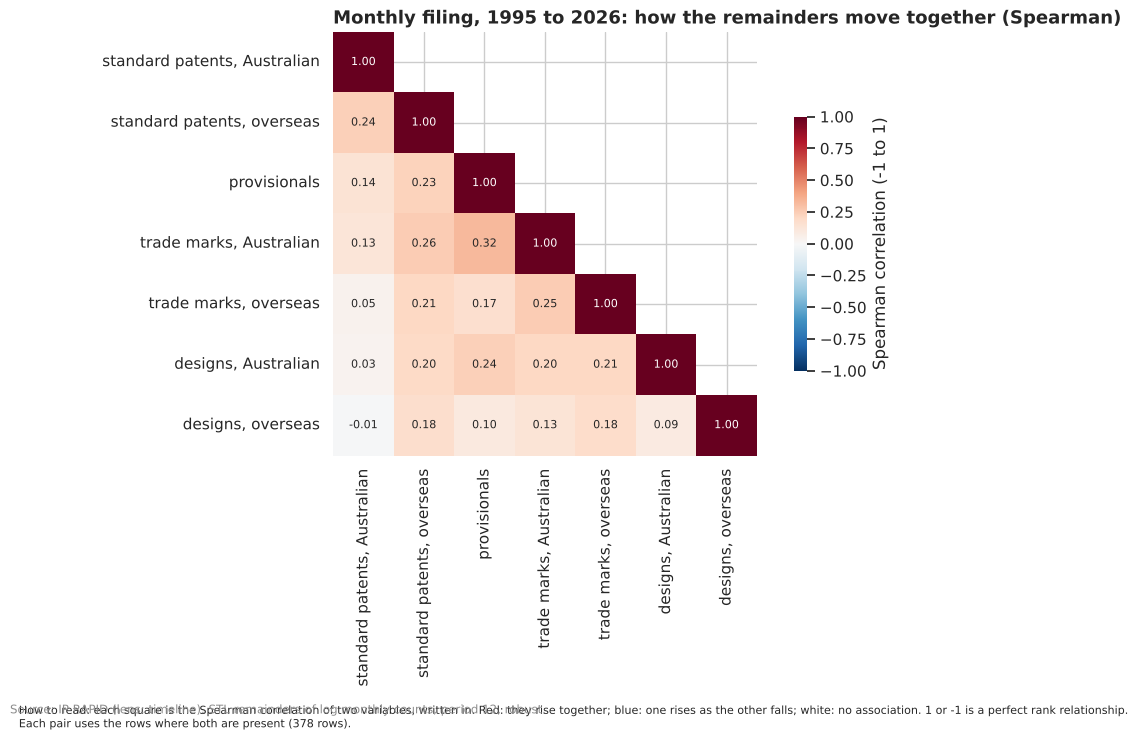

In [43]:
from statsmodels.tsa.seasonal import STL

MONTHLY = {
    "patents_standard_au": "standard patents, Australian",
    "patents_standard_overseas": "standard patents, overseas",
    "patents_provisional": "provisionals",
    "trade_marks_au": "trade marks, Australian",
    "trade_marks_overseas": "trade marks, overseas",
    "designs_au": "designs, Australian",
    "designs_overseas": "designs, overseas",
}
m = timeline.set_index("month").loc["1995-01-01":"2026-06-01", list(MONTHLY)]
parts, remainder = [], {}
for c in MONTHLY:
    y = np.log(m[c].astype(float) + 1)
    r = STL(y, period=12, robust=True).fit()
    # the strength of the trend and of the season (0 to 1): how much less variable the series is once each is taken
    # out, against the remainder alone (the measures of Wang, Smith and Hyndman)
    parts.append(
        {
            "series": MONTHLY[c],
            "trend strength": max(0.0, 1 - r.resid.var() / (r.trend + r.resid).var()),
            "season strength": max(0.0, 1 - r.resid.var() / (r.seasonal + r.resid).var()),
            "months": len(y),
        }
    )
    remainder[c] = r.resid
remainder = pd.DataFrame(remainder)
display(pd.DataFrame(parts).set_index("series").round(3))
fig = multi.corr_heatmap(
    remainder,
    list(MONTHLY),
    names=MONTHLY,
    title="Monthly filing, 1995 to 2026: how the remainders move together (Spearman)",
)
style.source(fig, "IP RAPID (lens: timeline). STL remainders of log monthly counts, period 12, robust.")
rc = remainder.corr(method="spearman")
pairs = [(a, b) for i, a in enumerate(MONTHLY) for b in list(MONTHLY)[i + 1 :]]
top = sorted(pairs, key=lambda ab: -abs(rc.loc[ab]))[:4]
rows = []
for a, b in top:
    est, lo, hi = multi.block_bootstrap_corr(remainder[a], remainder[b], block=12, reps=1000)
    rows.append(
        {
            "pair": f"{MONTHLY[a]} ~ {MONTHLY[b]}",
            "rho": est,
            "low": lo,
            "high": hi,
            "effective months": multi.effective_n(remainder[a], remainder[b]),
            "months": len(remainder),
        }
    )
pd.DataFrame(rows).set_index("pair").round(3)

#### Observations

**M20 (descriptive). Most filing series are dominated by their trends; seasons are strong for provisionals and
Australians' trade marks; once trend and season are removed, the remainders of different series move together only
moderately.** Monthly, January 1995 to June 2026 (378 months), STL of the log counts:
- **Trend strength** (0 to 1): trade marks, Australian 0.973 and overseas 0.962; overseas designs 0.949; provisionals
  0.896; overseas standard patents 0.889; but Australians' standard patents 0.549 and designs 0.336, whose month-to-
  month noise is large against their trends (smaller counts).
- **Season strength:** Australians' trade marks 0.799, provisionals 0.753, Australians' designs 0.580; overseas trade
  marks 0.470; standard patents 0.306 (Australian) and 0.308 (overseas), overseas designs 0.331.
- **Remainders:** the four strongest pairs, with intervals from blocks of 12 months: provisionals ~ Australians' trade
  marks 0.325 (0.240 to 0.427), overseas standard patents ~ Australians' trade marks 0.256 (0.148 to 0.365),
  Australians' ~ overseas trade marks 0.253 (0.150 to 0.348), Australians' ~ overseas standard patents 0.239 (0.122 to
  0.352). Shocks shared across kinds of right and origin; one reading, to test, is the calendar (the number of
  working days in a month and the moving Easter, which a 12-month season does not capture).

### 5.3 B37's behavioural breaks with trend and season held fixed

**Revisits:** B37. **Informs:** Q4, Q5. B37 measured each break against placebo months, as a spike or a step against
the months around it. Here the two behavioural breaks are modelled as **interrupted time series**: each series' log
monthly count over ten years (five either side) with a linear trend and the month of the year held, plus a **rush**
(the change's own month and the three before it), a **step** (a shift in level from the month after), and a **change
in slope** (per year) after it; 95% intervals from Newey-West standard errors over 12 months, which allow for
neighbouring months being alike. Raising the Bar (April 2013): Australians' and overseas applicants' standard patents,
with B37's controls (Australians' designs, plant breeder's rights). The Designs Act 2003 (June 2004): overseas and
Australian applicants' designs, with Australians' trade marks and standard patents as controls. In logs, a step of
-0.2 is about 18% fewer a month.

In [44]:
BREAKS = {
    "Raising the Bar, April 2013": (
        "2013-04-01",
        ["patents_standard_au", "patents_standard_overseas"],
        ["designs_au", "pbr_applications"],
    ),
    "Designs Act 2003, June 2004": (
        "2004-06-01",
        ["designs_overseas", "designs_au"],
        ["trade_marks_au", "patents_standard_au"],
    ),
}
tl = timeline.set_index("month")
rows = []
for change, (when, targets, controls) in BREAKS.items():
    t0 = pd.Timestamp(when)
    w = tl.loc[t0 - pd.DateOffset(years=5) : t0 + pd.DateOffset(years=5) - pd.DateOffset(months=1)].copy()
    months = (w.index.year - t0.year) * 12 + (w.index.month - t0.month)
    w["t"] = months / 12
    w["rush"] = ((months >= -3) & (months <= 0)).astype(int)
    w["step"] = (months > 0).astype(int)
    w["slope_after"] = np.where(months > 0, months / 12, 0.0)
    for role, series in (("target", targets), ("control", controls)):
        for c in series:
            w["y"] = np.log(w[c].astype(float) + 1)
            fit = smf.ols("y ~ t + C(month_of_year) + rush + step + slope_after", w).fit(
                cov_type="HAC", cov_kwds={"maxlags": 12}
            )
            ci = fit.conf_int()
            for term in ("rush", "step", "slope_after"):
                rows.append(
                    {
                        "change": change,
                        "series": c,
                        "role": role,
                        "term": term,
                        "estimate": fit.params[term],
                        "low": ci.loc[term, 0],
                        "high": ci.loc[term, 1],
                        "months": int(fit.nobs),
                    }
                )
breaks = pd.DataFrame(rows)
breaks["clear of zero"] = (breaks.low > 0) | (breaks.high < 0)
breaks.set_index(["change", "role", "series", "term"]).round(3)

estimate    low   high  months  clear of zero
change                      role    series                    term                                                      
Raising the Bar, April 2013 target  patents_standard_au       rush            0.605  0.336  0.874     120           True
                                                              step           -0.334 -0.421 -0.246     120           True
                                                              slope_after     0.089   0.06  0.119     120           True
                                    patents_standard_overseas rush            0.352  0.184   0.52     120           True
                                                              step           -0.047 -0.117  0.023     120          False
                                                              slope_after     0.027 -0.002  0.057     120          False
                            control designs_au                rush            0.049 -0.031  0.128     120          False
                                                              step           -0.077 -0.197  0.044     120          False
                                                              slope_after    -0.013 -0.049  0.022     120          False
                                    pbr_applications          rush            0.206  0.017  0.395     120           True
                                                              step            0.085 -0.088  0.258     120          False
                                                              slope_after     0.053 -0.024   0.13     120          False
Designs Act 2003, June 2004 target  designs_overseas          rush            0.235  0.098  0.372     120           True
                                                              step            0.391  0.247  0.535     120           True
                                                              slope_after    -0.052 -0.105      0     120          False
                                    designs_au                rush            0.245  0.137  0.354     120           True
                                                              step            0.162  0.057  0.266     120           True
                                                              slope_after    -0.046 -0.084 -0.007     120           True
                            control trade_marks_au            rush            0.193  0.093  0.294     120           True
                                                              step            0.251  0.115  0.388     120           True
                                                              slope_after    -0.052 -0.094 -0.009     120           True
                                    patents_standard_au       rush           -0.035 -0.075  0.005     120          False
                                                              step            0.036 -0.016  0.088     120          False
                                                              slope_after    -0.076 -0.094 -0.058     120           True

#### Observations

**M25 (observational; numbered after sections 6 and 7, where it was added). With trend and season held, Raising the
Bar's rush and the lower level after it hold for Australians' standard patents, with its controls quiet but for one
small series; the Designs Act 2003's step for overseas applicants does not stand apart, because a control steps
too.** Log monthly counts over ten years, five either side, with a linear trend and the month of the year held;
estimates in logs with 95% Newey-West intervals (120 months each):
- **Raising the Bar, April 2013, Australians' standard patents:** a rush of 0.605 (0.336 to 0.874) over the change's
  month and the three before, a step of -0.334 (-0.421 to -0.246) after it, about 28% fewer a month, and a slope of
  +0.089 a year (0.060 to 0.119) after: a lower level that then recovers. **Overseas applicants:** a rush of 0.352
  (0.184 to 0.520), no step detected (-0.047, -0.117 to 0.023).
- **Its controls:** Australians' designs, rush 0.049 (-0.031 to 0.128), step -0.077 (-0.197 to 0.044), quiet; plant
  breeder's rights, rush 0.206 (0.017 to 0.395), a small and noisy series, step 0.085 (-0.088 to 0.258). B37's reading
  (a behavioural rush, controls quiet) **holds** for Australians' standard patents with trend and season held, with
  the plant breeder's rights' rush as a caution.
- **The Designs Act 2003, June 2004:** overseas applicants' designs a step of 0.391 (0.247 to 0.535) and a rush of
  0.235; but Australians' designs step too (0.162, 0.057 to 0.266), and so does a control, Australians' trade marks
  (0.251, 0.115 to 0.388; rush 0.193), while Australians' standard patents do not (0.036, -0.016 to 0.088). **Revisits
  B37:** its "perhaps" for the Designs Act weakens: with a trend held, mid-2004 saw a rise in Australians' trade marks
  as well, so the overseas designs' step is not shown to be the Act's.
- A linear trend over ten years is a simple counterfactual; B37's placebo months remain the check on how often a
  step this size appears by chance.

### 5.4 Fee changes with trend and season held (B47, B49)

**Revisits:** B47, B49 (carried; the first pass took up B37 only; added 3 November 2026). **Informs:** Q4, Q5. B47's
named filing breaks and B49's cessation breaks as interrupted time series, as in 5.3: each series' log monthly count
over ten years (five either side, or from the series' start if it starts later and two years of it come before the
change), with a linear trend and the month of the year held, a **rush** (B47's: the month before the change and the
month of it), a **step** and a **change in slope** after it, with Newey-West intervals over 12 months, beside two
control series whose fees did not change then. For cessations the step starts where B49's window does: month 7 for
patents (their cessations are dated at the end of the grace period), month 1 for trade marks (dated at the
anniversary). The test at each right's own anniversary is 1.9 (M28).

In [45]:
FEE_BREAKS = {
    "Trade Marks Act 1995, January 1996 (cost of a trade mark +36.6%)": (
        "1996-01-01", (-1, 0), 1, ["trade_marks_au", "trade_marks_overseas"], ["patents_standard_au", "designs_au"]),
    "Patents, January 1998 (cost of a patent -15.3%)": (
        "1998-01-01", (-1, 0), 1, ["patents_standard_overseas", "patents_standard_au"],
        ["trade_marks_overseas", "designs_overseas"]),
    "Designs, July 1988 (cost of a design +15.4%)": (
        "1988-07-01", (-1, 0), 1, ["designs_au", "designs_overseas"], ["trade_marks_au", "patents_standard_au"]),
    "Trade marks, October 2016 (cost of a trade mark -40.5%)": (
        "2016-10-01", (-1, 0), 1, ["trade_marks_overseas", "trade_marks_au"],
        ["patents_standard_overseas", "designs_overseas"]),
    "Patent renewals, September 2002 (+16.2% over the term): cessations": (
        "2002-09-01", None, 7, ["patents_ceased"], ["trade_marks_ceased", "patents_granted"]),
    "Trade mark renewal, July 1993 (+2.0%): cessations": (
        "1993-07-01", None, 1, ["trade_marks_ceased"], ["designs_ceased", "trade_marks_registered"]),
}  # fmt: skip
rows = []
for change, (when, rush, start, targets, controls) in FEE_BREAKS.items():
    t0 = pd.Timestamp(when)
    w = tl.loc[t0 - pd.DateOffset(years=5) : t0 + pd.DateOffset(years=5) - pd.DateOffset(months=1)].copy()
    months = (w.index.year - t0.year) * 12 + (w.index.month - t0.month)
    w["t"] = months / 12
    w["rush"] = ((months >= rush[0]) & (months <= rush[1])).astype(int) if rush else 0
    w["step"] = (months >= start).astype(int)
    w["slope_after"] = np.where(months >= start, (months - start + 1) / 12, 0.0)
    terms = (["rush"] if rush else []) + ["step", "slope_after"]
    for role, series in (("target", targets), ("control", controls)):
        for c in series:
            ws = w[w[c].notna()].copy()  # a series that starts inside the window is read from its start
            if (ws.t < 0).sum() < 24 or (ws.t >= 0).sum() < 24:
                rows.append(
                    {"change": change, "role": role, "series": c, "term": "too few months before", "months": len(ws)}
                )
                continue
            ws["y"] = np.log(ws[c].astype(float) + 1)
            fit = smf.ols("y ~ t + C(month_of_year) + " + " + ".join(terms), ws).fit(
                cov_type="HAC", cov_kwds={"maxlags": 12}
            )
            ci = fit.conf_int()
            for term in terms:
                rows.append(
                    {
                        "change": change,
                        "role": role,
                        "series": c,
                        "term": term,
                        "estimate": fit.params[term],
                        "low": ci.loc[term, 0],
                        "high": ci.loc[term, 1],
                        "months": int(fit.nobs),
                    }
                )
fee_breaks = pd.DataFrame(rows)
fee_breaks["clear of zero"] = (fee_breaks.low > 0) | (fee_breaks.high < 0)
with pd.option_context("display.max_rows", 80):
    display(fee_breaks.set_index(["change", "role", "series", "term"]).round(3))

estimate    low   high  months  \
change                                                             role    series                    term                                          
Trade Marks Act 1995, January 1996 (cost of a trade mark +36.6%)   target  trade_marks_au            rush           -0.282  -0.41 -0.154     120   
                                                                                                     step           -0.495 -0.598 -0.392     120   
                                                                                                     slope_after     0.021 -0.016  0.057     120   
                                                                           trade_marks_overseas      rush           -0.098 -0.169 -0.026     120   
                                                                                                     step           -0.188 -0.276 -0.099     120   
                                                                                                     slope_after     0.035 -0.008  0.078     120   
                                                                   control patents_standard_au       rush            0.162    0.1  0.225     120   
                                                                                                     step           -0.023 -0.071  0.025     120   
                                                                                                     slope_after      0.01 -0.012  0.032     120   
                                                                           designs_au                rush           -0.072 -0.159  0.014     120   
                                                                                                     step            0.043  -0.04  0.125     120   
                                                                                                     slope_after     -0.05 -0.075 -0.024     120   
Patents, January 1998 (cost of a patent -15.3%)                    target  patents_standard_overseas rush            0.126  0.042  0.209     120   
                                                                                                     step            0.094  0.001  0.187     120   
                                                                                                     slope_after    -0.015 -0.041  0.011     120   
                                                                           patents_standard_au       rush            0.028 -0.055  0.112     120   
                                                                                                     step           -0.062  -0.14  0.016     120   
                                                                                                     slope_after     0.054  0.034  0.075     120   
                                                                   control trade_marks_overseas      rush             0.03  -0.03   0.09     120   
                                                                                                     step            0.064 -0.095  0.223     120   
                                                                                                     slope_after    -0.015 -0.067  0.037     120   
                                                                           designs_overseas          rush           -0.033  -0.14  0.074     120   
                                                                                                     step            0.006 -0.084  0.097     120   
                                                                                                     slope_after    -0.037 -0.066 -0.008     120   
Designs, July 1988 (cost of a design +15.4%)                       target  designs_au                rush            -0.22 -0.304 -0.136      90   
                                                                                                     step           -0

#### Observations

**M34 (observational). With trend and season held, B47's fee breaks mostly do not read as prices: the Trade Marks Act
1995 is a fall, not a rush; January 1998's patent cut brought overseas filing forward and raised it after; October
2016's trade mark cut stepped overseas applicants' filing up, with a control stepping too. B49's cessation steps hold
in the national series but are not seen at each right's anniversary (M28).** Log monthly counts over ten years,
estimates with 95% Newey-West intervals:
- **Trade Marks Act 1995, January 1996** (the cost of a trade mark +36.6%): Australians' trade marks rush -0.282
  (-0.410 to -0.154) and step -0.495 (-0.598 to -0.392); overseas applicants' -0.098 and -0.188 (-0.276 to -0.099); a
  control, Australians' standard patents, rush +0.162 (0.100 to 0.225). Falls either side of a rise: the Act's pause
  (B37), as B47 read it.
- **Patents, January 1998** (-15.3%): overseas applicants' rush +0.126 (0.042 to 0.209) and step +0.094 (0.001 to
  0.187); Australians' not detected (0.028; -0.062); the controls quiet (rushes 0.030 and -0.033, steps 0.064 and
  0.006). Filing brought forward before a cut is against a price (B47); the step after it points a price's way, at the
  edge.
- **Designs, July 1988** (+15.4%; the series from January 1986, 90 months): Australians' rush -0.220 (-0.304 to
  -0.136) and step -0.212 (-0.271 to -0.153); overseas applicants' not detected; a control, Australians' standard
  patents, steps +0.184 (0.078 to 0.291). B47's one step in a price's direction holds, but filing also fell before the
  rise, which a price would not do; with 30 months before the change, the trend is short.
- **Trade marks, October 2016** (-40.5%): overseas applicants step +0.161 (0.052 to 0.270), Australians' -0.091
  (-0.164 to -0.018); a control, overseas applicants' designs, +0.069 (0.004 to 0.135); overseas patents 0.002. Price-
  like for overseas applicants in part, partly shared.
- **Cessations:** patents from month 7 after September 2002 step 0.476 (0.222 to 0.730), then fall -0.193 a year; the
  controls do not step (trade mark cessations 0.196, -0.093 to 0.485; grants -0.026). Trade marks after July 1993
  (+2.0%) step 0.219 (0.170 to 0.267); the controls do not (design cessations 0.109, -0.026 to 0.244; registrations
  -0.076). **Revisits B49:** both hold in the series, but at each patent's own anniversary nothing changes in September
  2002 (M28), so the series' rise is more patents reaching those anniversaries, not more of them let go; why a 2% rise
  would move trade mark cessations is still not shown.

### 5.5 The FY2025 provisionals: follow-up with the filer held (B38)

**Revisits:** B38 (carried; added 3 November 2026). **Informs:** Q4. B38 found that Australian filers' provisionals
filed in FY2025 were followed by an Australian complete application within 12 months less often than in FY2022 to
FY2024 (individuals' 6.66% against 12.24% to 14.15%). Of its candidate explanations, late recording and a move to the
PCT are not in the data; who filed is. Here the FY2025 difference is modelled with B38's measure, with the filer's
**state**, **several founders**, the **month of filing**, how many provisionals the filer lodged that year (1, 2 to
9, 10 or more: U8's heavy filers) and whether the filer had filed a patent of any kind before that year held,
clustered by the filer's party; then among filers who filed both in FY2025 and in FY2022 to FY2024.

In [46]:
prov_f = rsql("""
    WITH @FILER_PARTY,
    p AS (SELECT r.application_number, r.application_date, r.filing_fy, split_part(r.filer_group, '_', 2) AS filer_type,
                 coalesce(r.founder_state, 'unknown') AS state,
                 CASE WHEN r.founder_count > 1 THEN 'several' ELSE 'one' END AS founders,
                 month(r.application_date) AS month_of_year,
                 coalesce(f.filer_party, r.application_number) AS filer_party
          FROM {lens/rights} r LEFT JOIN filer_party f USING (ip_right_type, application_number)
          WHERE r.patent_type = 'provisional' AND r.filing_fy BETWEEN 2022 AND 2025
            AND r.filer_group LIKE 'australian%'),
    c AS (SELECT l.linked_application_number AS provisional, min(r.application_date) AS claimed
          FROM {iprapid/links} l JOIN {lens/rights} r
               ON r.application_number = l.application_number AND r.ip_right_type = 'patent'
          WHERE l.link_type IN ('associated_provisional', 'convention', 'complete_from_a_provisional',
                                'innovation_from_a_provisional')
          GROUP BY 1),
    n AS (SELECT filer_party, filing_fy, count(*) AS that_year FROM p GROUP BY ALL),
    seen AS (SELECT coalesce(f.filer_party, r.application_number) AS filer_party, min(r.filing_fy) AS first_fy
             FROM {lens/rights} r LEFT JOIN filer_party f USING (ip_right_type, application_number)
             WHERE r.ip_right_type = 'patent' GROUP BY 1)
    SELECT (c.claimed IS NOT NULL AND date_diff('day', p.application_date, c.claimed) <= 380)::INT AS followed,
           (p.filing_fy = 2025)::INT AS fy2025, p.filer_type, p.state, p.founders, p.month_of_year, p.filer_party,
           CASE WHEN n.that_year = 1 THEN '1' WHEN n.that_year < 10 THEN '2 to 9' ELSE '10 or more' END AS that_year,
           CASE WHEN s.first_fy < p.filing_fy THEN 'filed a patent before' ELSE 'none before' END AS history
    FROM p LEFT JOIN c ON c.provisional = p.application_number
         JOIN n USING (filer_party, filing_fy) LEFT JOIN seen s USING (filer_party)
""")
print(f"Australian filers' provisionals, FY2022 to FY2025: {len(prov_f):,}")
shares = prov_f.groupby(["filer_type", "that_year", "fy2025"]).followed.agg(["mean", "size"]).unstack("fy2025")
shares.columns = [
    f"{'FY2025' if b else 'FY2022-FY2024'}: {'followed (%)' if a == 'mean' else 'provisionals'}"
    for a, b in shares.columns
]
shares[[c for c in shares if c.endswith("(%)")]] *= 100
display(shares.round(2))
rows = []
for ft, d in prov_f.groupby("filer_type"):
    held = ["state", "founders", "month_of_year", "that_year", "history"]
    rows.append(
        multi.adjusted_effect(d, "followed", "fy2025", held, cluster="filer_party").rename(
            f"Australian {ft}s: FY2025 against FY2022-FY2024"
        )
    )
    both = d.groupby("filer_party").fy2025.transform("nunique") == 2
    rows.append(
        multi.adjusted_effect(d[both], "followed", "fy2025", held[:-1], cluster="filer_party").rename(
            f"Australian {ft}s who filed in both"
        )
    )
prov_fx = pd.DataFrame(rows)
prov_fx[EFFECT].round(4)

Australian filers' provisionals, FY2022 to FY2025: 16,378


FY2022-FY2024: followed (%)  FY2025: followed (%)  FY2022-FY2024: provisionals  FY2025: provisionals
filer_type   that_year                                                                                                       
individual   1                                 12.92                  7.98                         2934                  1266
             10 or more                        22.38                  5.46                          210                   183
             2 to 9                            10.82                  3.39                          961                   442
organisation 1                                 15.85                  11.5                         3621                  1330
             10 or more                         0.62                  3.32                         1136                   452
             2 to 9                            10.63                  9.59                         2821                  1022

,rows,share with signal,share without,raw,raw low,raw high,adjusted,adjusted low,adjusted high,share of raw remaining,rows merged,verdict
Australian individuals: FY2025 against FY2022-FY2024,5996,0.0666,0.1291,-0.0625,-0.0857,-0.0393,-0.0642,-0.0891,-0.0393,1.027,0,holds
Australian individuals who filed in both,1175,0.0434,0.0711,-0.0277,-0.0727,0.0173,-0.0227,-0.052,0.0066,0.8196,29,not detected either way
Australian organisations: FY2025 against FY2022-FY2024,10382,0.0949,0.1163,-0.0214,-0.0368,-0.006,-0.0185,-0.0336,-0.0034,0.8629,17,holds
Australian organisations who filed in both,4694,0.0825,0.0639,0.0187,0.0004,0.0369,0.0131,-0.0051,0.0312,0.7004,2,not detected once held


#### Observations

**M35 (observational). Australian individuals' FY2025 provisionals were followed up less with the filer's state,
volume, history and month held, but not detectably less among filers who also filed in FY2022 to FY2024; the fall is
in new and heavy filers.** 16,378 Australian filers' provisionals, FY2022 to FY2025; difference in the share followed
within 12 months, in points (raw; held):
- **Individuals:** 6.66% against 12.91%, raw -6.25 (-8.57 to -3.93), held -6.42 (-8.91 to -3.93): **holds**. Filers
  in both periods: 4.34% against 7.11%, -2.77 (-7.27 to 1.73) and -2.27 (-5.20 to 0.66): **not detected either way**.
- **Organisations:** 9.49% against 11.63%, -2.14 (-3.68 to -0.60) and -1.85 (-3.36 to -0.34): **holds**. Filers in
  both: 8.25% against 6.39%, +1.87 and +1.31 (-0.51 to 3.12): not detected once held.
- **By the filer's volume that year:** individuals with 10 or more provisionals, 22.38% followed (210 provisionals in
  FY2022 to FY2024), then 5.46% (183); 2 to 9, 10.82% then 3.39%; one, 12.92% then 7.98%. Organisations with 10 or
  more, 0.62% then 3.32%.
- **Revisits B38:** the filer's characteristics account for none of the fall (held -6.42 against raw -6.25), but
  filers seen before followed up about as often as before. Late recording and the PCT are not in the data, so the lead
  stays a question for IP Australia (OQ18) beside U8's surge.

### 5.6 The cycle, the labour market and the courts, with block resampling (B52, B56, B63)

**Revisits:** B52, B56 and B63 (notebook 2's labour and judgment pairs, added in the review); added 3 November 2026.
**Informs:** Q1, Q4, Q5. B52 and B56 read quarterly year-on-year changes of the cash rate, the dollar and real GDP
against filing, with no interval; the final review asked for block resampling for all of section 5's changes (A29),
which the first pass applied to B36 and B39 only (5.1). As 5.1: rank correlations of the changes, with 95% intervals
from 1,000 resamples of single quarters and of moving blocks of 8 quarters, and the effective number of quarters; two
pairs again with the other cycle measure held (each series' leftovers once it is taken out by least squares). A pair
moves together only if the block interval is clear of zero.

In [47]:
COUNTS_Q = [
    "patents_standard_overseas", "trade_marks_overseas", "designs_overseas", "patents_standard_au", "trade_marks_au",
    "patent_oppositions", "trade_mark_oppositions", "ip_judgments_patents", "ip_judgments_trade_marks",
]  # fmt: skip
tq = timeline.assign(quarter=pd.PeriodIndex(timeline.month, freq="Q")).groupby("quarter")
qc = tq[COUNTS_Q].sum(min_count=3).where(tq.month.count() == 3)
ql = tq[["aud_usd", "cash_rate_interbank", "gdp_cvm", "employed", "unemployment_rate", "owner_managers"]].mean()
yoy_q = pd.concat(
    [
        np.log(qc + 1).diff(4),
        np.log(ql[["aud_usd", "gdp_cvm", "employed", "owner_managers"]]).diff(4),
        ql[["cash_rate_interbank", "unemployment_rate"]].diff(4),
    ],
    axis=1,
)
CYCLE_PAIRS = {
    "cash rate ~ overseas applicants' trade marks (B52)": ("cash_rate_interbank", "trade_marks_overseas", None),
    "cash rate ~ overseas applicants' designs (B52)": ("cash_rate_interbank", "designs_overseas", None),
    "the dollar (US$) ~ overseas applicants' standard patents (B52)": ("aud_usd", "patents_standard_overseas", None),
    "real GDP ~ overseas applicants' standard patents (B56)": ("gdp_cvm", "patents_standard_overseas", None),
    "real GDP ~ overseas applicants' standard patents, cash rate held": (
        "gdp_cvm", "patents_standard_overseas", "cash_rate_interbank"),
    "cash rate ~ overseas applicants' trade marks, real GDP held": (
        "cash_rate_interbank", "trade_marks_overseas", "gdp_cvm"),
    "unemployment rate ~ overseas applicants' trade marks (B63)": ("unemployment_rate", "trade_marks_overseas", None),
    "employed persons ~ Australians' trade marks (B63)": ("employed", "trade_marks_au", None),
    "unemployment rate ~ Australians' trade marks (B63)": ("unemployment_rate", "trade_marks_au", None),
    "unemployment rate ~ Australians' standard patents (B63)": ("unemployment_rate", "patents_standard_au", None),
    "owner-managers ~ Australians' trade marks (B63)": ("owner_managers", "trade_marks_au", None),
    "IP judgments on patents ~ patent oppositions (B63)": ("ip_judgments_patents", "patent_oppositions", None),
    "IP judgments on trade marks ~ trade mark oppositions (B63)": (
        "ip_judgments_trade_marks", "trade_mark_oppositions", None),
}  # fmt: skip
rows = []
for name, (x, y, held) in CYCLE_PAIRS.items():
    for p, d in {"1991Q3-2008Q2": yoy_q.loc[pd.Period("1991Q3") : pd.Period("2008Q2")],
                 "2008Q3-2026Q2": yoy_q.loc[pd.Period("2008Q3") : pd.Period("2026Q2")]}.items():  # fmt: skip
        dd = d[[x, y] + ([held] if held else [])].replace([np.inf, -np.inf], np.nan).dropna()
        if held:
            for c in (x, y):
                dd[c] = dd[c] - np.polyval(np.polyfit(dd[held], dd[c], 1), dd[held])
        if len(dd) < 30:
            rows.append({"pair": name, "period": p, "quarters": len(dd)})
            continue
        est, lo1, hi1 = multi.block_bootstrap_corr(dd[x], dd[y], block=1, reps=1000)
        _, lo8, hi8 = multi.block_bootstrap_corr(dd[x], dd[y], block=8, reps=1000)
        rows.append(
            {
                "pair": name,
                "period": p,
                "quarters": len(dd),
                "effective quarters": multi.effective_n(dd[x], dd[y]),
                "rho": est,
                "single quarters": f"{lo1:.3f} to {hi1:.3f}",
                "blocks of 8": f"{lo8:.3f} to {hi8:.3f}",
                "clear of zero (blocks of 8)": bool(lo8 > 0 or hi8 < 0),
            }
        )
cycle = pd.DataFrame(rows).set_index(["pair", "period"])
cycle.round(3)

quarters  effective quarters    rho   single quarters       blocks of 8  \
pair                                                             period                                                                                   
cash rate ~ overseas applicants' trade marks (B52)               1991Q3-2008Q2        68               23.46   0.46    0.277 to 0.622    0.247 to 0.594   
                                                                 2008Q3-2026Q2        72               32.51  0.198   -0.030 to 0.407   -0.189 to 0.467   
cash rate ~ overseas applicants' designs (B52)                   1991Q3-2008Q2        68               37.06  0.293    0.048 to 0.522   -0.110 to 0.557   
                                                                 2008Q3-2026Q2        72               41.23  0.348    0.094 to 0.565   -0.093 to 0.591   
the dollar (US$) ~ overseas applicants' standard patents (B52)   1991Q3-2008Q2        68               27.13 -0.215   -0.434 to 0.032   -0.580 to 0.172   
                                                                 2008Q3-2026Q2        72               47.74  0.261    0.036 to 0.484   -0.096 to 0.433   
real GDP ~ overseas applicants' standard patents (B56)           1991Q3-2008Q2        68               38.56  0.158   -0.110 to 0.414   -0.231 to 0.390   
                                                                 2008Q3-2026Q2        72               50.45   0.38    0.146 to 0.575   -0.017 to 0.599   
real GDP ~ overseas applicants' standard patents, cash rate held 1991Q3-2008Q2        68               41.17  0.181   -0.070 to 0.412   -0.214 to 0.427   
                                                                 2008Q3-2026Q2        72                51.8  0.313    0.073 to 0.516   -0.038 to 0.555   
cash rate ~ overseas applicants' trade marks, real GDP held      1991Q3-2008Q2        68               24.69  0.466    0.284 to 0.622    0.293 to 0.616   
                                                                 2008Q3-2026Q2        72               33.19  0.165   -0.077 to 0.386   -0.211 to 0.437   
unemployment rate ~ overseas applicants' trade marks (B63)       1991Q3-2008Q2        68               23.64 -0.561  -0.706 to -0.343  -0.735 to -0.183   
                                                                 2008Q3-2026Q2        72               29.59 -0.224   -0.431 to 0.024   -0.497 to 0.136   
employed persons ~ Australians' trade marks (B63)                1991Q3-2008Q2        68                16.7 -0.182   -0.410 to 0.048   -0.462 to 0.239   
                                                                 2008Q3-2026Q2        72               31.93 -0.332  -0.541 to -0.089   -0.603 to 0.044   
unemployment rate ~ Australians' trade marks (B63)               1991Q3-2008Q2        68                15.9 -0.256  -0.478 to -0.005   -0.618 to 0.099   
                                                                 2008Q3-2026Q2        72               24.33  0.382    0.154 to 0.588    0.020 to 0.651   
unemployment rate ~ Australians' standard patents (B63)          1991Q3-2008Q2        68                  68 -0.004   -0.259 to 0.232   -0.207 to 0.445   
                                                                 2008Q3-2026Q2        72               33.06  -0.17   -0.389 to 0.067   -0.456 to 0.114   
owner-managers ~ Australians' trade marks (B63)                  1991Q3-2008Q2        66               29.27 -0.142   -0.401 to 0.116   -0.434 to 0.172   
                                                                 2008Q3-2026Q2        72               41.87 -0.058   -0.296 to 0.161   -0.306 to 0.298   
IP judgments on patents ~ patent oppositions (B63)               1991Q3-2008Q2        14                 NaN    NaN               NaN               NaN   
                                                                 2008Q3-2026Q2        66               48.38  0.021   -0.223 to 0.289   -0.357 to 0.298   
IP judgments on trade marks ~ trade mark oppositio

#### Observations

**M36 (observational). With block resampling, few of the cycle's quarterly pairs are clear of zero, and none in both
periods: the cash rate and unemployment move with overseas applicants' trade marks before 2008, not after.** Rank
correlations of year-on-year quarterly changes, 1991Q3 to 2008Q2 then 2008Q3 to 2026Q2, with 95% intervals from
moving blocks of 8 quarters, the effective number of quarters beside:
- **B52:** the cash rate against overseas applicants' trade marks 0.460 (0.247 to 0.594; 23.46 effective of 68
  quarters), then 0.198 (-0.189 to 0.467); with real GDP held 0.466 (0.293 to 0.616), then 0.165. Against their
  designs 0.293 and 0.348, neither clear. The dollar against their standard patents -0.215 and 0.261, neither clear.
- **B56:** real GDP against overseas applicants' standard patents 0.158 and 0.380 (-0.017 to 0.599); with the cash
  rate held 0.181 and 0.313: not clear of zero.
- **B63:** unemployment against overseas applicants' trade marks -0.561 (-0.735 to -0.183; 23.64 effective), then
  -0.224 (-0.497 to 0.136); employment against Australians' trade marks -0.182 and -0.332 (-0.603 to 0.044), neither
  clear; unemployment against Australians' trade marks -0.256, then 0.382 (0.020 to 0.651), opposite signs; IP
  judgments on trade marks against trade mark oppositions -0.274 (-0.552 to -0.023) before 2008, then 0.134; on
  patents against patent oppositions 0.021 after 2008.
- **So** the cycle shows in overseas applicants' trade marks before 2008 (the cash rate and unemployment, which move
  together) and not after; B52's and B56's other pairs cannot be told from no association once the quarters'
  dependence is allowed for (15.9 to 68 effective quarters). **Revisits B52 and B56:** the cycle remains a third factor
  to hold in before-and-after comparisons, not a signal.

### 5.7 Summary of the timeline lens

| Stage 2 signal | Stage 3 | What is left |
|---|---|---|
| B36: the quarterly screen and its one lead | M19 | The lead **holds** with block resampling; the quarters are worth 14 to 53 independent ones, so pairs below the threshold had little power |
| B39: Australian against overseas applicants | M19 | Standard patents move together from 2008 only; trade marks and designs not detected either way as quarterly changes |
| (trend and season) | M20 | Trends dominate most series; seasons strong for provisionals and Australians' trade marks; remainders move together moderately (0.24 to 0.33) |
| B37: behavioural breaks | M25 | Raising the Bar's rush and step **hold** for Australians' standard patents with trend and season held; the Designs Act's overseas step does not stand apart (a control steps too) |
| B47: fee breaks, filing (added in the review) | M34 | Mostly not prices: the 1995 Act's falls; January 1998's overseas rush against a price and step at the edge; October 2016's overseas step partly shared |
| B49: fee breaks, cessations (added) | M34, M28 | The series' steps hold; at each right's anniversary no change is seen |
| B38: the FY2025 provisionals (added) | M35 | **Holds** for individuals (-6.42 points) and organisations (-1.85); not detected among filers seen before |
| B52, B56, B63: the cycle (added) | M36 | With blocks, only pre-2008 pairs for overseas applicants' trade marks are clear of zero |

**Revisits for the atlas:** B37 (the Designs Act's step, M25); from the review, B38 (M35), B47 and B49 (M34, M28), and
B52 and B56 (M36).

### 5.8 Trade marks' lead on real GDP (C13; added 4 November 2026)

**Revisits:** B56 (and M36). **Informs:** Q1, Q5. Added at the owner's decision (OQ27, A36) after the audit against IP
Australia's published evidence (`docs/audit-ip-australia.md`, section 11). IP Australia's analytical note on trade
marks and the business cycle (note-tm p1, p4) finds quarterly trade mark filings **cointegrated** with real GDP (they
share a long-run path), and a 10% rise in a quarter predicting 1.8% more real GDP the next quarter and 2.7% the quarter
after. B56, B63 and M36 compared changes in the same quarter, so they did not test a lead. Two readings here: **in
levels**, as the note (log trade marks, seasonally adjusted, scaled up by 1.11 from 1996 as the note does for the Trade
Marks Act 1995's applications covering several classes; Engle-Granger tests and GDP on two lags of trade marks); and
**in changes**, as 5.6 (year-on-year changes; GDP's growth on trade marks' growth one and two quarters before, with
GDP's own growth the quarter before held, and the reverse), with Newey-West intervals. The timeline counts trade mark
applications from January 1983 only (earlier records are survivors, ADR 0014), so the windows start there, not in
1970 as the note's do.


In [5]:
# Trade marks' lead on real GDP (C13): IP Australia's analytical note (note-tm p1, p4) finds quarterly trade mark
# filings cointegrated with real GDP, and a 10% rise predicting 1.8% more GDP the next quarter and 2.7% the one after.
# The timeline counts trade marks by origin from 1983 only, so the windows start there.
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import coint

tq = timeline.assign(quarter=pd.PeriodIndex(timeline.month, freq="Q")).groupby("quarter")
tmq = tq[["trade_marks_au", "trade_marks_overseas", "trade_marks_origin_unknown"]].sum(min_count=3)
tmq = tmq.where(tq.month.count() == 3).astype(float)
tmq["trade_marks"] = tmq.sum(axis=1, min_count=3)
tmq["gdp"] = tq.gdp_cvm.mean()
tmq = tmq.loc[pd.Period("1983Q1") : pd.Period("2026Q2")]
WINDOWS = {
    "1983Q1-2023Q2 (the note's end)": ("1983Q1", "2023Q2"),
    "1991Q3-2008Q2": ("1991Q3", "2008Q2"),
    "2008Q3-2026Q2": ("2008Q3", "2026Q2"),
}
HAC = {"cov_type": "HAC", "cov_kwds": {"maxlags": 8}}  # Newey-West, as 5.3 and 5.4

# (1) levels, as the note: log trade marks seasonally adjusted (STL), scaled up by 1.11 from 1996 as the note does for
# the Trade Marks Act 1995's multi-class applications; Engle-Granger tests and GDP on two lags of trade marks
lev = np.log(tmq[["gdp", "trade_marks"]].assign(trade_marks=tmq.trade_marks * np.where(
    tmq.index >= pd.Period("1996Q1"), 1.11, 1.0)))  # fmt: skip
lev["trade_marks"] -= STL(lev.trade_marks.values, period=4, robust=True).fit().seasonal
lev = lev.assign(tm_lag1=lev.trade_marks.shift(1), tm_lag2=lev.trade_marks.shift(2)).dropna()
rows = []
for name, (lo, hi) in WINDOWS.items():
    d = lev.loc[lo:hi]
    m = sm.OLS(d.gdp, sm.add_constant(d[["tm_lag1", "tm_lag2"]])).fit(**HAC)
    rows.append({"window": name, "quarters": len(d),
                 "cointegration p (constant)": coint(d.gdp, d.trade_marks, trend="c")[1],
                 "cointegration p (trend)": coint(d.gdp, d.trade_marks, trend="ct")[1],
                 "GDP % per 10% more trade marks, next quarter": 10 * m.params.tm_lag1,
                 "the quarter after": 10 * m.params.tm_lag2})  # fmt: skip
lead_levels = pd.DataFrame(rows).set_index("window")

# (2) changes, as 5.6: year-on-year log changes; GDP growth on trade marks' growth one and two quarters before, with
# GDP's own growth the quarter before held; and the reverse (trade marks on GDP's lags, their own lag held)
ch = np.log(tmq.where(tmq > 0)).diff(4)


def LEADS(series):
    return {"trade marks lead GDP": ("gdp", series), "GDP leads trade marks": (series, "gdp")}


rows = []
for series, label in [("trade_marks", "all"), ("trade_marks_au", "Australian applicants"),
                      ("trade_marks_overseas", "overseas applicants")]:  # fmt: skip
    for name, (lo, hi) in WINDOWS.items():
        for direction, (y, x) in LEADS(series).items():
            d = pd.DataFrame({"y": ch[y], "own": ch[y].shift(1), "lag1": ch[x].shift(1), "lag2": ch[x].shift(2)})
            d = d.loc[lo:hi].dropna()
            m = sm.OLS(d.y, sm.add_constant(d[["own", "lag1", "lag2"]])).fit(**HAC)
            ci = m.conf_int()
            rows.append({"trade marks": label, "window": name, "direction": direction, "quarters": len(d),
                         "lag 1": m.params.lag1, "lag 1 low": ci.loc["lag1", 0], "lag 1 high": ci.loc["lag1", 1],
                         "lag 2": m.params.lag2, "lag 2 low": ci.loc["lag2", 0], "lag 2 high": ci.loc["lag2", 1],
                         "both lags p": m.f_test("lag1 = 0, lag2 = 0").pvalue})  # fmt: skip
lead_changes = pd.DataFrame(rows).set_index(["trade marks", "window", "direction"])
display(lead_levels.round(3))
lead_changes.round(3)

,quarters,cointegration p (constant),cointegration p (trend),"GDP % per 10% more trade marks, next quarter",the quarter after
window,,,,,
1983Q1-2023Q2 (the note's end),160,0.018,0.01,3.069,3.296
1991Q3-2008Q2,68,0.181,0.692,2.734,2.179
2008Q3-2026Q2,72,0.005,0.046,3.813,3.584


quarters  lag 1  lag 1 low  lag 1 high  lag 2  lag 2 low  lag 2 high  both lags p
trade marks           window                         direction                                                                                               
all                   1983Q1-2023Q2 (the note's end) trade marks lead GDP        156  0.038      0.014       0.063 -0.021     -0.036      -0.005        0.002
                                                     GDP leads trade marks       156 -0.414     -1.441       0.612   0.34     -0.514       1.194        0.718
                      1991Q3-2008Q2                  trade marks lead GDP         68  0.019      0.005       0.033 -0.024     -0.041      -0.007        0.017
                                                     GDP leads trade marks        68  1.633     -0.992       4.258 -0.855     -3.146       1.436        0.325
                      2008Q3-2026Q2                  trade marks lead GDP         72  0.048     -0.016       0.113 -0.007     -0.032       0.017        0.316
                                                     GDP leads trade marks        72 -1.402     -1.822      -0.982  0.597      0.077       1.117            0
Australian applicants 1983Q1-2023Q2 (the note's end) trade marks lead GDP        156  0.019         -0       0.039 -0.005     -0.017       0.006        0.135
                                                     GDP leads trade marks       156 -1.022     -2.521       0.477  0.258     -1.301       1.817        0.174
                      1991Q3-2008Q2                  trade marks lead GDP         68   0.02      0.008       0.031 -0.014      -0.03       0.001        0.003
                                                     GDP leads trade marks        68  1.614     -1.936       5.164 -1.728      -4.54       1.085        0.442
                      2008Q3-2026Q2                  trade marks lead GDP         72  0.026     -0.014       0.067  0.005     -0.017       0.026        0.436
                                                     GDP leads trade marks        72 -2.107     -2.571      -1.643  0.731     -0.068       1.531            0
overseas applicants   1983Q1-2023Q2 (the note's end) trade marks lead GDP        156  0.015      0.001       0.029 -0.022     -0.035      -0.009        0.003
                                                     GDP leads trade marks       156  0.709     -0.098       1.516 -0.252     -1.427       0.922         0.17
                      1991Q3-2008Q2                  trade marks lead GDP         68 -0.001     -0.017       0.016 -0.022     -0.036      -0.008            0
                                                     GDP leads trade marks        68  1.322     -2.141       4.785   0.57     -2.122       3.262        0.056
                      2008Q3-2026Q2                  trade marks lead GDP         72  0.021     -0.003       0.045 -0.004     -0.018        0.01        0.123
                                                     GDP leads trade marks        72 -0.017     -1.068       1.033 -0.256     -1.164       0.653        0.659

#### Observations

**M39 (observational). Trade marks and real GDP share a long-run path, as IP Australia's note finds, and in levels more
trade marks go with more GDP a quarter or two later; but in changes, with GDP's own growth held, the lead is small and
is not detected after 2008.** Added at the owner's decision (OQ27, A36). Quarterly, 1983Q1 to 2023Q2 (the note's end)
and the two periods of 5.6:
- **In levels, as the note:** trade marks (seasonally adjusted, scaled by 1.11 from 1996) and real GDP are
  cointegrated over 1983Q1 to 2023Q2 (Engle-Granger p 0.018 with a constant, 0.01 with a trend) and over 2008Q3 to
  2026Q2 (0.005), but not detectably over 1991Q3 to 2008Q2 (0.181). GDP on two lags of trade marks gives 3.069% more
  GDP per 10% more trade marks the next quarter and 3.296% the quarter after, against the note's 1.8% and 2.7%: the
  same direction, and larger. A regression of one trending series on another in levels describes the shared path; it
  is not a forecast, and its intervals are not reliable, so none is given.
- **In changes, with GDP's own growth the quarter before held:** 10% faster growth in trade marks goes with about 0.38
  points faster GDP growth the next quarter (0.038, interval 0.014 to 0.063), partly given back the quarter after
  (-0.021, -0.036 to -0.005); the two lags together p 0.002 over 1983 to 2023. Before 2008, 0.019 (0.005 to 0.033),
  p 0.017; after, 0.048 (-0.016 to 0.113), p 0.316: **not detected**. By origin, the two lags are clear for overseas
  applicants' trade marks over the whole span (p 0.003; lag 1 0.015, 0.001 to 0.029) and for Australians' before 2008
  (p 0.003; lag 1 0.02, 0.008 to 0.031); for overseas applicants before 2008 it is the second lag, negative (-0.022),
  that is clear.
- **The other way round:** GDP's growth does not lead trade marks over 1983 to 2023 (p 0.718); after 2008 it goes
  against them (lag 1 -1.402, -1.822 to -0.982), the pandemic's boom in trade marks while GDP fell, which the note
  itself calls countercyclical.
- **So** the note's lead is there in direction: trade mark filings run a quarter ahead of the economy, and the two
  share a long-run path. Its size depends on the reading: about a third of a point of GDP growth for 10% faster growth
  in trade marks once GDP's own momentum is known, and not detected since 2008. A small, unstable lead, recorded with
  B56 rather than carried as a signal. **Revisits B56**, which compared the same quarter: refined.


## 6. Lens: Industries (one row per ANZSIC division and financial year)

Stage 2 found that trade marks allocated per business follow business R&D across the 19 divisions (B40), that patents
reach all 19 divisions only through ALP's crosswalk with services, and then follow business R&D too (0.739, B53, B54),
and that the business survey's share of innovation-active businesses was not shown to go with IP (B42, B60), measured
on the main crosswalk, which gives 11 service divisions no patents. Counts by division are **allocated** from each
application's technology or classes, mostly overseas applicants' (U75): they are not what a division's businesses
file. 19 divisions give wide intervals, so these are leads at most, and a second year of the same divisions is a
stability check.

### 6.1 Innovation against IP, with the crosswalk with services (B42 and B60 again)

**Revisits:** B42, B60 (the final review's request). **Informs:** Q2, Q3. Each division's share of innovation-active
businesses (the Business Characteristics Survey, 2021 and 2023; the 2024-25 data cubes) against Australians' standard
patents allocated per 1,000 businesses through the **crosswalk with services**, with Australians' trade marks per
1,000 businesses beside them; rank correlations with intervals from 1,000 resamples of divisions, raw and with the
division's size (log of its businesses) held.

In [48]:
inn = sql("""
    SELECT division, fy, value AS innovation_active, '20' || (fy - 2000)::VARCHAR AS survey
    FROM {lens/industry_indicators}
    WHERE indicator = 'BCS.BCS_INNACT.P_D_INNOVATOR_GV.9999.TOTAL.9999.0' AND division NOT IN ('TOTAL', 'X')
    UNION ALL
    SELECT division, 2025, value, '2024-25' FROM {lens/industry_indicators}
    WHERE source = 'bcs_cubes' AND indicator LIKE 'BCSC.BCSDC08.Table 2.%innovation_active_businesses%'
      AND division NOT IN ('TOTAL', 'X')
""")
ipr = sql("""
    SELECT i.division, i.fy, coalesce(i.businesses_start, b.businesses_start) AS businesses,
           i.trade_marks_au, i.patents_standard_au, i.patents_standard_au_with_services
    FROM {lens/industries} i LEFT JOIN {lens/industries} b ON b.division = i.division AND b.fy = 2023
    WHERE i.fy IN (2021, 2023, 2025)
""")  # businesses at the start of FY2023 stand in for 2021, before CABEE's series begins (as in B42)
for c in ("trade_marks_au", "patents_standard_au", "patents_standard_au_with_services"):
    ipr[c + "_per_1k"] = 1000 * ipr[c] / ipr.businesses
ipr["log_businesses"] = np.log(ipr.businesses)
inv = inn.merge(ipr, on=["division", "fy"]).sort_values(["fy", "division"])
rows = []
for survey, g in inv.groupby("survey", sort=False):
    for col, name in (
        ("patents_standard_au_with_services_per_1k", "standard patents (crosswalk with services)"),
        ("patents_standard_au_per_1k", "standard patents (main crosswalk, as B42)"),
        ("trade_marks_au_per_1k", "trade marks"),
    ):
        r = multi.partial_corr_interval(g, "innovation_active", col, ["log_businesses"], reps=1000)
        rows.append(r.rename(f"{survey}: innovation-active share ~ Australians' {name} per 1,000 businesses"))
innov = pd.DataFrame(rows)[["n", "raw", "raw low", "raw high", "partial", "partial low", "partial high"]]
print(
    "Divisions with an allocated standard patent (crosswalk with services):",
    inv.groupby("survey").patents_standard_au_with_services.apply(lambda s: int((s > 0).sum())).to_dict(),
)
innov.astype(float).round(3)

Divisions with an allocated standard patent (crosswalk with services): {'2021': 17, '2023': 17, '2024-25': 17}


,n,raw,raw low,raw high,partial,partial low,partial high
"2021: innovation-active share ~ Australians' standard patents (crosswalk with services) per 1,000 businesses",17,0.034,-0.45,0.589,-0.066,-0.533,0.457
"2021: innovation-active share ~ Australians' standard patents (main crosswalk, as B42) per 1,000 businesses",17,-0.406,-0.831,0.173,-0.426,-0.875,0.245
"2021: innovation-active share ~ Australians' trade marks per 1,000 businesses",17,0.33,-0.22,0.78,0.335,-0.498,0.823
"2023: innovation-active share ~ Australians' standard patents (crosswalk with services) per 1,000 businesses",17,0.473,0.015,0.775,0.059,-0.425,0.545
"2023: innovation-active share ~ Australians' standard patents (main crosswalk, as B42) per 1,000 businesses",17,-0.104,-0.617,0.44,-0.242,-0.796,0.374
"2023: innovation-active share ~ Australians' trade marks per 1,000 businesses",17,0.556,0.102,0.868,0.257,-0.535,0.775
"2024-25: innovation-active share ~ Australians' standard patents (crosswalk with services) per 1,000 businesses",17,0.23,-0.303,0.713,-0.034,-0.564,0.592
"2024-25: innovation-active share ~ Australians' standard patents (main crosswalk, as B42) per 1,000 businesses",17,-0.325,-0.747,0.169,-0.408,-0.824,0.131
"2024-25: innovation-active share ~ Australians' trade marks per 1,000 businesses",17,0.262,-0.248,0.724,0.07,-0.642,0.632


#### Observations

**M21 (observational). With patents allocated through the crosswalk with services, a division's innovation-active
share goes positively, not negatively, with Australians' patents per business, but with the division's size held no
association is detected in any of the three surveys.** 17 divisions (each has a patent allocated through the
crosswalk with services, in every survey year); rank correlations (raw; division size held), 95% intervals from 1,000
resamples:
- **Standard patents, crosswalk with services:** 2021, 0.034 (-0.450 to 0.589) and -0.066 (-0.533 to 0.457); 2023,
  0.473 (0.015 to 0.775) and 0.059 (-0.425 to 0.545); 2024-25, 0.230 (-0.303 to 0.713) and -0.034 (-0.564 to 0.592).
  On the main crosswalk, as B42 and B60 measured: -0.406, -0.104 and -0.325 raw. **Revisits B42 and B60:** their
  negative patent pairs were the main crosswalk's zeros; with services allocated, the sign turns, and with size held
  nothing is detected either way.
- **Trade marks:** 0.330, 0.556 (0.102 to 0.868) and 0.262 raw; 0.335, 0.257 and 0.070 with size held, every interval
  spanning zero (-0.498 to 0.823, -0.535 to 0.775, -0.642 to 0.632).
- **So** the survey's innovation share and allocated IP per business are not seen to go together across divisions
  once size is known. 17 divisions cannot settle whether they measure different things (Q3); the reading stands as
  "no association detected".

### 6.2 IP per business against business R&D per business, with value added held

**Revisits:** B40, B53, B54. **Informs:** Q2, Q3. Across the 19 divisions, Australians' trade marks and standard
patents (crosswalk with services) allocated per 1,000 businesses, against business R&D per business (FY2024, the one
year the lens holds), with **value added per business** (log, chain volume) held: partial rank correlations, with
intervals from 1,000 resamples of divisions. Filing in FY2024, then FY2025 against the same FY2024 R&D (a stability
check of the same divisions, as in Stage 2).

In [49]:
div = sql("""
    SELECT i.division, i.fy, i.businesses_start AS businesses, i.trade_marks_au, i.patents_standard_au_with_services,
           r.berd, r.gva_cvm
    FROM {lens/industries} i JOIN {lens/industries} r ON r.division = i.division AND r.fy = 2024
    WHERE i.fy IN (2024, 2025)
    ORDER BY i.fy, i.division
""")
div["trade_marks_per_1k"] = 1000 * div.trade_marks_au / div.businesses
div["patents_per_1k"] = 1000 * div.patents_standard_au_with_services / div.businesses
div["log_berd_per_business"] = np.log(div.berd.clip(lower=1) / div.businesses)
div["log_gva_per_business"] = np.log(div.gva_cvm / div.businesses)
rows = []
for fy, g in div.groupby("fy"):
    for col, name in (("trade_marks_per_1k", "trade marks"), ("patents_per_1k", "standard patents (with services)")):
        for x, held, xname in (
            ("log_berd_per_business", ["log_gva_per_business"], "business R&D per business, value added held"),
            ("log_gva_per_business", ["log_berd_per_business"], "value added per business, business R&D held"),
        ):
            r = multi.partial_corr_interval(g, col, x, held, reps=1000)
            rows.append(r.rename(f"FY{fy}: Australians' {name} per 1,000 businesses ~ {xname}"))
berd = pd.DataFrame(rows)[["n", "raw", "raw low", "raw high", "partial", "partial low", "partial high"]]
berd.astype(float).round(3)

,n,raw,raw low,raw high,partial,partial low,partial high
"FY2024: Australians' trade marks per 1,000 businesses ~ business R&D per business, value added held",19,0.609,0.191,0.874,0.423,-0.016,0.801
"FY2024: Australians' trade marks per 1,000 businesses ~ value added per business, business R&D held",19,0.496,0.045,0.788,0.13,-0.356,0.607
"FY2024: Australians' standard patents (with services) per 1,000 businesses ~ business R&D per business, value added held",19,0.761,0.466,0.91,0.628,0.114,0.865
"FY2024: Australians' standard patents (with services) per 1,000 businesses ~ value added per business, business R&D held",19,0.556,0.013,0.83,0.061,-0.425,0.59
"FY2025: Australians' trade marks per 1,000 businesses ~ business R&D per business, value added held",19,0.582,0.144,0.883,0.392,-0.012,0.803
"FY2025: Australians' trade marks per 1,000 businesses ~ value added per business, business R&D held",19,0.491,0.002,0.795,0.167,-0.271,0.613
"FY2025: Australians' standard patents (with services) per 1,000 businesses ~ business R&D per business, value added held",19,0.742,0.415,0.897,0.591,0.078,0.842
"FY2025: Australians' standard patents (with services) per 1,000 businesses ~ value added per business, business R&D held",19,0.568,0.017,0.84,0.143,-0.33,0.622


#### Observations

**M22 (observational). Across the 19 divisions, Australians' patents allocated per business follow business R&D per
business with value added per business held, in both years; trade marks' link to R&D is not detected once value added
is held, and value added adds nothing detectable to either.** Partial rank correlations (raw; held), 95% intervals
from 1,000 resamples, FY2024 then FY2025 filing against FY2024 R&D:
- **Standard patents (with services) ~ business R&D per business:** 0.761 (0.466 to 0.910) and 0.628 (0.114 to
  0.865); 0.742 and 0.591 (0.078 to 0.842). **Holds.** **~ value added per business:** 0.556 and 0.061 (-0.425 to
  0.590); 0.568 and 0.143: **not detected once held**.
- **Trade marks ~ business R&D per business:** 0.609 (0.191 to 0.874) and 0.423 (-0.016 to 0.801); 0.582 and 0.392
  (-0.012 to 0.803): **not detected once held**, just. **~ value added:** 0.496 and 0.130; 0.491 and 0.167: not
  detected once held.
- **Revisits B40:** trade marks' link to business R&D does not clear value added per business; **B53 and B54** hold:
  patents allocated per business follow business R&D at the same value added (Stage 2's raw figure, 0.739). Allocated
  by technology, not filed by the division's businesses; 19 divisions, one year of R&D.

### 6.3 The division-level indicators, with size and value added held (B43, B57)

**Revisits:** B43, B57 (added 3 November 2026). **Informs:** Q2, Q3. B43's three survey items that passed its
corrections (ideas for innovation from within the business or its group, against trade marks; and, against patents
through the crosswalk with services, introducing new methods of organising work and small businesses' focus on cost
measures), and the lens's measures of business dynamics (entry and exit rates, and wages growth), each against
Australians' trade marks and patents (with services) per 1,000 businesses, with the division's size (log businesses)
and value added per business (log, FY2024; B57) held: partial rank correlations, 1,000 resamples, FY2024 then FY2025
filing (a stability check of the same divisions). Survey items in their latest period, as in B43.

In [50]:
B43_ITEMS = {
    "BCS.BCS_INNACT.P_IOIDEAS_ASTSLF.9999.TOTAL.9999.0": "ideas for innovation from within the business or its group",
    "BCS.BCS_INNACT.P_NEWPROCORGWOR.9999.TOTAL.9999.0": "new methods of organising work",
    "BCS.ABS_IT_PERF.18.PB2.9999.0": "focus on cost measures to a major extent (5 to 19 persons)",
}
items = sql(f"""
    WITH latest AS (SELECT indicator, max(fy) AS fy FROM {{lens/industry_indicators}}
                    WHERE indicator IN ({", ".join(f"'{i}'" for i in B43_ITEMS)}) GROUP BY 1)
    SELECT r.division, r.indicator, avg(r.value) AS value
    FROM {{lens/industry_indicators}} r JOIN latest USING (indicator, fy)
    WHERE r.division NOT IN ('TOTAL', 'X') GROUP BY ALL
""").pivot(index="division", columns="indicator", values="value")
dv = sql("""
    SELECT i.division, i.fy, i.businesses_start AS businesses, i.trade_marks_au, i.patents_standard_au_with_services,
           i.business_entries, i.business_exits, i.wpi_index, p.wpi_index AS wpi_before, r.gva_cvm
    FROM {lens/industries} i JOIN {lens/industries} r ON r.division = i.division AND r.fy = 2024
         LEFT JOIN {lens/industries} p ON p.division = i.division AND p.fy = i.fy - 1
    WHERE i.fy IN (2024, 2025) ORDER BY i.fy, i.division
""").join(items, on="division")
dv["trade_marks_per_1k"] = 1000 * dv.trade_marks_au / dv.businesses
dv["patents_per_1k"] = 1000 * dv.patents_standard_au_with_services / dv.businesses
dv["log_businesses"] = np.log(dv.businesses)
dv["log_gva_per_business"] = np.log(dv.gva_cvm / dv.businesses)
dv["entry_rate"] = dv.business_entries / dv.businesses
dv["exit_rate"] = dv.business_exits / dv.businesses
dv["wages_growth"] = dv.wpi_index / dv.wpi_before - 1
DIV_X = {
    **B43_ITEMS,
    "entry_rate": "business entry rate",
    "exit_rate": "business exit rate",
    "wages_growth": "wages growth (WPI)",
}
rows = []
for fy, g in dv.groupby("fy"):
    for y, yname in (("trade_marks_per_1k", "trade marks"), ("patents_per_1k", "patents (with services)")):
        for x, xname in DIV_X.items():
            r = multi.partial_corr_interval(g, x, y, ["log_businesses", "log_gva_per_business"], reps=1000)
            rows.append(r.rename(f"FY{fy}: {yname} per 1,000 businesses ~ {xname}"))
div_items = pd.DataFrame(rows)[["n", "raw", "raw low", "raw high", "partial", "partial low", "partial high"]]
div_items.astype(float).round(3)

,n,raw,raw low,raw high,partial,partial low,partial high
"FY2024: trade marks per 1,000 businesses ~ ideas for innovation from within the business or its group",17,0.877,0.63,0.963,0.791,0.447,0.961
"FY2024: trade marks per 1,000 businesses ~ new methods of organising work",17,0.602,0.114,0.864,0.316,-0.314,0.785
"FY2024: trade marks per 1,000 businesses ~ focus on cost measures to a major extent (5 to 19 persons)",15,0.225,-0.442,0.715,-0.304,-0.774,0.462
"FY2024: trade marks per 1,000 businesses ~ business entry rate",19,0.125,-0.465,0.575,0.189,-0.498,0.602
"FY2024: trade marks per 1,000 businesses ~ business exit rate",19,0.119,-0.42,0.638,0.066,-0.528,0.571
"FY2024: trade marks per 1,000 businesses ~ wages growth (WPI)",18,-0.307,-0.618,0.15,-0.216,-0.605,0.299
"FY2024: patents (with services) per 1,000 businesses ~ ideas for innovation from within the business or its group",17,0.627,0.138,0.895,0.214,-0.461,0.822
"FY2024: patents (with services) per 1,000 businesses ~ new methods of organising work",17,0.828,0.577,0.963,0.662,0.234,0.927
"FY2024: patents (with services) per 1,000 businesses ~ focus on cost measures to a major extent (5 to 19 persons)",15,0.857,0.549,0.943,0.725,0.157,0.933
"FY2024: patents (with services) per 1,000 businesses ~ business entry rate",19,-0.282,-0.726,0.244,-0.341,-0.746,0.172


#### Observations

**M37 (observational). B43's three survey items hold with the division's size and value added held, in both years of
filing; business exit rates go with fewer patents per business once held; entry rates and wages growth add nothing
detectable.** 15 to 19 divisions; partial rank correlations (raw; with size and value added per business held), FY2024
then FY2025 filing:
- **Trade marks ~ ideas for innovation from within the business or its group:** 0.877 and 0.791 (0.447 to 0.961);
  0.855 and 0.763 (0.373 to 0.945). **Holds.**
- **Patents (with services) ~ new methods of organising work:** 0.828 and 0.662 (0.234 to 0.927); 0.825 and 0.665
  (0.258 to 0.922). **~ small businesses' focus on cost measures:** 0.857 and 0.725 (0.157 to 0.933); 0.868 and 0.755
  (0.191 to 0.955). **Hold.** The cross pairs are not detected once held (trade marks with work methods 0.316, -0.314
  to 0.785; patents with ideas from within 0.214, -0.461 to 0.822).
- **Business exit rate ~ patents:** -0.295 (-0.728 to 0.209) raw and -0.487 (-0.817 to -0.063) held; -0.314 and
  -0.478 (-0.830 to -0.048): **appears once held**, in both years. Entry rates and wages growth: not detected either
  way (held -0.367 to 0.189).
- **Revisits B43:** its passes survive size and value added. Leads at most: one survey year for each item, items that
  are versions of one another, 19 units, and counts allocated by technology (U75).

### 6.4 Summary of the industries lens

| Stage 2 signal | Stage 3 | What is left once the third factors are held together |
|---|---|---|
| B42, B60: innovation against IP | M21 | With the crosswalk with services the patent sign turns positive; with size held, not detected in any survey |
| B40: trade marks follow business R&D | M22 | **Not detected once held** (value added per business) |
| B53, B54: patents (with services) follow business R&D | M22 | **Holds** with value added held (0.628 and 0.591) |
| B43, B57: the division-level indicators (added in the review) | M37 | B43's three items **hold** with size and value added held; the exit rate **appears once held** against patents |

**Revisits for the atlas:** B42 and B60 (their patent pairs were the main crosswalk's zeros, M21); B40 (M22); from the
review, B43 (M37).

## 7. Lens: Research institutions (one row per institution and year)

Stage 2 found that, among universities, the larger, the more cited and those whose research patents draw on file more
patents per work (B45), and that across institutions, per research dollar, invention disclosures go with patents and
patents with licence income (B62), measured as ratios on one shared denominator. The final review asked for citations
compared at a fixed age (B44 to B46) and for research spend as an exposure in B62 (A29). The institutions link has not
been reviewed by someone in the sector (OQ11), which every result here rests on. About 44 universities and 66
institutions in the NSRC: leads at most; the second period is a stability check of the same institutions.

### 7.1 Universities' patenting with size, citations, patent-cited research and ARC success held together

**Revisits:** B44, B45, B46 (the final review's fixed-age windows). **Informs:** Q2, Q3. Each university's standard
patents over a period (2017 to 2023, then 2010 to 2016), as a negative binomial model with its works as the exposure
(so the result is patents per work), against its size (works, log), its **citations per work** and its **share of
works cited by patents**, each compared with works of the **same publication year** (the year's value over the mean
of every institution's works that year, then averaged with the university's works as weights: a fixed-age reading,
since a 2012 work has had longer to be cited than a 2021 one), and ARC grants per 1,000 works. Rate ratios per
standard deviation of each, alone and held together.

In [51]:
uni_rows = sql("""
    WITH y AS (  -- every institution's works of each publication year, the reference for its age
        SELECT year, sum(citations) / sum(works) AS cites_ref, sum(works_patent_cited) / sum(works) AS cited_ref
        FROM {lens/institutions} WHERE works > 0 GROUP BY 1
    )
    SELECT i.ror, i.institution,
           CASE WHEN i.year BETWEEN 2017 AND 2023 THEN '2017-2023' ELSE '2010-2016' END AS period,
           sum(i.works) AS works, sum(i.patents_standard) AS patents, sum(i.arc_grants) AS arc_grants,
           sum(i.citations / y.cites_ref) / sum(i.works) AS citations_rel,
           sum(i.works_patent_cited / y.cited_ref) / sum(i.works) AS patent_cited_rel
    FROM {lens/institutions} i JOIN y USING (year)
    WHERE i.kind = 'university' AND i.year BETWEEN 2010 AND 2023 AND i.works > 0
    GROUP BY ALL HAVING sum(i.works) >= 1000
    ORDER BY period, ror
""")
uni_rows["log_works"] = np.log(uni_rows.works)
uni_rows["arc_per_1k_works"] = 1000 * uni_rows.arc_grants / uni_rows.works
UNI = {
    "log_works": "size (works, log)",
    "citations_rel": "citations per work, against works of the same year",
    "patent_cited_rel": "share cited by patents, against works of the same year",
    "arc_per_1k_works": "ARC grants per 1,000 works",
}
rows = []
for period, d in uni_rows.groupby("period", sort=False):
    z = d.copy()
    for c in UNI:
        z[c] = (z[c] - z[c].mean()) / z[c].std()
    together = multi.nb_rate_ratios(z, "patents ~ " + " + ".join(UNI), "works")
    for c in UNI:
        alone = multi.nb_rate_ratios(z, f"patents ~ {c}", "works").loc[c]
        rows.append(
            {
                "period": period,
                "measure": UNI[c],
                "universities": len(z),
                "alone": alone["rate ratio"],
                "alone low": alone["low"],
                "alone high": alone["high"],
                "held together": together.at[c, "rate ratio"],
                "held low": together.at[c, "low"],
                "held high": together.at[c, "high"],
                "converged": bool(together.converged.iloc[0]),
            }
        )
universities = pd.DataFrame(rows).set_index(["measure", "period"]).sort_index()
print(
    "Rank correlation of the age-compared measures with patents per work (2017-2023):",
    uni_rows[uni_rows.period == "2017-2023"][["citations_rel", "patent_cited_rel"]]
    .corrwith(uni_rows[uni_rows.period == "2017-2023"].pipe(lambda d: d.patents / d.works), method="spearman")
    .round(3)
    .to_dict(),
)
universities.round(3)

Rank correlation of the age-compared measures with patents per work (2017-2023): {'citations_rel': 0.292, 'patent_cited_rel': 0.507}


universities  alone  alone low  alone high  held together  held low  held high  converged
measure                                                period                                                                                              
ARC grants per 1,000 works                             2010-2016            39   1.42      1.119       1.803          0.979     0.731       1.31       True
                                                       2017-2023            40  1.389      1.105       1.745          0.826     0.551      1.236       True
citations per work, against works of the same year     2010-2016            39  1.419      1.153       1.746          1.145     0.888      1.476       True
                                                       2017-2023            40  1.151      0.849       1.562          0.994     0.726       1.36       True
share cited by patents, against works of the same year 2010-2016            39  1.701      1.393       2.077          1.771     1.274      2.461       True
                                                       2017-2023            40  1.422      1.145       1.768          1.157     0.873      1.535       True
size (works, log)                                      2010-2016            39  1.599      1.265       2.021          0.869      0.53      1.424       True
                                                       2017-2023            40  1.594      1.255       2.024           1.72     1.066      2.774       True

#### Observations

**M23 (observational). Among universities, each research measure goes with more patents per work on its own, but held
together none does so in both periods: size, citations, patent-cited research and ARC success are largely one
measure of research intensity across about 40 universities.** Negative binomial rate ratios per standard deviation
(alone; held together), 39 universities with 1,000 or more works in 2010 to 2016, 40 in 2017 to 2023:
- **Share of works cited by patents, against works of the same year:** 1.701 (1.393 to 2.077) and 1.771 (1.274 to
  2.461); 1.422 (1.145 to 1.768) and 1.157 (0.873 to 1.535). Holds in the earlier period, not detected once held in
  the later.
- **Size (works, log):** 1.599 (1.265 to 2.021) and 0.869 (0.530 to 1.424); 1.594 (1.255 to 2.024) and 1.720 (1.066 to
  2.774). The reverse: the later period only.
- **Citations per work, against works of the same year:** 1.419 (1.153 to 1.746) and 1.145 (0.888 to 1.476); 1.151
  (0.849 to 1.562) and 0.994 (0.726 to 1.360). **ARC grants per 1,000 works:** 1.420 (1.119 to 1.803) and 0.979 (0.731
  to 1.310); 1.389 (1.105 to 1.745) and 0.826 (0.551 to 1.236). Not detected once held, in either period.
- **Compared at a fixed age** (the final review's request), citations per work rank with patents per work at 0.292
  and the patent-cited share at 0.507 (2017 to 2023): weaker than B45's raw links (0.417 to 0.759), which mixed works of
  different ages. **Revisits B45:** its four links are mostly one, and which of them carries it is not stable between
  periods. The institutions link is unreviewed (OQ11).

### 7.2 Disclosures, patents and licences with research spend as the exposure (B62 again)

**Revisits:** B62 (the final review's request). **Informs:** Q2. B62 correlated six measures each divided by the same
research expenditure, so an institution with low reported expenditure was high on all six. Here research expenditure
is the **exposure** of a negative binomial model (the rate is per research dollar), and the other measure is a factor
on its own scale: standard patents against invention disclosures (log2, so the ratio is per doubling), licences
executed, start-ups and licence income (a Tweedie model, for dollars with zeros) against patents (log2 of one more
than the count), each per period (2004 to
2009, then 2010 to 2015) for institutions with $10 million or more of research spend in the period, as in B62. A
ratio of 1.5 per doubling means that, at the same research spend, an institution with twice the disclosures files 1.5
times the patents.

In [52]:
ns = sql("""
    SELECT ror, CASE WHEN year BETWEEN 2004 AND 2009 THEN '2004-2009' ELSE '2010-2015' END AS period,
           sum(nsrc_research_expenditure) AS spend, sum(nsrc_invention_disclosures) AS disclosures,
           sum(patents_standard) AS patents, sum(nsrc_licences_executed) AS licences,
           sum(nsrc_startups_created) AS startups, sum(nsrc_licence_income) AS licence_income
    FROM {lens/institutions}
    WHERE year BETWEEN 2004 AND 2015 AND nsrc_research_expenditure IS NOT NULL
    GROUP BY ALL HAVING sum(nsrc_research_expenditure) >= 10e6
    ORDER BY period, ror
""")
ns["spend_m"] = ns.spend / 1e6
ns["log2_disclosures"] = np.log2(ns.disclosures + 1)
ns["log2_patents"] = np.log2(ns.patents + 1)
rows = []
for period, d in ns.groupby("period", sort=False):
    d = d.dropna(subset=["disclosures", "patents", "licences", "startups"])
    for outcome, x, name in (
        ("patents", "log2_disclosures", "standard patents per $ million ~ disclosures (per doubling)"),
        ("licences", "log2_patents", "licences per $ million ~ standard patents (per doubling)"),
        ("startups", "log2_patents", "start-ups per $ million ~ standard patents (per doubling)"),
    ):
        r = multi.nb_rate_ratios(
            d.assign(**{outcome: d[outcome].round().astype(int)}), f"{outcome} ~ {x}", "spend_m"
        ).loc[x]
        rows.append(
            {
                "period": period,
                "model": name,
                "institutions": len(d),
                "rate ratio": r["rate ratio"],
                "low": r["low"],
                "high": r["high"],
                "alpha": r["alpha"],
                "converged": r["converged"],
            }
        )
    # licence income (dollars, with zeros): a Tweedie model with a log link and research spend as the exposure
    li = d.dropna(subset=["licence_income"])
    fit = smf.glm(
        "licence_income ~ log2_patents", li, family=sm.families.Tweedie(var_power=1.5), offset=np.log(li.spend_m)
    ).fit(scale="X2")
    lo, hi = np.exp(fit.conf_int().loc["log2_patents"])
    rows.append(
        {
            "period": period,
            "model": "licence income per $ million ~ standard patents (per doubling)",
            "institutions": len(li),
            "rate ratio": np.exp(fit.params["log2_patents"]),
            "low": lo,
            "high": hi,
            "alpha": np.nan,
            "converged": bool(fit.converged),
        }
    )
pd.DataFrame(rows).set_index(["model", "period"]).sort_index().round(3)

institutions  rate ratio   low  high  alpha  converged
model                                                          period                                                           
licence income per $ million ~ standard patents (per doubling) 2004-2009            64       1.187 0.832 1.694    NaN       True
                                                               2010-2015            61        1.17 0.718 1.907    NaN       True
licences per $ million ~ standard patents (per doubling)       2004-2009            64       1.009 0.806 1.262  2.019       True
                                                               2010-2015            66       1.111 0.971 1.271   0.98       True
standard patents per $ million ~ disclosures (per doubling)    2004-2009            64       1.068 0.962 1.185  0.679       True
                                                               2010-2015            66       1.242   1.1 1.403  0.938       True
start-ups per $ million ~ standard patents (per doubling)      2004-2009            64       0.937 0.768 1.142  1.341       True
                                                               2010-2015            66       1.321 1.026 1.701  1.481       True

#### Observations

**M24 (observational). With research spend as the exposure rather than a shared denominator, most of B62's links are
not detected: disclosures go with patents, and patents with start-ups, in 2010 to 2015 only; patents with licences and
licence income in neither period.** Rate ratios per doubling, at the same research spend, 64 institutions (2004 to
2009) and 61 to 66 (2010 to 2015) with $10 million or more of research spend:
- **Standard patents ~ invention disclosures:** 1.068 (0.962 to 1.185); 1.242 (1.100 to 1.403).
- **Start-ups ~ standard patents:** 0.937 (0.768 to 1.142); 1.321 (1.026 to 1.701).
- **Licences executed ~ standard patents:** 1.009 (0.806 to 1.262); 1.111 (0.971 to 1.271). **Licence income ~
  standard patents** (Tweedie): 1.187 (0.832 to 1.694); 1.170 (0.718 to 1.907).
- **Revisits B62:** its correlations (0.617 and 0.615 for disclosures with patents; 0.593 and 0.525 for patents with
  licence income) were, as its text warned, largely the shared denominator. The commercialisation signal for Q2 is
  weak at this level: at the same research spend, more patents are not seen to go with more licence income.

### 7.3 Every kind of institution: research that patents cite and the institution's own patenting (B44, B46)

**Revisits:** B44, B46 (7.1 took universities only; added 3 November 2026). **Informs:** Q1, Q2. B44 found across
institutions that research that patents cite goes with the institution's own patenting, with the kind of institution
sorting most measures; B46, that the share of US patents' citations coming from patents with an Australian party does
not consistently follow the institution's own patenting. Here every institution with 1,000 or more works in a period
(universities, medical research institutes, and the rest together): standard patents and provisionals, as negative
binomial models with works as the exposure, against the age-compared share of works cited by patents (7.1's
measure), alone, with **kind** and **size** held, and with **citations per work** (age-compared) and **NHMRC grants per
1,000 works** held too; rate ratios per standard deviation. Then B46's share against the institution's patents per
work and its patent-cited share, with size and kind held (partial rank correlations, 1,000 resamples).

In [53]:
inst_all = sql("""
    WITH y AS (SELECT year, sum(citations) / sum(works) AS cites_ref, sum(works_patent_cited) / sum(works) AS cited_ref
               FROM {lens/institutions} WHERE works > 0 GROUP BY 1)
    SELECT i.ror, any_value(i.kind) AS kind,
           CASE WHEN i.year BETWEEN 2017 AND 2023 THEN '2017-2023' ELSE '2010-2016' END AS period,
           sum(i.works) AS works, sum(i.patents_standard) AS patents, sum(i.patents_provisional) AS provisionals,
           sum(i.nhmrc_grants) AS nhmrc_grants, sum(i.citations / y.cites_ref) / sum(i.works) AS citations_rel,
           sum(i.works_patent_cited / y.cited_ref) / sum(i.works) AS patent_cited_rel,
           sum(i.patent_citations_au) / nullif(sum(i.patent_citations), 0) AS au_share_of_patent_citations
    FROM {lens/institutions} i JOIN y USING (year)
    WHERE i.year BETWEEN 2010 AND 2023 AND i.works > 0
    GROUP BY i.ror, period HAVING sum(i.works) >= 1000
    ORDER BY period, i.ror
""")
inst_all["kind3"] = inst_all.kind.where(inst_all.kind.isin(["university", "medical research institute"]), "other")
inst_all["log_works"] = np.log(inst_all.works)
inst_all["nhmrc_per_1k_works"] = 1000 * inst_all.nhmrc_grants / inst_all.works
inst_all["patents_per_kwork"] = 1000 * inst_all.patents / inst_all.works
inst_all["university"] = (inst_all.kind3 == "university").astype(int)
inst_all["mri"] = (inst_all.kind3 == "medical research institute").astype(int)
display(inst_all.groupby(["period", "kind3"]).size().unstack().rename_axis(columns="institutions by kind"))
KIND3 = "C(kind3, Treatment('university'))"
rows = []
for period, d in inst_all.groupby("period", sort=False):
    z = d.copy()
    for c in ("patent_cited_rel", "citations_rel", "nhmrc_per_1k_works", "log_works"):
        z[c] = (z[c] - z[c].mean()) / z[c].std()
    for outcome in ("patents", "provisionals"):
        for model, rhs in (
            ("alone", "patent_cited_rel"),
            ("kind and size held", f"patent_cited_rel + log_works + {KIND3}"),
            ("kind, size, citations and NHMRC held",
             f"patent_cited_rel + log_works + citations_rel + nhmrc_per_1k_works + {KIND3}"),
        ):  # fmt: skip
            r = multi.nb_rate_ratios(z, f"{outcome} ~ {rhs}", "works").loc["patent_cited_rel"]
            rows.append(
                {
                    "outcome": f"{'standard patents' if outcome == 'patents' else 'provisionals'} per work",
                    "model": model,
                    "period": period,
                    "institutions": len(z),
                    "rate ratio": r["rate ratio"],
                    "low": r["low"],
                    "high": r["high"],
                    "converged": r["converged"],
                }
            )
display(pd.DataFrame(rows).set_index(["outcome", "model", "period"]).round(3))
rows = []
for period, d in inst_all.groupby("period", sort=False):
    for x, xname in (
        ("patents_per_kwork", "standard patents per 1,000 works"),
        ("patent_cited_rel", "share cited by patents (age-compared)"),
    ):
        r = multi.partial_corr_interval(
            d, "au_share_of_patent_citations", x, ["log_works", "university", "mri"], reps=1000
        )
        rows.append(r.rename(f"Australian-linked share of US patent citations ~ {xname}, {period}"))
pd.DataFrame(rows)[["n", "raw", "raw low", "raw high", "partial", "partial low", "partial high"]].astype(float).round(3)

institutions by kind,medical research institute,other,university
period,,,
2010-2016,17,13,39
2017-2023,27,17,40


institutions  rate ratio   low  high  converged
outcome                   model                                period                                                    
standard patents per work alone                                2010-2016            69       2.386 1.706 3.337       True
                          kind and size held                   2010-2016            69       2.384 1.649 3.446       True
                          kind, size, citations and NHMRC held 2010-2016            69       2.307 1.569 3.393       True
provisionals per work     alone                                2010-2016            69       2.076 1.485 2.901       True
                          kind and size held                   2010-2016            69       2.672 1.738 4.108       True
                          kind, size, citations and NHMRC held 2010-2016            69       2.493 1.666 3.731       True
standard patents per work alone                                2017-2023            84       2.027 1.371 2.997       True
                          kind and size held                   2017-2023            84       1.693 1.131 2.536       True
                          kind, size, citations and NHMRC held 2017-2023            84       1.644  1.08 2.505       True
provisionals per work     alone                                2017-2023            84       2.019 1.315   3.1       True
                          kind and size held                   2017-2023            84       1.647 1.044 2.599       True
                          kind, size, citations and NHMRC held 2017-2023            84       1.695 1.012 2.837       True

,n,raw,raw low,raw high,partial,partial low,partial high
"Australian-linked share of US patent citations ~ standard patents per 1,000 works, 2010-2016",69,0.165,-0.075,0.395,0.161,-0.086,0.369
"Australian-linked share of US patent citations ~ share cited by patents (age-compared), 2010-2016",69,0.076,-0.182,0.311,0.09,-0.224,0.34
"Australian-linked share of US patent citations ~ standard patents per 1,000 works, 2017-2023",82,0.298,0.047,0.515,0.135,-0.138,0.406
"Australian-linked share of US patent citations ~ share cited by patents (age-compared), 2017-2023",82,0.309,0.072,0.516,0.101,-0.146,0.33


#### Observations

**M38 (observational). Across every kind of institution, research that patents cite goes with more patents and
provisionals per work, with kind, size, citations and NHMRC grants held, in both periods; B46's Australian-linked share
of citations goes with neither once size and kind are held.** Institutions with 1,000 or more works: 69 in 2010 to 2016
(39 universities, 17 medical research institutes, 13 others) and 84 in 2017 to 2023 (40, 27, 17). Rate ratios per
standard deviation of the age-compared patent-cited share (alone; kind and size held; with citations and NHMRC too):
- **Standard patents per work:** 2.386 (1.706 to 3.337), 2.384 (1.649 to 3.446) and 2.307 (1.569 to 3.393) in 2010 to
  2016; 2.027, 1.693 (1.131 to 2.536) and 1.644 (1.080 to 2.505) in 2017 to 2023. **Holds.**
- **Provisionals per work:** 2.076, 2.672 (1.738 to 4.108) and 2.493 (1.666 to 3.731); 2.019, 1.647 (1.044 to 2.599)
  and 1.695 (1.012 to 2.837). **Holds.**
- **Revisits B44**, beside M23: among universities alone the patent-cited share held only in the earlier period; across
  every kind, with kind held, it holds in both.
- **B46:** the Australian-linked share of US patents' citations against standard patents per 1,000 works 0.165 raw and
  0.161 (-0.086 to 0.369) held in 2010 to 2016; 0.298 (0.047 to 0.515) and 0.135 (-0.138 to 0.406) in 2017 to 2023;
  against the patent-cited share 0.076 and 0.090, then 0.309 and 0.101 (-0.146 to 0.330): **not detected once held**.
  **Revisits B46:** its later link is the institutions' size and kind.
- The institutions link is unreviewed (OQ11); leads at most.

### 7.4 Summary of the institutions lens

| Stage 2 signal | Stage 3 | What is left once the third factors are held together |
|---|---|---|
| B44 to B46: citations, at a fixed age | M23 | Age-compared, citations and the patent-cited share rank with patents per work at 0.292 and 0.507 (2017 to 2023) |
| B45: universities' patenting | M23 | No single measure holds in both periods once held together: one measure of research intensity |
| B62: disclosures, patents, licences | M24 | With research spend as the exposure: disclosures and start-ups in 2010 to 2015 only; licences and licence income not detected |
| B44: every kind of institution (added in the review) | M38 | The patent-cited share **holds** across kinds, with kind, size, citations and NHMRC held (rate ratios 1.64 to 2.67) |
| B46: the Australian-linked share (added) | M38 | **Not detected once held** (size and kind) |

**Revisits for the atlas:** B45 (M23) and B62 (M24); from the review, B44 and B46 (M38).

## 8. Early signals and data gaps (first pass, completed in the review)

The two tables the plan asks for (`docs/eda-plan.md`, the three stages), drafted from M1 to M25 and completed from M26 to
M38 in the review of 3 November 2026 (rows 12 to 15 are new; rows 4 and 6 to 10 gain the review's evidence). Each
signal is an association that survived its third factors held together, in both samples unless marked; none is a
cause. They are for the owner's review (A32's working agreement: adopting a finding as a conclusion is the owner's
call).

### Early signals that warrant further investigation

| # | Signal | Evidence (stages and observations) | Strength | Question | Suggested next step |
|---|---|---|---|---|---|
| 1 | Filing alone goes with far fewer grants (Australian individuals' standard patents, about 31 points) and no agent before the first renewal with fewer trade marks and designs in force after it, with the factors settled at filing held | B5, B6, B10; M1, M2 | Observational, holds in both decades | Q2, Q4 | A design that separates the choice of an attorney from the outcome: the same filers' applications with and without one, or a change in what representation costs |
| 2 | Within the same reach, Australian organisations' patents are less likely to end, yet reach fewer offices and are cited less at the same field, route and year | B8, B11, B12, B55; M3, M4 | Observational (three readings that disagree) | Q1 | Validate each as a sign of value against licensing, litigation or sale; read the three together, never one alone (A22) |
| 3 | Expedited examination is not a sign of a longer life once the filer, field and route are held; for Australian individuals it goes with a shorter one | B13; M5 | Observational | Q1, Q4 | Separate work-sharing requests from applicants' own (OQ25); ask what individuals expedite for |
| 4 | Granted Australian-founded patents are more often now held only overseas, at the same reach and filer type; so are patents filed before the filing firm's first registration (+5.40 and +6.21 points) | B16, B19, B26; M6, M30 | Observational, two endpoints | Q1 | Dated ownership changes and the holders' identities, to read moves rather than endpoints |
| 5 | Women among inventors: on provisionals more on organisations' than individuals'; on standard patents the field accounts for the filer gap | B17, B18; M7 | Observational | Q2 | Women by field within filers; the provisionals' recent coverage (OQ17) |
| 6 | Among R&D claimants, older firms, higher spenders and public companies more often have a standard patent linked, held together; among suppliers, company form, age and a city address (not the postcode's advantage); suppliers with a filing linked win more contracts and value; among large employers the size gap widens within industry; large taxpayers with a filing linked report no more income | B22 to B24, B50, B51; M8, M9, M11, M12, M29 | Observational | Q2, Q3, Q4 | Firm size and industry for small firms (OQ20); the timing of filing against contracts and claims |
| 7 | Filing concentrates in advantaged, educated city areas, and beyond the advantage gradient goes with business density, degrees and R&D claimants beyond what resources predict, and manufacturing's share of businesses (where Stage 2 saw none); remoteness stays; most attached indicators are the gradient | B27 to B31, B28; M13 to M16, M31, M32 | Observational, between areas | Q2, Q4 | Where filers work against where they are registered; universities' postcodes (U49, U87) |
| 8 | Across OECD members, residents' patents follow business R&D at the same income and size, as do research effort's other measures among the attachments; Australia sits near the line, among Norway, New Zealand and Sweden on the non-IP indicators | B32 to B35; M17, M18, M33 | Observational, 36 countries (a lead) | Q1, Q4 | Use the nearest members as the comparison set for Australia's IP system |
| 9 | Patents allocated per business follow business R&D across divisions at the same value added; three survey items (ideas from within the business, work methods, small firms' focus on costs) and fewer business exits go with IP per business at the same size and value added | B43, B53, B54; M22, M37 | Observational, 15 to 19 divisions (a lead) | Q2, Q3 | A second year of business R&D and of the survey items; firm-level industry for the filers themselves |
| 10 | At the same research spend, more patents are not seen to go with more licences or licence income; across every kind of institution, research that patents cite goes with the institution's own patenting, kind and size held | B44, B62; M24, M38 | Observational, about 65 to 84 institutions (a lead) | Q2 | The sector review of the institutions link (OQ11); commercialisation data by field |
| 11 | Raising the Bar's rush, and Australians' lower level of standard patents after it, hold with trend and season held; the Designs Act's overseas step does not stand apart from a rise in a control | U28, B37; M25 | Observational | Q4, Q5 | A design for Q5 around Raising the Bar (who rushed, and what their rushed applications became) |
| 12 | Divisionals doubled among organisations' standard patents, within the same filers (Australian +19.18 points, overseas +10.97) | B15; M26 | Observational, holds | Q4 | How long divisionals keep claims pending, and how they relate to their parents' examination (IP Australia's examination records) |
| 13 | Inventions made in Australia and filed from overseas are, in about equal numbers, international teams' and all-Australian teams'; fewer since FY2010 with the team held | B16; M27 | Observational | Q1 | Who the overseas filers of all-Australian teams are (subsidiaries, buyers); Australian inventions filed only abroad (F07) |
| 14 | Owners did not let rights go more often at the anniversary after a change in its renewal fee (rises of 11% to 33%, a 10% cut); for patents the intervals rule out more than about 1.4 points; the national cessation series' steps are not seen at each right's anniversary | B47, B49; M28, M34 | Observational, a precise null for patents | Q4, Q5 | Owners' payment dates (early payment at the old fee), and the fee's share of a patent's cost of keeping, to read fees as a lever |
| 15 | FY2025's fall in provisionals followed up within 12 months is in new and heavy individual filers; filers seen before followed up about as often | U8, B38; M35 | Observational, one year | Q4 | IP Australia on when priority claims are recorded (OQ18) and PCT follow-ups at national phase, about 30 months on |

**Recorded, not carried:** the cycle (B52, B56, B63; M36): with block resampling only overseas applicants' trade marks
before 2008 move with it, a third factor for before-and-after comparisons, not a signal.

### Gaps in the data

| Gap | Why it matters | Possible source | Cost |
|---|---|---|---|
| Size and industry for small firms | The main third factor every firm signal lacks (M8, M9, M11, M29) | ABS DataLab (BLADE; ruled out, OQ9), or industry estimated from each firm's IP classes and name (OQ20) | A fee and an approval; or free, as an estimate |
| The ABNs IP RAPID leaves out | Recent counts of firms by year; the name match closes most of the fall but links only 17.7% to 35.3% of the unlinked rights (M12) | IP Australia (OQ7) | Free (the request) |
| Trading and business names | The name match uses ABN main names and ASIC company names only (ADR 0047) | ASIC's business names register (bulk data, free) | Free |
| Kinds of expedited request | "Expedited" mixes applicants' requests with work-sharing (M5) | IP Australia (OQ25) | Free (the request) |
| Dated ownership changes and holders | Ownership is read at two endpoints only (M6, M30, ADR 0040); who files all-Australian teams' patents from overseas (M27) | IP Australia's register (assignment events) | Free; harvest time |
| Older Australian families | Reach and citations are read from FY2010 only (M3, M4, B55) | EPO's patent family service (OQ21) | Free (an account) |
| A working-day calendar | Shared shocks across monthly series may be calendar effects (M20) | Public holiday calendars by state | Free |
| A review of the institutions link | Every institutions result rests on it (M23, M24, M38) | Someone in the sector (OQ11) | Staff time |
| Business R&D by division in more than one year | 6.2 rests on FY2024 alone (M22, M37) | ABS business R&D (earlier releases) | Free |
| Renewal payment dates | Whether owners paid early at the old fee, which the anniversary test cannot see (M28) | IP Australia's register (payment events) | Free (the request) |
| Divisionals' parents and examination dates | Whether divisionals keep claims pending longer (B15, M26) | IP RAPID's links with examination events; IP Australia | Free |
| Court judgments after 10 March 2025 | The IP judgments end with the corpus (U124, OQ22) | The Federal Court's listings | Free; access refused from here |
| The CER's and AusTender's monthly series in the timeline | Planned timeline attachments not built (both sources are in other lenses, so ADR 0007 is met) | `cer`, `austender` (in the corpus) | Free; a build change |

## Still to come

Every lens has its Stage 3 section (M1 to M38): the first pass (M1 to M25) and the review of 3 November 2026 (A33, ADR
0048), which took up the carried signals the first pass had left out (M26 to M38). Section 8 drafts the two tables.
Still to do before Stage 3 is finished: the owner's review of the two tables (and OQ26). The website stays frozen
until the owner says (A32).